In [1]:
import pandas as pd


PHISHTANK_PATH = "/kaggle/input/datasets/ceciliaadokomah/dataset-data/verified_online.csv"

UCI_PATH = "/kaggle/input/datasets/ceciliaadokomah/dataset-data/uci-ml-phishing-dataset.csv"

KNUST_PATH = "/kaggle/input/datasets/ceciliaadokomah/dataset-data/knust_dataset.csv"


# PhishTank

phishtank = pd.read_csv(
    PHISHTANK_PATH
)


phishtank = phishtank[
    ["url"]
]


phishtank["label"] = 1



# UCI

uci = pd.read_csv(
    UCI_PATH
)



print(uci.head())

   id  having_IP_Address  URL_Length  Shortining_Service  having_At_Symbol  \
0   1                 -1           1                   1                 1   
1   2                  1           1                   1                 1   
2   3                  1           0                   1                 1   
3   4                  1           0                   1                 1   
4   5                  1           0                  -1                 1   

   double_slash_redirecting  Prefix_Suffix  having_Sub_Domain  SSLfinal_State  \
0                        -1             -1                 -1              -1   
1                         1             -1                  0               1   
2                         1             -1                 -1              -1   
3                         1             -1                 -1              -1   
4                         1             -1                  1               1   

   Domain_registeration_length  ...  popUpWi

In [2]:
import os
import re
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from urllib.parse import urlparse

from sklearn.model_selection import train_test_split
from scipy.stats import wilcoxon, spearmanr, binomtest
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

PHISHTANK_PATH = (
    "/kaggle/input/datasets/ceciliaadokomah/dataset-data/verified_online.csv"
)

UCI_PATH = (
    "/kaggle/input/datasets/ceciliaadokomah/dataset-data/uci-ml-phishing-dataset.csv"
)

KNUST_PATH = (
    "/kaggle/input/datasets/ceciliaadokomah/dataset-data/knust_dataset.csv"
)

# Strict opt-in. Leave as None until an independent dataset with
# exactly the same 30-feature schema is available.
EXTERNAL_PATH = None

SEEDS = [42, 7, 123, 2024, 99]
DEPTH_CANDIDATES = [3, 6, 9, 12, 15]
BASELINE_PARAMS = {
    'Logistic Regression': {'max_iter': 2000, 'solver': 'lbfgs'},
    'Decision Tree': {'random_state': 'per_seed'},
    'Random Forest': {'n_estimators': 100, 'random_state': 'per_seed', 'n_jobs': -1}
}

XGB_PARAMS = {
    "n_estimators": 500,
    "learning_rate": 0.03,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 1.0,
    "objective": "binary:logistic",
    "eval_metric": "logloss"
}

OUTPUT_DIR = Path("revised_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Configuration loaded.")
print("Seeds:", SEEDS)
print("Output directory:", OUTPUT_DIR.resolve())

# ============================================================
# REPRODUCIBILITY: PYTHON / PACKAGE / RUNTIME VERSIONS
# ============================================================

import platform
from importlib.metadata import version, PackageNotFoundError

PACKAGE_NAMES = [
    "numpy",
    "pandas",
    "scikit-learn",
    "imbalanced-learn",
    "xgboost",
    "shap",
    "lime",
    "matplotlib",
    "scipy",
    "joblib"
]

version_rows = []

for package in PACKAGE_NAMES:
    try:
        package_version = version(package)
    except PackageNotFoundError:
        package_version = "NOT INSTALLED"

    version_rows.append({
        "Package": package,
        "Version": package_version
    })

environment_table = pd.DataFrame(version_rows)

print("\nPython version:", platform.python_version())
print("Platform:", platform.platform())

print("\nPackage versions:")
print(environment_table.to_string(index=False))

# ------------------------------------------------------------
# Save package-version table
# ------------------------------------------------------------

environment_table.to_csv(
    OUTPUT_DIR / "Table_Runtime_Package_Versions.csv",
    index=False
)

# ------------------------------------------------------------
# Save pinned requirements
# ------------------------------------------------------------

with open(
    OUTPUT_DIR / "requirements_pinned.txt",
    "w",
    encoding="utf-8"
) as f:

    for row in version_rows:

        if row["Version"] != "NOT INSTALLED":

            f.write(
                f"{row['Package']}=={row['Version']}\n"
            )

print(
    "\nRuntime and package-version records saved successfully."
)# ============================================================
# 2. PROGRAMMATIC DATA INVENTORY AND DATASET VALIDATION
# ============================================================

from pathlib import Path
from urllib.parse import urlparse

import pandas as pd
import numpy as np
import re


# ============================================================
# 2.0 DATASET PATH CONFIGURATION
# ============================================================

# Confirmed Kaggle dataset paths
PHISHTANK_PATH = (
    "/kaggle/input/datasets/ceciliaadokomah/dataset-data/verified_online.csv"
)

KNUST_PATH = (
    "/kaggle/input/datasets/ceciliaadokomah/dataset-data/knust_dataset.csv"
)

# Keep your existing UCI and External paths if already defined.
# They are intentionally not overwritten here.
#
# Example:
# UCI_PATH = "/kaggle/input/.../Phishing_Legitimate_full.csv"
# EXTERNAL_PATH = None


# ============================================================
# 2.1 EXPECTED DATASET STRUCTURES
# ============================================================

SURVEY_COLUMNS = {
    "Gender",
    "Age_Group",
    "Category",
    "Experience",
    "Trust_SHAP",
    "Trust_LIME",
    "Preferred_Explanation",
    "Trust_AI_After_SHAP"
}

EXPECTED_PHISHTANK_FEATURES = [
    "url_length",
    "domain_length",
    "digit_count",
    "special_count",
    "dot_count",
    "hyphen_count",
    "https",
    "ip_address"
]

VALID_URL_COLUMN_NAMES = {
    "url",
    "urladdress",
    "url_address",
    "website",
    "link"
}


# ============================================================
# 2.2 GENERIC FILE SUMMARY FUNCTION
# ============================================================

def file_summary(path, name):
    """
    Check whether a dataset exists and display basic information.

    Only a small preview is loaded, preventing unnecessary
    memory consumption during the inventory stage.
    """

    if path is None:
        print(f"{name}: NOT CONFIGURED")
        return None

    path = Path(path)

    if not path.exists():
        print(f"{name}: NOT FOUND -> {path}")
        return None

    if not path.is_file():
        print(f"{name}: PATH IS NOT A FILE -> {path}")
        return None

    size_mb = path.stat().st_size / (1024 ** 2)

    print("\n" + "-" * 70)
    print(f"{name}")
    print("-" * 70)
    print(f"Path: {path}")
    print(f"File size: {size_mb:.2f} MB")

    try:
        preview = pd.read_csv(path, nrows=5)

        print(f"Columns ({len(preview.columns)}):")
        for col in preview.columns:
            print(f"  - {col}")

        print("\nPreview:")
        print(preview.head(3).to_string(index=False))

    except Exception as e:
        print(f"Could not inspect file: {e}")

    return path


# ============================================================
# 2.3 CHECK ALL CONFIGURED DATASETS
# ============================================================

print("\n" + "=" * 70)
print("PROGRAMMATIC DATA INVENTORY")
print("=" * 70)

file_summary(PHISHTANK_PATH, "PhishTank")
file_summary(UCI_PATH, "UCI")
file_summary(KNUST_PATH, "KNUST")

if EXTERNAL_PATH is not None:
    file_summary(EXTERNAL_PATH, "External")


# ============================================================
# 2.4 DATASET IDENTITY VALIDATION
# ============================================================

def identify_dataset_columns(path):
    """
    Identify the dataset type from its column structure.

    Possible outputs:
        - survey
        - phishtank
        - classification
        - unknown
    """

    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {path}"
        )

    try:
        cols = pd.read_csv(
            path,
            nrows=5
        ).columns
    except Exception as e:
        raise ValueError(
            f"Unable to inspect dataset: {path}\n"
            f"Error: {e}"
        )

    normalized_cols = {
        str(col).strip().lower()
        for col in cols
    }

    # --------------------------------------------------------
    # Survey/KNUST detection
    # --------------------------------------------------------

    normalized_survey_columns = {
        str(col).strip().lower()
        for col in SURVEY_COLUMNS
    }

    survey_overlap = normalized_cols.intersection(
        normalized_survey_columns
    )

    if len(survey_overlap) >= 3:
        return "survey"

    # --------------------------------------------------------
    # PhishTank detection
    # --------------------------------------------------------

    if normalized_cols.intersection(
        VALID_URL_COLUMN_NAMES
    ):
        return "phishtank"

    # --------------------------------------------------------
    # UCI/classification detection
    # --------------------------------------------------------

    if len(cols) >= 30:
        return "classification"

    return "unknown"


# ============================================================
# 2.5 RUN DATASET IDENTITY CHECK
# ============================================================

print("\n" + "=" * 70)
print("DATASET IDENTITY VALIDATION")
print("=" * 70)

dataset_registry = {
    "PhishTank": PHISHTANK_PATH,
    "UCI": UCI_PATH,
    "KNUST": KNUST_PATH
}

if EXTERNAL_PATH is not None:
    dataset_registry["External"] = EXTERNAL_PATH


detected_dataset_types = {}


for name, path in dataset_registry.items():

    if path is None:
        print(f"{name}: NOT CONFIGURED")
        continue

    if not Path(path).exists():
        print(f"{name}: FILE NOT FOUND")
        continue

    dataset_type = identify_dataset_columns(path)

    detected_dataset_types[name] = dataset_type

    print(
        f"{name:<12} -> {dataset_type}"
    )


# ============================================================
# 2.6 STRICT DATASET ROLE VALIDATION
# ============================================================

# ------------------------------------------------------------
# PhishTank must be a URL dataset
# ------------------------------------------------------------

if detected_dataset_types.get("PhishTank") != "phishtank":

    actual_type = detected_dataset_types.get(
        "PhishTank",
        "missing"
    )

    raise ValueError(
        "\n" +
        "=" * 70 +
        "\nPHISHTANK DATASET VALIDATION FAILED\n" +
        "=" * 70 +
        f"\nCurrent path:\n{Path(PHISHTANK_PATH).resolve()}\n"
        f"\nDetected dataset type: {actual_type}\n"
        "\nExpected: phishtank\n"
        "\nThe PhishTank file must contain a URL column.\n"
        "Verify that PHISHTANK_PATH points to:\n"
        "verified_online.csv\n"
    )


# ------------------------------------------------------------
# KNUST must be the survey dataset
# ------------------------------------------------------------

if detected_dataset_types.get("KNUST") != "survey":

    actual_type = detected_dataset_types.get(
        "KNUST",
        "missing"
    )

    raise ValueError(
        "\n" +
        "=" * 70 +
        "\nKNUST SURVEY DATASET VALIDATION FAILED\n" +
        "=" * 70 +
        f"\nCurrent path:\n{Path(KNUST_PATH).resolve()}\n"
        f"\nDetected dataset type: {actual_type}\n"
        "\nExpected: survey\n"
        "\nCheck KNUST_PATH."
    )


# ------------------------------------------------------------
# UCI must be the 30-feature classification dataset
# ------------------------------------------------------------

if detected_dataset_types.get("UCI") != "classification":

    actual_type = detected_dataset_types.get(
        "UCI",
        "missing"
    )

    raise ValueError(
        "\n" +
        "=" * 70 +
        "\nUCI DATASET VALIDATION FAILED\n" +
        "=" * 70 +
        f"\nCurrent path:\n{Path(UCI_PATH).resolve()}\n"
        f"\nDetected dataset type: {actual_type}\n"
        "\nExpected: classification\n"
        "\nCheck UCI_PATH."
    )

# The three paths must be three different files.
if len({str(Path(p).resolve()) for p in (PHISHTANK_PATH, UCI_PATH, KNUST_PATH)}) != 3:
    raise ValueError(
        "PHISHTANK_PATH, UCI_PATH and KNUST_PATH must point to three different files."
    )

print("\nDataset identity validation PASSED "
      "(PhishTank = phishtank, UCI = classification, KNUST = survey).")


# ============================================================
# 3. LOAD AND VERIFY PHISHTANK
# ============================================================

print("\n" + "=" * 70)
print("PHISHTANK DATA LOADING AND VERIFICATION")
print("=" * 70)

phishtank = pd.read_csv(
    PHISHTANK_PATH,
    low_memory=False
)

print(f"Raw PhishTank shape: {phishtank.shape}")


# ============================================================
# 3.1 FIND URL COLUMN ROBUSTLY
# ============================================================

url_candidates = [
    col
    for col in phishtank.columns
    if str(col).strip().lower()
    in VALID_URL_COLUMN_NAMES
]


if not url_candidates:

    raise KeyError(
        "\n" +
        "=" * 70 +
        "\nPHISHTANK URL COLUMN NOT FOUND\n" +
        "=" * 70 +
        f"\nCurrent file:\n"
        f"{Path(PHISHTANK_PATH).resolve()}\n"
        f"\nAvailable columns:\n"
        f"{list(phishtank.columns)}\n"
        "\nExpected a URL column such as 'url'."
    )


URL_COLUMN = url_candidates[0]

print(
    f"Detected PhishTank URL column: {URL_COLUMN}"
)


# ============================================================
# 3.2 RETAIN URL COLUMN ONLY
# ============================================================

phishtank = phishtank[
    [URL_COLUMN]
].copy()

phishtank.rename(
    columns={
        URL_COLUMN: "url"
    },
    inplace=True
)


# ============================================================
# 3.3 CLEAN URL VALUES
# ============================================================

before_cleaning = len(phishtank)

# Convert to pandas string type
phishtank["url"] = (
    phishtank["url"]
    .astype("string")
    .str.strip()
)

# Replace textual missing values
missing_tokens = {
    "",
    "nan",
    "none",
    "null",
    "na",
    "n/a"
}

phishtank["url"] = phishtank["url"].mask(
    phishtank["url"]
    .str.lower()
    .isin(missing_tokens)
)


# Remove missing URLs
phishtank.dropna(
    subset=["url"],
    inplace=True
)

phishtank.reset_index(
    drop=True,
    inplace=True
)

removed_rows = (
    before_cleaning -
    len(phishtank)
)

print(
    f"Removed invalid/missing URLs: "
    f"{removed_rows}"
)


# ============================================================
# 3.4 ASSIGN PHISHTANK LABEL
# ============================================================

# PhishTank verified_online.csv represents
# verified phishing URLs.

phishtank["label"] = np.int8(1)


# ============================================================
# 3.5 PHISHTANK BASIC VERIFICATION
# ============================================================

print("\nPhishTank verification")
print("-" * 50)

print(
    f"Rows: {len(phishtank):,}"
)

print(
    f"Columns: {list(phishtank.columns)}"
)

print("\nLabel distribution:")
print(
    phishtank["label"]
    .value_counts()
    .sort_index()
)

print("\nFirst five URLs:")
print(
    phishtank.head(5).to_string(
        index=False
    )
)


# ============================================================
# 3.6 DUPLICATE URL AUDIT
# ============================================================

duplicate_rows = (
    phishtank["url"]
    .duplicated()
    .sum()
)

unique_urls = (
    phishtank["url"]
    .nunique()
)

print("\nPhishTank duplicate audit")
print("-" * 50)

print(
    f"Total URL rows: {len(phishtank):,}"
)

print(
    f"Unique URLs: {unique_urls:,}"
)

print(
    f"Duplicate URL rows: {duplicate_rows:,}"
)

if duplicate_rows > 0:

    print(
        "\nNOTE:"
    )

    print(
        "Duplicate URLs are retained for the "
        "descriptive PhishTank branch."
    )

    print(
        "They are reported transparently rather than "
        "silently removed."
    )


# ============================================================
# 4. PHISHTANK LEXICAL FEATURE EXTRACTION
# ============================================================

def extract_features(url):
    """
    Extract eight lightweight lexical URL features.

    These features are used only for the descriptive/
    unsupervised PhishTank Isolation Forest branch.
    """

    if pd.isna(url):
        url = ""

    url = str(url).strip()

    # --------------------------------------------------------
    # Parse URL
    # --------------------------------------------------------

    try:
        parsed = urlparse(url)
        domain = parsed.netloc
    except Exception:
        domain = ""

    # --------------------------------------------------------
    # IPv4 detection
    # --------------------------------------------------------

    ip_pattern = (
        r"\b"
        r"(?:\d{1,3}\.){3}"
        r"\d{1,3}"
        r"\b"
    )

    # --------------------------------------------------------
    # Feature extraction
    # --------------------------------------------------------

    return {

        # Total URL length
        "url_length": len(url),

        # Domain length
        "domain_length": len(domain),

        # Number of numerical characters
        "digit_count": sum(
            character.isdigit()
            for character in url
        ),

        # Common URL special characters
        "special_count": sum(
            character in "@-_/?=&%"
            for character in url
        ),

        # Number of dots
        "dot_count": url.count("."),

        # Number of hyphens
        "hyphen_count": url.count("-"),

        # HTTPS indicator
        "https": int(
            url.lower().startswith("https://")
        ),

        # IPv4 address indicator
        "ip_address": int(
            bool(
                re.search(
                    ip_pattern,
                    domain
                )
            )
        )
    }


# ============================================================
# 4.1 GENERATE PHISHTANK FEATURE MATRIX
# ============================================================

phish_features = pd.DataFrame(
    [
        extract_features(url)
        for url in phishtank["url"]
    ]
)


# Ensure expected column order
phish_features = phish_features[
    EXPECTED_PHISHTANK_FEATURES
].copy()


# Add phishing label
phish_features["label"] = np.int8(1)


# ============================================================
# 4.2 FEATURE MATRIX VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("PHISHTANK FEATURE MATRIX VALIDATION")
print("=" * 70)

missing_features = [
    feature
    for feature in EXPECTED_PHISHTANK_FEATURES
    if feature not in phish_features.columns
]

extra_features = [
    feature
    for feature in phish_features.columns
    if feature not in EXPECTED_PHISHTANK_FEATURES
    and feature != "label"
]


if missing_features:

    raise ValueError(
        f"Missing PhishTank features: "
        f"{missing_features}"
    )


print(
    "Expected features:"
)

for feature in EXPECTED_PHISHTANK_FEATURES:
    print(
        f"  ✓ {feature}"
    )


if extra_features:

    print(
        "\nAdditional features:"
    )

    for feature in extra_features:
        print(
            f"  - {feature}"
        )


print(
    f"\nFeature matrix shape: "
    f"{phish_features.shape}"
)


# ============================================================
# 4.3 NUMERICAL VALIDATION
# ============================================================

feature_only = phish_features[
    EXPECTED_PHISHTANK_FEATURES
]

print("\nData types:")
print(
    feature_only.dtypes
)


# Check for missing values
missing_values = (
    feature_only
    .isna()
    .sum()
)

print("\nMissing values:")
print(
    missing_values
)


# Check for infinite values
infinite_values = (
    np.isinf(
        feature_only
        .to_numpy(
            dtype=np.float64
        )
    )
    .sum()
)

print(
    f"\nInfinite values: "
    f"{infinite_values}"
)


if missing_values.sum() > 0:

    raise ValueError(
        "PhishTank feature matrix contains "
        "missing values."
    )


if infinite_values > 0:

    raise ValueError(
        "PhishTank feature matrix contains "
        "infinite values."
    )


print(
    "\nFeature matrix validation PASSED."
)


# ============================================================
# 4.4 FEATURE DESCRIPTIVE STATISTICS
# ============================================================

print("\nPhishTank feature statistics")
print("-" * 70)

print(
    feature_only.describe()
    .round(3)
    .to_string()
)


# ============================================================
# 4.5 FEATURE PREVIEW
# ============================================================

print("\nFeature matrix preview")
print("-" * 70)

print(
    phish_features.head(10)
    .to_string(index=False)
)


# ============================================================
# 5. FINAL TESTBED BRANCH ASSIGNMENT
# ============================================================

print("\n" + "=" * 70)
print("FINAL TESTBED BRANCH ASSIGNMENT")
print("=" * 70)

print(
    "\nBranch A — PhishTank"
)

print(
    "Input: Verified phishing URLs"
)

print(
    "Features: 8 lexical URL features"
)

print(
    "Model: Isolation Forest"
)

print(
    "Purpose: Unsupervised/descriptive anomaly analysis"
)

print(
    "Role: NOT used as the supervised XGBoost training set"
)


print(
    "\nBranch B — UCI Phishing Dataset"
)

print(
    "Input: 30 phishing/legitimate website features"
)

print(
    "Model: XGBoost"
)

print(
    "Purpose: Supervised phishing classification"
)


print(
    "\nBranch C — KNUST Survey"
)

print(
    "Input: Human trust/evaluation responses"
)

print(
    "Purpose: SHAP/LIME explanation and trust evaluation"
)

print(
    "Role: Evaluation only"
)

print(
    "Restriction: Never used for model training, "
    "fine-tuning, or feature learning."
)


# ============================================================
# 5.1 DATA SEPARATION CHECK
# ============================================================

print("\n" + "=" * 70)
print("DATA SEPARATION CHECK")
print("=" * 70)

print(
    f"PhishTank path: "
    f"{Path(PHISHTANK_PATH).resolve()}"
)

print(
    f"KNUST path:     "
    f"{Path(KNUST_PATH).resolve()}"
)

print(
    "\nPhishTank and KNUST are stored as separate datasets."
)

if Path(PHISHTANK_PATH).resolve() == Path(KNUST_PATH).resolve():

    raise ValueError(
        "CRITICAL ERROR: PHISHTANK_PATH and KNUST_PATH "
        "point to the same file."
    )

print(
    "✓ Dataset paths are correctly separated."
)

print(
    "\n" + "=" * 70
)
print("DATA INVENTORY AND VALIDATION COMPLETE")
print("=" * 70)

Configuration loaded.
Seeds: [42, 7, 123, 2024, 99]
Output directory: /kaggle/working/revised_outputs

Python version: 3.13.15
Platform: Linux-6.18.48+-x86_64-with-glibc2.39

Package versions:
         Package Version
           numpy   2.1.3
          pandas   2.3.3
    scikit-learn   1.6.1
imbalanced-learn  0.14.2
         xgboost   3.4.1
            shap  0.52.0
            lime 0.2.0.1
      matplotlib  3.10.0
           scipy  1.16.3
          joblib   1.6.0

Runtime and package-version records saved successfully.

PROGRAMMATIC DATA INVENTORY

----------------------------------------------------------------------
PhishTank
----------------------------------------------------------------------
Path: /kaggle/input/datasets/ceciliaadokomah/dataset-data/verified_online.csv
File size: 2.18 MB
Columns (8):
  - phish_id
  - url
  - phish_detail_url
  - submission_time
  - verified
  - verification_time
  - online
  - target

Preview:
 phish_id                                        url  

In [3]:
# ============================================================
# C4. DATA PROVENANCE: SHA-256 CHECKSUMS + PHISHTANK TIME WINDOW
# ============================================================
import hashlib
from pathlib import Path
import pandas as pd

OUT = Path(OUTPUT_DIR)
OUT.mkdir(parents=True, exist_ok=True)

def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

provenance = pd.DataFrame([
    {
        "Dataset": name,
        "Path": str(path),
        "Bytes": Path(path).stat().st_size,
        "SHA256": sha256_of(path),
    }
    for name, path in [
        ("PhishTank (verified_online.csv)", PHISHTANK_PATH),
        ("UCI (uci-ml-phishing-dataset.csv)", UCI_PATH),
        ("KNUST (knust_dataset.csv)", KNUST_PATH),
    ]
])
print(provenance.to_string(index=False))
provenance.to_csv(OUT / "Table_Data_Provenance_Checksums.csv", index=False)

# PhishTank collection window, taken from the file's own timestamp fields.
pt_raw = pd.read_csv(PHISHTANK_PATH)
window_rows = []
for col in ["submission_time", "verification_time"]:
    if col not in pt_raw.columns:
        print(f"{col}: column not present")
        continue
    t = pd.to_datetime(pt_raw[col], errors="coerce", utc=True)
    window_rows.append({
        "Field": col,
        "Min": t.min(),
        "Max": t.max(),
        "Rows": len(t),
        "Unparseable": int(t.isna().sum()),
    })
window = pd.DataFrame(window_rows)
print("\nPhishTank time window from the raw file:")
print(window.to_string(index=False))
window.to_csv(OUT / "Table_PhishTank_Time_Window.csv", index=False)


                          Dataset                                                                            Path   Bytes                                                           SHA256
  PhishTank (verified_online.csv)         /kaggle/input/datasets/ceciliaadokomah/dataset-data/verified_online.csv 2289571 29b9945fc0497e24c3672ff39358acdcd569a7107129312c7294adf52387f893
UCI (uci-ml-phishing-dataset.csv) /kaggle/input/datasets/ceciliaadokomah/dataset-data/uci-ml-phishing-dataset.csv  844373 3976cfdefe7f076de76fead121a26b542fbc9740b99a07499caf0cdc17a39b80
        KNUST (knust_dataset.csv)           /kaggle/input/datasets/ceciliaadokomah/dataset-data/knust_dataset.csv  121310 b250afa8f662aa36bb46630c669857a4d9c9c2ac30304e69fda92f30ee03250e

PhishTank time window from the raw file:
            Field                       Min                       Max  Rows  Unparseable
  submission_time 2008-11-07 15:04:00+00:00 2023-01-05 09:24:25+00:00 12489            0
verification_time 2011-02-19 00:

In [4]:
from pathlib import Path

# Search the Kaggle input directory for verified_online.csv
matches = list(Path("/kaggle/input").rglob("verified_online.csv"))

print("PhishTank files found:")
for p in matches:
    print(p)

PhishTank files found:
/kaggle/input/datasets/ceciliaadokomah/dataset-data/verified_online.csv


In [5]:
# ============================================================
# RESPONDENT DEMOGRAPHIC CHARACTERISTICS
# SELF-CONTAINED KNUST QUESTIONNAIRE VERSION
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path


# ============================================================
# 1. SETTINGS
# ============================================================

OUTPUT_DIR = Path(
    globals().get(
        "OUTPUT_DIR",
        "/kaggle/working/outputs"
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. KNUST QUESTIONNAIRE DATASET
# ============================================================

KNUST_PATH = (
    "/kaggle/input/datasets/ceciliaadokomah/dataset-data/knust_dataset.csv"
)

knust_path = Path(KNUST_PATH)

print("=" * 80)
print("LOADING KNUST QUESTIONNAIRE DATASET")
print("=" * 80)

print(
    f"Dataset path:\n{knust_path.resolve()}"
)


# ------------------------------------------------------------
# Verify file exists
# ------------------------------------------------------------

if not knust_path.exists():

    raise FileNotFoundError(
        "\nKNUST questionnaire dataset was not found.\n\n"
        f"Expected path:\n{knust_path}\n\n"
        "Check the Kaggle dataset path."
    )


# ============================================================
# 3. LOAD QUESTIONNAIRE
# ============================================================

knust = pd.read_csv(
    knust_path,
    low_memory=False
)


print(
    f"\n✓ Questionnaire loaded successfully."
)

print(
    f"Rows: {len(knust):,}"
)

print(
    f"Columns: {len(knust.columns):,}"
)


# ============================================================
# 4. NORMALISE COLUMN NAMES
# ============================================================

knust.columns = (
    knust.columns
    .astype(str)
    .str.strip()
)


print("\nAvailable questionnaire columns:")
print(knust.columns.tolist())


# ============================================================
# 5. VERIFY REQUIRED DEMOGRAPHIC COLUMNS
# ============================================================

EXPECTED_COLUMNS = [
    "Gender",
    "Age_Group",
    "Category",
    "Experience"
]


missing_columns = [
    column
    for column in EXPECTED_COLUMNS
    if column not in knust.columns
]


if missing_columns:

    raise KeyError(
        "\n" +
        "=" * 80 +
        "\nREQUIRED QUESTIONNAIRE COLUMNS NOT FOUND\n" +
        "=" * 80 +
        f"\nMissing columns:\n{missing_columns}\n\n"
        f"Available columns:\n{knust.columns.tolist()}"
    )


print("\n✓ Required demographic columns found:")

for column in EXPECTED_COLUMNS:
    print(f"  ✓ {column}")


# ============================================================
# 6. CREATE DEMOGRAPHIC DATAFRAME
# ============================================================

demo_df = knust.copy()

dataset_name = "knust_dataset.csv"

total_respondents = len(
    demo_df
)


# ============================================================
# 7. CLEAN TEXT VALUES
# ============================================================

def clean_text(value):

    if pd.isna(value):
        return value

    value = str(value).strip()

    # Unicode dash replacements
    unicode_dash_replacements = {

        "\u2010": "-",
        "\u2011": "-",
        "\u2012": "-",
        "\u2013": "-",
        "\u2014": "-",
        "\u2015": "-",
        "\u2212": "-",
        "\u00AD": ""
    }

    for old_character, new_character in (
        unicode_dash_replacements.items()
    ):

        value = value.replace(
            old_character,
            new_character
        )

    # Remove duplicated spaces
    value = " ".join(
        value.split()
    )

    return value


# ------------------------------------------------------------
# Clean text columns
# ------------------------------------------------------------

text_columns = (
    demo_df
    .select_dtypes(
        include=[
            "object",
            "string"
        ]
    )
    .columns
)


for column in text_columns:

    demo_df[column] = (
        demo_df[column]
        .apply(clean_text)
    )


# ============================================================
# 8. FIX CORRUPTED QUESTION-MARK RANGES
# ============================================================

range_repairs = {

    "18?25 years":
        "18-25 years",

    "26?35 years":
        "26-35 years",

    "36?45 years":
        "36-45 years",

    "1?3 years":
        "1-3 years",

    "4?6 years":
        "4-6 years",

    "7?10 years":
        "7-10 years"
}


for column in [
    "Age_Group",
    "Experience"
]:

    demo_df[column] = (
        demo_df[column]
        .replace(range_repairs)
    )


# ============================================================
# 9. STANDARDISE AGE GROUPS
# ============================================================

demo_df["Age_Group"] = (
    demo_df["Age_Group"]
    .replace({

        "18-25 years":
            "18–25 years",

        "26-35 years":
            "26–35 years",

        "36-45 years":
            "36–45 years",

        "Below 18 years":
            "Below 18 years",

        "Above 45 years":
            "Above 45 years"
    })
)


# ============================================================
# 10. STANDARDISE EXPERIENCE GROUPS
# ============================================================

demo_df["Experience"] = (
    demo_df["Experience"]
    .replace({

        "1-3 years":
            "1–3 years",

        "4-6 years":
            "4–6 years",

        "7-10 years":
            "7–10 years",

        "Less than 1 year":
            "Less than 1 year",

        "More than 10 years":
            "More than 10 years"
    })
)


# ============================================================
# 11. DEMOGRAPHIC VARIABLES
# ============================================================

demographic_variables = [
    "Gender",
    "Age_Group",
    "Category",
    "Experience"
]


# ============================================================
# 12. GENERATE FREQUENCY AND PERCENTAGE TABLE
# ============================================================

demographic_results = []


for variable in demographic_variables:

    frequencies = (
        demo_df[variable]
        .value_counts(
            dropna=False
        )
    )


    for response, frequency in (
        frequencies.items()
    ):

        if pd.isna(response):

            response = "Missing"


        percentage = (
            frequency
            / total_respondents
        ) * 100


        demographic_results.append({

            "Variable":
                variable,

            "Response":
                str(response),

            "Frequency":
                int(frequency),

            "Percentage":
                round(
                    percentage,
                    2
                )
        })


# ============================================================
# 13. CREATE FINAL TABLE
# ============================================================

demographic_table = pd.DataFrame(
    demographic_results,

    columns=[
        "Variable",
        "Response",
        "Frequency",
        "Percentage"
    ]
)


# ============================================================
# 14. DISPLAY TABLE
# ============================================================

print("\n" + "=" * 80)
print("TABLE: RESPONDENT DEMOGRAPHIC CHARACTERISTICS")
print("=" * 80)

print(
    demographic_table.to_string(
        index=False
    )
)


# ============================================================
# 15. VERIFY RESPONDENT COUNT
# ============================================================

print("\n" + "=" * 80)

print(
    f"Total respondents: "
    f"{total_respondents:,}"
)

print("=" * 80)


# ============================================================
# 16. CHECK FOR CORRUPTED '?' CHARACTERS
# ============================================================

question_mark_mask = (
    demographic_table["Response"]
    .astype(str)
    .str.contains(
        "?",
        regex=False,
        na=False
    )
)


question_mark_rows = (
    demographic_table[
        question_mark_mask
    ]
)


if len(question_mark_rows) == 0:

    print(
        "\n✓ ENCODING CHECK PASSED"
    )

    print(
        "✓ No '?' characters remain "
        "in demographic response labels."
    )

else:

    print(
        "\n⚠ WARNING: '?' characters "
        "are still present."
    )

    print(
        question_mark_rows[
            [
                "Variable",
                "Response"
            ]
        ].to_string(
            index=False
        )
    )


# ============================================================
# 17. SAVE UTF-8 CSV
# ============================================================

csv_path = (
    OUTPUT_DIR /
    "respondent_demographic_characteristics.csv"
)


demographic_table.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 18. SAVE EXCEL FILE
# ============================================================

excel_path = (
    OUTPUT_DIR /
    "respondent_demographic_characteristics.xlsx"
)


demographic_table.to_excel(
    excel_path,
    index=False,
    engine="openpyxl"
)


# ============================================================
# 19. SAVE CLEANED QUESTIONNAIRE
# ============================================================

cleaned_dataset_path = (
    OUTPUT_DIR /
    "cleaned_questionnaire_dataset.csv"
)


demo_df.to_csv(
    cleaned_dataset_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 20. FINAL REPORT
# ============================================================

print("\n" + "=" * 80)
print("DEMOGRAPHIC ANALYSIS COMPLETED")
print("=" * 80)

print(
    f"Dataset used    : {dataset_name}"
)

print(
    f"Respondents     : {total_respondents:,}"
)

print(
    f"CSV table       : {csv_path}"
)

print(
    f"Excel table     : {excel_path}"
)

print(
    f"Cleaned dataset : {cleaned_dataset_path}"
)

print("=" * 80)

print(
    "\n✓ KNUST questionnaire was loaded directly."
)

print(
    "✓ No pre-existing questionnaire DataFrame is required."
)

LOADING KNUST QUESTIONNAIRE DATASET
Dataset path:
/kaggle/input/datasets/ceciliaadokomah/dataset-data/knust_dataset.csv

✓ Questionnaire loaded successfully.
Rows: 299
Columns: 36

Available questionnaire columns:
['Gender', 'Age_Group', 'Category', 'Experience', 'Verify_Links', 'Familiar_Phishing', 'Identify_Suspicious', 'Cyber_Training', 'Threat_to_Universities', 'Respond_to_Phishing', 'Received_Phishing_Email', 'Lost_Info_Money', 'Clicked_Suspicious_Link', 'Reported_Phishing', 'Encounter_Suspicious_Emails', 'AI_Improve_Cybersecurity', 'Trust_AI_With_Explanations', 'Prefer_Transparent_AI', 'XAI_Increases_Confidence', 'AI_Explanations_Understanding', 'AI_Better_Than_Humans', 'SHAP_Easy', 'SHAP_Indicators', 'LIME_Easy', 'LIME_Justifies', 'Trust_SHAP', 'Trust_LIME', 'Preferred_Explanation', 'Trust_AI_After_SHAP', 'Phishing_Affects_Me', 'Phishing_Affects_Institution', 'AI_Warnings_Prevent', 'Confident_Avoiding_Phishing', 'XAI_Motivates_Safer_Behaviour', 'Trust_AI_Warnings_Open', 'Suggest

In [6]:
from pathlib import Path

# Search the Kaggle input directory for verified_online.csv
matches = list(Path("/kaggle/input").rglob("verified_online.csv"))

print("PhishTank files found:")
for p in matches:
    print(p)

PhishTank files found:
/kaggle/input/datasets/ceciliaadokomah/dataset-data/verified_online.csv


In [7]:
# ============================================================
# 5. PHISHTANK ISOLATION FOREST — CONTAMINATION SENSITIVITY
# ============================================================

phish_X = phish_features.drop(columns=["label"]).copy()

phish_imputer = SimpleImputer(strategy="median")
from sklearn.preprocessing import StandardScaler
phish_scaler = StandardScaler()

phish_X_clean = phish_imputer.fit_transform(phish_X)
phish_X_scaled = phish_scaler.fit_transform(phish_X_clean)

CONTAMINATION_VALUES = [0.01, 0.05, 0.10]
isolation_sensitivity_rows = []

for contamination in CONTAMINATION_VALUES:
    isolation_model = IsolationForest(
        n_estimators=300,
        contamination=contamination,
        random_state=42
    )
    isolation_model.fit(phish_X_scaled)

    predictions = isolation_model.predict(phish_X_scaled)
    anomaly_count = int((predictions == -1).sum())

    isolation_sensitivity_rows.append({
        "Contamination": contamination,
        "Anomaly_Count": anomaly_count,
        "Anomaly_Percentage": 100 * anomaly_count / len(phish_X_scaled)
    })

    if contamination == 0.05:
        isolation_forest = isolation_model
        phish_predictions = predictions
        phish_scores = isolation_model.decision_function(phish_X_scaled)

isolation_sensitivity = pd.DataFrame(isolation_sensitivity_rows)

print("Isolation Forest contamination sensitivity:")
print(isolation_sensitivity.round(4))

isolation_sensitivity.to_csv(
    OUTPUT_DIR / "Table_IsolationForest_Contamination_Sensitivity.csv",
    index=False
)

phish_results = pd.DataFrame({
    "URL": phishtank["url"],
    "Prediction": phish_predictions,
    "Anomaly_Score": phish_scores
})

phish_results["Prediction_Label"] = phish_results["Prediction"].map({
    1: "Common phishing pattern",
    -1: "Rare phishing pattern"
})

print("\nSelected contamination = 0.05")
print("Selected anomaly count:", int((phish_predictions == -1).sum()))

joblib.dump(isolation_forest, OUTPUT_DIR / "PhishTank_IsolationForest.pkl")
joblib.dump(phish_imputer, OUTPUT_DIR / "PhishTank_Imputer.pkl")
joblib.dump(phish_scaler, OUTPUT_DIR / "PhishTank_Scaler.pkl")

Isolation Forest contamination sensitivity:
   Contamination  Anomaly_Count  Anomaly_Percentage
0           0.01            125              1.0009
1           0.05            625              5.0044
2           0.10           1249             10.0008

Selected contamination = 0.05
Selected anomaly count: 625


['revised_outputs/PhishTank_Scaler.pkl']

Isolation Forest (cell 7 model, contamination = 0.05):
anomaly_label
Normal     11864
Anomaly      625
Score range: -0.245276 to 0.203220


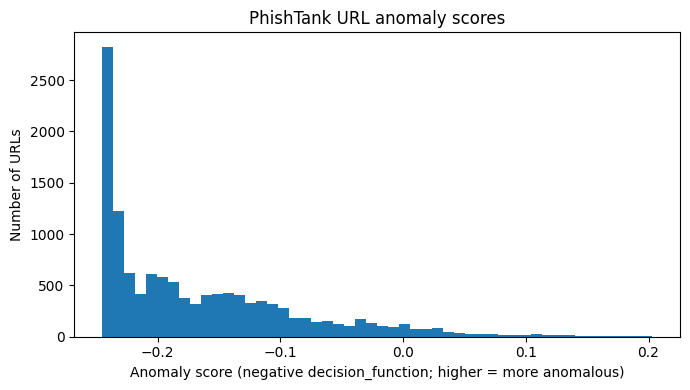


PhishTank feature variance (Section 3.2.1 definitions, unscaled):
      Feature  Variance
   url_length 4028.2776
  digit_count  126.4159
domain_length  121.3546
special_count   11.5716
 hyphen_count    1.6339
    dot_count    0.9377
        https    0.1398
   ip_address    0.0026


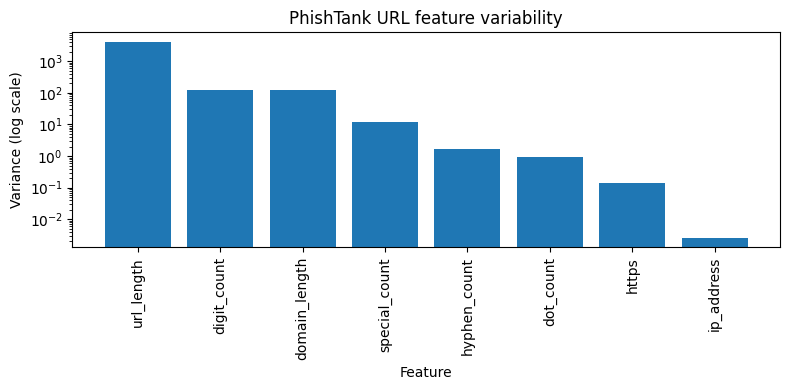


✓ Stream A figures and tables written from the single cell-2/cell-7 pipeline.


In [8]:
# ============================================================
# 6. PHISHTANK FIGURES AND FEATURE VARIABILITY  (VERIFY 3 · C2)
# ============================================================
# One feature function, one model. Everything here reuses:
#   - phish_features  : the eight features from extract_features() (cell 2, Section 3.2.1)
#   - phish_X_scaled  : the StandardScaler matrix (cell 7, Section 3.6.1)
#   - isolation_forest: the contamination = 0.05 model fitted in cell 7
# No second extraction and no second Isolation Forest are fitted.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for _name in ["phish_features", "phish_X_scaled", "isolation_forest", "phishtank"]:
    if _name not in globals():
        raise NameError(f"{_name} is missing: run cells 2 and 7 first.")

phish_X = phish_features[EXPECTED_PHISHTANK_FEATURES].copy()

# Anomaly score = negative of decision_function, so higher = more anomalous.
anomaly_score = -isolation_forest.decision_function(phish_X_scaled)
anomaly_label = pd.Series(isolation_forest.predict(phish_X_scaled)).map({-1: "Anomaly", 1: "Normal"})

phish_results_A = pd.DataFrame({
    "url": phishtank["url"].to_numpy(),
    "anomaly_score": anomaly_score,
    "anomaly_label": anomaly_label.to_numpy(),
})

print("Isolation Forest (cell 7 model, contamination = 0.05):")
print(phish_results_A["anomaly_label"].value_counts().to_string())
print(f"Score range: {anomaly_score.min():.6f} to {anomaly_score.max():.6f}")

# ---- Figure 2: anomaly score distribution -------------------
plt.figure(figsize=(7, 4))
plt.hist(anomaly_score, bins=50)
plt.xlabel("Anomaly score (negative decision_function; higher = more anomalous)")
plt.ylabel("Number of URLs")
plt.title("PhishTank URL anomaly scores")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Figure_PhishTank_Anomaly_Distribution.png", dpi=600, bbox_inches="tight")
plt.show()
plt.close()

# ---- Figure 3 + variance table (unscaled features, Section 3.2.1 definitions)
feature_variance = (
    phish_X.var().sort_values(ascending=False).rename("Variance").reset_index()
)
feature_variance.columns = ["Feature", "Variance"]
print("\nPhishTank feature variance (Section 3.2.1 definitions, unscaled):")
print(feature_variance.round(4).to_string(index=False))

plt.figure(figsize=(8, 4))
plt.bar(feature_variance["Feature"], feature_variance["Variance"])
plt.yscale("log")
plt.xlabel("Feature")
plt.ylabel("Variance (log scale)")
plt.title("PhishTank URL feature variability")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Figure_PhishTank_Feature_Variance.png", dpi=600, bbox_inches="tight")
plt.show()
plt.close()

feature_variance.to_csv(OUTPUT_DIR / "Table_PhishTank_Feature_Variance.csv", index=False)
phish_X.describe().T.reset_index().rename(columns={"index": "Feature"}).to_csv(
    OUTPUT_DIR / "Table_PhishTank_Feature_Statistics.csv", index=False)
phish_results_A.to_csv(OUTPUT_DIR / "Table_PhishTank_Anomaly_Scores.csv", index=False)
pd.DataFrame({
    "Statistic": ["Total URLs", "Normal URLs", "Anomalous URLs", "Anomaly Percentage",
                  "Number of Features", "Isolation Forest Estimators", "Contamination",
                  "Random State", "Scaling"],
    "Value": [len(phish_results_A),
              int((phish_results_A["anomaly_label"] == "Normal").sum()),
              int((phish_results_A["anomaly_label"] == "Anomaly").sum()),
              round(100 * (phish_results_A["anomaly_label"] == "Anomaly").mean(), 2),
              len(EXPECTED_PHISHTANK_FEATURES), isolation_forest.n_estimators,
              isolation_forest.contamination, isolation_forest.random_state, "StandardScaler"],
}).to_csv(OUTPUT_DIR / "Table_PhishTank_IsolationForest_Summary.csv", index=False)
print("\n✓ Stream A figures and tables written from the single cell-2/cell-7 pipeline.")


In [9]:
# ============================================================
# 8. PREPARE THE 30 UCI FEATURES + DUPLICATE/CONFLICT AUDIT
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

print("\n" + "=" * 70)
print("8. UCI FEATURE PREPARATION AND DUPLICATE AUDIT")
print("=" * 70)


# ============================================================
# 8.1 CONFIRMED UCI DATASET
# ============================================================

UCI_PATH = (
    "/kaggle/input/datasets/ceciliaadokomah/dataset-data/uci-ml-phishing-dataset.csv"
)

uci_path = Path(UCI_PATH)

if not uci_path.exists():
    raise FileNotFoundError(
        f"\nUCI dataset not found:\n{uci_path}"
    )

print(f"UCI dataset:\n{uci_path.resolve()}")


# ============================================================
# 8.2 LOAD UCI DATASET
# ============================================================

uci = pd.read_csv(
    uci_path,
    low_memory=False
)

print(
    f"\nLoaded UCI dataset shape: {uci.shape}"
)


# ============================================================
# 8.3 VERIFY RESULT COLUMN
# ============================================================

if "Result" not in uci.columns:
    raise KeyError(
        "\nExpected 'Result' column was not found.\n"
        f"Available columns:\n{list(uci.columns)}"
    )


# ============================================================
# 8.4 CREATE BINARY LABEL
# ============================================================

# UCI convention:
# Result = -1 -> Phishing
# Result != -1 -> Legitimate

uci["label"] = np.where(
    uci["Result"] == -1,
    1,
    0
).astype(np.int8)


# ============================================================
# 8.5 DROP NON-FEATURE COLUMNS
# ============================================================

UCI_DROP_COLUMNS = [
    "id",
    "Result",
    "label"
]

X_uci_raw = uci.drop(
    columns=UCI_DROP_COLUMNS,
    errors="ignore"
).copy()

y_uci = (
    uci["label"]
    .copy()
    .reset_index(drop=True)
)

X_uci_raw = (
    X_uci_raw
    .reset_index(drop=True)
)


# ============================================================
# 8.6 VERIFY EXACTLY 30 FEATURES
# ============================================================

if X_uci_raw.shape[1] != 30:

    raise ValueError(
        "\nExpected exactly 30 UCI features.\n"
        f"Found: {X_uci_raw.shape[1]}\n\n"
        f"Columns found:\n{list(X_uci_raw.columns)}"
    )


print(
    f"\n✓ UCI feature matrix contains "
    f"{X_uci_raw.shape[1]} features."
)

print(
    f"✓ Number of observations: "
    f"{len(X_uci_raw):,}"
)


# ============================================================
# 8.7 CONVERT ALL FEATURES TO NUMERIC
# ============================================================

for column in X_uci_raw.columns:

    X_uci_raw[column] = (
        X_uci_raw[column]
        .astype(str)
        .str.replace(
            "[",
            "",
            regex=False
        )
        .str.replace(
            "]",
            "",
            regex=False
        )
        .str.strip()
    )

    X_uci_raw[column] = pd.to_numeric(
        X_uci_raw[column],
        errors="coerce"
    )


# ============================================================
# 8.8 ORIGINAL DATA SNAPSHOT
# ============================================================

X_uci_original = (
    X_uci_raw
    .copy()
    .reset_index(drop=True)
)

y_uci_original = (
    y_uci
    .copy()
    .reset_index(drop=True)
)


# ============================================================
# 8.9 MISSING-VALUE AUDIT
# ============================================================

original_missing_count = int(
    X_uci_original
    .isna()
    .sum()
    .sum()
)

print(
    f"\nMissing feature values before imputation: "
    f"{original_missing_count:,}"
)


# ============================================================
# 8.10 EXACT DUPLICATE FEATURE AUDIT
# ============================================================

feature_duplicate_count = int(
    X_uci_original
    .duplicated(
        keep="first"
    )
    .sum()
)


# ============================================================
# 8.11 FEATURE + LABEL DUPLICATE AUDIT
# ============================================================

feature_label_frame = (
    X_uci_original
    .copy()
)

feature_label_frame["label"] = (
    y_uci_original
    .to_numpy()
)

feature_label_duplicate_count = int(
    feature_label_frame
    .duplicated(
        keep="first"
    )
    .sum()
)


# ============================================================
# 8.12 IDENTIFY CONFLICTING FEATURE VECTORS
# ============================================================

# A conflicting feature vector is an identical set of 30
# features that occurs with both label 0 and label 1.

feature_label_groups = (
    feature_label_frame
    .groupby(
        list(X_uci_original.columns),
        dropna=False,
        sort=False
    )["label"]
    .nunique()
)

conflicting_groups = (
    feature_label_groups[
        feature_label_groups > 1
    ]
)

conflicting_feature_vectors = int(
    len(conflicting_groups)
)


# ============================================================
# 8.13 IDENTIFY ROWS BELONGING TO CONFLICTING GROUPS
# ============================================================

if conflicting_feature_vectors > 0:

    # Merge the conflicting feature vectors back to the
    # original data to identify every affected observation.

    conflicting_keys = (
        conflicting_groups
        .reset_index()
        .drop(columns=["label"])
    )

    conflicting_rows_df = (
        feature_label_frame
        .merge(
            conflicting_keys,
            on=list(X_uci_original.columns),
            how="inner"
        )
    )

    conflicting_row_count = len(
        conflicting_rows_df
    )

else:

    conflicting_rows_df = pd.DataFrame(
        columns=feature_label_frame.columns
    )

    conflicting_row_count = 0


# ============================================================
# 8.14 DISPLAY DUPLICATE AUDIT
# ============================================================

print("\n" + "-" * 70)
print("UCI DUPLICATE AUDIT")
print("-" * 70)

print(
    f"Original rows: "
    f"{len(X_uci_original):,}"
)

print(
    f"Exact duplicate feature rows: "
    f"{feature_duplicate_count:,}"
)

print(
    f"Exact duplicate feature + label rows: "
    f"{feature_label_duplicate_count:,}"
)

print(
    f"Conflicting feature vectors: "
    f"{conflicting_feature_vectors:,}"
)

print(
    f"Rows involved in conflicting vectors: "
    f"{conflicting_row_count:,}"
)


# ============================================================
# 8.15 SAVE CONFLICTING RECORDS
# ============================================================

if conflicting_feature_vectors > 0:

    conflict_output = (
        OUTPUT_DIR /
        "Table_UCI_Conflicting_Feature_Labels.csv"
    )

    conflicting_rows_df.to_csv(
        conflict_output,
        index=False
    )

    print(
        "\n⚠ Conflicting feature vectors detected."
    )

    print(
        "They have been saved for inspection at:"
    )

    print(
        conflict_output
    )

    print(
        "\nThese records will be excluded from the "
        "final modelling dataset because identical "
        "feature vectors have different target labels."
    )

else:

    print(
        "\n✓ No conflicting feature vectors detected."
    )


# ============================================================
# 8.16 REMOVE CONFLICTING FEATURE VECTORS
# ============================================================

if conflicting_feature_vectors > 0:

    # Build a MultiIndex for reliable matching
    # even when missing values are present.

    original_index = pd.MultiIndex.from_frame(
        X_uci_original
    )

    conflict_index = pd.MultiIndex.from_frame(
        conflicting_rows_df[
            X_uci_original.columns
        ].drop_duplicates()
    )

    conflict_mask = (
        original_index
        .isin(conflict_index)
    )

else:

    conflict_mask = np.zeros(
        len(X_uci_original),
        dtype=bool
    )


X_uci_nonconflicting = (
    X_uci_original[
        ~conflict_mask
    ]
    .reset_index(drop=True)
)

y_uci_nonconflicting = (
    y_uci_original[
        ~conflict_mask
    ]
    .reset_index(drop=True)
)


rows_removed_conflicts = int(
    conflict_mask.sum()
)


# ============================================================
# 8.17 REMOVE REMAINING EXACT DUPLICATE FEATURE ROWS
# ============================================================

duplicate_keep_mask = (
    ~X_uci_nonconflicting
    .duplicated(
        keep="first"
    )
)

X_uci_raw = (
    X_uci_nonconflicting[
        duplicate_keep_mask
    ]
    .reset_index(drop=True)
)

y_uci = (
    y_uci_nonconflicting[
        duplicate_keep_mask
    ]
    .reset_index(drop=True)
)


rows_removed_duplicates = int(
    (
        ~duplicate_keep_mask
    ).sum()
)


# ============================================================
# 8.18 FINAL DATASET VALIDATION
# ============================================================

if len(X_uci_raw) != len(y_uci):

    raise ValueError(
        "Final UCI feature matrix and label vector "
        "are not aligned."
    )


if X_uci_raw.shape[1] != 30:

    raise ValueError(
        f"Final UCI feature matrix contains "
        f"{X_uci_raw.shape[1]} features instead of 30."
    )


if not y_uci.isin([0, 1]).all():

    raise ValueError(
        "Final UCI labels contain values other than "
        "0 and 1."
    )


# ============================================================
# 8.19 FINAL DUPLICATE CHECK
# ============================================================

remaining_feature_duplicates = int(
    X_uci_raw
    .duplicated()
    .sum()
)

final_feature_label_frame = (
    X_uci_raw.copy()
)

final_feature_label_frame["label"] = (
    y_uci.to_numpy()
)

remaining_feature_label_duplicates = int(
    final_feature_label_frame
    .duplicated()
    .sum()
)


if remaining_feature_duplicates > 0:

    raise ValueError(
        "Duplicate feature rows remain after cleaning."
    )


# ============================================================
# 8.20 FINAL UCI CLASS COUNTS
# ============================================================

final_legitimate = int(
    (y_uci == 0).sum()
)

final_phishing = int(
    (y_uci == 1).sum()
)

final_total = len(
    y_uci
)


print("\n" + "=" * 70)
print("FINAL UCI MODELLING DATASET")
print("=" * 70)

print(
    f"Rows before cleaning: "
    f"{len(X_uci_original):,}"
)

print(
    f"Conflicting rows removed: "
    f"{rows_removed_conflicts:,}"
)

print(
    f"Additional duplicate rows removed: "
    f"{rows_removed_duplicates:,}"
)

print(
    f"Final rows: "
    f"{final_total:,}"
)

print(
    f"Final features: "
    f"{X_uci_raw.shape[1]}"
)

print(
    f"Legitimate: "
    f"{final_legitimate:,}"
)

print(
    f"Phishing: "
    f"{final_phishing:,}"
)

print(
    f"Remaining duplicate feature rows: "
    f"{remaining_feature_duplicates}"
)


# ============================================================
# 8.21 SAVE COMPLETE DUPLICATE AUDIT
# ============================================================

duplicate_audit = pd.DataFrame({

    "Audit_Item": [

        "Original UCI rows",

        "Original UCI features",

        "Exact duplicate feature rows",

        "Exact duplicate feature+label rows",

        "Conflicting-label feature vectors",

        "Rows involved in conflicting vectors",

        "Rows removed due to conflicting labels",

        "Additional duplicate rows removed",

        "Final UCI modelling rows",

        "Final UCI features",

        "Legitimate rows after cleaning",

        "Phishing rows after cleaning",

        "Missing values before imputation",

        "Remaining duplicate feature rows",

        "Remaining duplicate feature+label rows"

    ],

    "Count": [

        len(X_uci_original),

        X_uci_original.shape[1],

        feature_duplicate_count,

        feature_label_duplicate_count,

        conflicting_feature_vectors,

        conflicting_row_count,

        rows_removed_conflicts,

        rows_removed_duplicates,

        final_total,

        X_uci_raw.shape[1],

        final_legitimate,

        final_phishing,

        original_missing_count,

        remaining_feature_duplicates,

        remaining_feature_label_duplicates

    ]

})


duplicate_audit_path = (
    OUTPUT_DIR /
    "Table_UCI_Duplicate_Audit.csv"
)

duplicate_audit.to_csv(
    duplicate_audit_path,
    index=False
)

print(
    f"\n✓ Duplicate audit saved:\n"
    f"{duplicate_audit_path}"
)


# ============================================================
# 8.22 FINAL FEATURE LIST
# ============================================================

print("\nFinal 30 UCI features:")

for number, feature in enumerate(
    X_uci_raw.columns,
    start=1
):

    print(
        f"{number:02d}. {feature}"
    )


# ============================================================
# 9. CORE XGBOOST MODEL FUNCTIONS
# ============================================================

print("\n" + "=" * 70)
print("9. CORE XGBOOST MODEL FUNCTIONS")
print("=" * 70)


# ============================================================
# 9.1 METRIC DEFINITIONS
# ============================================================

METRIC_COLUMNS = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]


# ============================================================
# 9.2 XGBOOST MODEL FACTORY
# ============================================================

def make_xgb(
    seed,
    max_depth=6
):
    """
    Create a reproducible XGBoost classifier.
    """

    params = XGB_PARAMS.copy()

    params["random_state"] = seed
    params["max_depth"] = max_depth

    return XGBClassifier(
        **params
    )


# ============================================================
# 9.3 MODEL EVALUATION
# ============================================================

def evaluate_predictions(
    y_true,
    y_pred,
    y_prob
):
    """
    Calculate classification performance metrics.
    """

    return {

        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "F1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true,
            y_prob
        )
    }


# ============================================================
# 9.4 SINGLE-SEED EXPERIMENT
# ============================================================

def run_single_seed(
    seed,
    use_smote=True,
    max_depth=6,
    X_data=None,
    y_data=None
):
    """
    Execute one reproducible XGBoost experiment.

    Processing order:

    1. Stratified train/test split
    2. Median imputation using training data only
    3. Optional SMOTE using training data only
    4. XGBoost training
    5. Test-set prediction
    6. Metric calculation

    This prevents test-set leakage.
    """

    # --------------------------------------------------------
    # Default to cleaned UCI dataset
    # --------------------------------------------------------

    if X_data is None:
        X_data = X_uci_raw

    if y_data is None:
        y_data = y_uci


    # --------------------------------------------------------
    # Convert labels to NumPy-compatible form
    # --------------------------------------------------------

    if isinstance(y_data, pd.Series):

        y_data = y_data.reset_index(
            drop=True
        )


    # --------------------------------------------------------
    # Validate dimensions
    # --------------------------------------------------------

    if len(X_data) != len(y_data):

        raise ValueError(
            "X_data and y_data have different "
            "numbers of observations."
        )


    # --------------------------------------------------------
    # Stratified train/test split
    # --------------------------------------------------------

    (
        X_train_raw,
        X_test_raw,
        y_train,
        y_test
    ) = train_test_split(

        X_data,

        y_data,

        test_size=0.20,

        stratify=y_data,

        random_state=seed
    )


    # --------------------------------------------------------
    # Median imputation
    # --------------------------------------------------------

    imputer = SimpleImputer(
        strategy="median"
    )


    missing_train = int(
        X_train_raw
        .isna()
        .sum()
        .sum()
    )

    missing_test = int(
        X_test_raw
        .isna()
        .sum()
        .sum()
    )


    X_train = pd.DataFrame(

        imputer.fit_transform(
            X_train_raw
        ),

        columns=X_train_raw.columns,

        index=X_train_raw.index
    )


    X_test = pd.DataFrame(

        imputer.transform(
            X_test_raw
        ),

        columns=X_test_raw.columns,

        index=X_test_raw.index
    )


    # --------------------------------------------------------
    # Verify no missing values remain
    # --------------------------------------------------------

    if X_train.isna().any().any():

        raise ValueError(
            "Missing values remain in training data "
            "after median imputation."
        )


    if X_test.isna().any().any():

        raise ValueError(
            "Missing values remain in test data "
            "after median imputation."
        )


    # --------------------------------------------------------
    # SMOTE on training data only
    # --------------------------------------------------------

    if use_smote:

        smote = SMOTE(
            random_state=seed
        )

        (
            X_train_model,
            y_train_model
        ) = smote.fit_resample(

            X_train,

            y_train
        )

    else:

        X_train_model = X_train

        y_train_model = y_train


    # --------------------------------------------------------
    # Train XGBoost
    # --------------------------------------------------------

    model = make_xgb(
        seed=seed,
        max_depth=max_depth
    )


    model.fit(

        X_train_model,

        y_train_model,

        verbose=False
    )


    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test
    )

    y_prob = model.predict_proba(
        X_test
    )[:, 1]


    # --------------------------------------------------------
    # Evaluation
    # --------------------------------------------------------

    metrics = evaluate_predictions(

        y_test,

        y_pred,

        y_prob
    )


    # --------------------------------------------------------
    # Return experiment results
    # --------------------------------------------------------

    return {

        "seed": seed,

        "model": model,

        "imputer": imputer,

        "X_train": X_train_model,

        "y_train": y_train_model,

        "X_test": X_test,

        "y_test": y_test,

        "y_pred": y_pred,

        "y_prob": y_prob,

        "metrics": metrics,

        "missing_train": missing_train,

        "missing_test": missing_test

    }


print(
    "\n✓ XGBoost functions successfully defined."
)

print(
    "✓ 30 UCI features verified."
)

print(
    "✓ Conflicting feature/label records handled."
)

print(
    "✓ Exact duplicates audited and removed."
)

print(
    "✓ Median imputation is fitted on training data only."
)

print(
    "✓ SMOTE is applied to training data only."
)

print(
    "✓ The test partition is not passed to any fit() call "
    "(no eval_set, no early stopping); it is used only for scoring."
)


8. UCI FEATURE PREPARATION AND DUPLICATE AUDIT
UCI dataset:
/kaggle/input/datasets/ceciliaadokomah/dataset-data/uci-ml-phishing-dataset.csv

Loaded UCI dataset shape: (11055, 32)

✓ UCI feature matrix contains 30 features.
✓ Number of observations: 11,055

Missing feature values before imputation: 0

----------------------------------------------------------------------
UCI DUPLICATE AUDIT
----------------------------------------------------------------------
Original rows: 11,055
Exact duplicate feature rows: 5,270
Exact duplicate feature + label rows: 5,206
Conflicting feature vectors: 64
Rows involved in conflicting vectors: 357

⚠ Conflicting feature vectors detected.
They have been saved for inspection at:
revised_outputs/Table_UCI_Conflicting_Feature_Labels.csv

These records will be excluded from the final modelling dataset because identical feature vectors have different target labels.

FINAL UCI MODELLING DATASET
Rows before cleaning: 11,055
Conflicting rows removed: 357
Addi

In [10]:
# ============================================================
# 4B. UCI FEATURE INVENTORY RECONCILIATION
# ============================================================

# Keep the actual 30-feature schema as the single source of truth.
feature_inventory = pd.DataFrame({
    "Feature_Number": np.arange(1, len(X_uci_raw.columns) + 1),
    "Feature": X_uci_raw.columns
})
assert len(feature_inventory) == 30
feature_inventory.to_csv(OUTPUT_DIR / "Table_UCI_30_Feature_Inventory.csv", index=False)
print("Verified UCI feature count:", len(feature_inventory))
print(feature_inventory.to_string(index=False))

Verified UCI feature count: 30
 Feature_Number                     Feature
              1           having_IP_Address
              2                  URL_Length
              3          Shortining_Service
              4            having_At_Symbol
              5    double_slash_redirecting
              6               Prefix_Suffix
              7           having_Sub_Domain
              8              SSLfinal_State
              9 Domain_registeration_length
             10                     Favicon
             11                        port
             12                 HTTPS_token
             13                 Request_URL
             14               URL_of_Anchor
             15               Links_in_tags
             16                         SFH
             17         Submitting_to_email
             18                Abnormal_URL
             19                    Redirect
             20                on_mouseover
             21                  RightClick
 

In [11]:
# ============================================================
# 10. FIVE-SEED XGBOOST: ORIGINAL VS DE-DUPLICATED DATA
# ============================================================

legacy_rows = []
for seed in SEEDS:
    result = run_single_seed(
        seed=seed,
        use_smote=True,
        max_depth=6,
        X_data=X_uci_original,
        y_data=y_uci_original
    )
    row = {"Seed": seed}
    row.update(result["metrics"])
    legacy_rows.append(row)

legacy_xgb_results = pd.DataFrame(legacy_rows)

xgb_runs = []
xgb_metric_rows = []

for seed in SEEDS:
    result = run_single_seed(
        seed=seed,
        use_smote=True,
        max_depth=6
    )
    xgb_runs.append(result)

    row = {"Seed": seed}
    row.update(result["metrics"])
    xgb_metric_rows.append(row)

xgb_runs_df = pd.DataFrame(xgb_metric_rows)

legacy_summary = legacy_xgb_results[METRIC_COLUMNS].agg(["mean", "std"]).T
dedup_summary = xgb_runs_df[METRIC_COLUMNS].agg(["mean", "std"]).T

dedup_comparison = pd.DataFrame({
    "Original_Mean": legacy_summary["mean"],
    "Original_SD": legacy_summary["std"],
    "Deduplicated_Mean": dedup_summary["mean"],
    "Deduplicated_SD": dedup_summary["std"]
})

print("Original five-seed results:")
print(legacy_xgb_results.round(4))
print("\nDe-duplicated five-seed results:")
print(xgb_runs_df.round(4))
print("\nOriginal vs de-duplicated summary:")
print(dedup_comparison.round(4))

legacy_xgb_results.to_csv(
    OUTPUT_DIR / "Table_XGBoost_Original_Five_Seed_Results.csv",
    index=False
)
xgb_runs_df.to_csv(
    OUTPUT_DIR / "Table_XGBoost_Deduplicated_Five_Seed_Results.csv",
    index=False
)
dedup_comparison.to_csv(
    OUTPUT_DIR / "Table_XGBoost_Original_vs_Deduplicated.csv"
)

print("\nAll configured five-seed XGBoost runs completed: YES")

Original five-seed results:
   Seed  Accuracy  Precision  Recall      F1  ROC-AUC
0    42    0.9692     0.9711  0.9592  0.9651   0.9962
1     7    0.9711     0.9683  0.9663  0.9673   0.9970
2   123    0.9665     0.9494  0.9765  0.9628   0.9971
3  2024    0.9674     0.9690  0.9571  0.9630   0.9959
4    99    0.9683     0.9643  0.9643  0.9643   0.9963

De-duplicated five-seed results:
   Seed  Accuracy  Precision  Recall      F1  ROC-AUC
0    42    0.9694     0.9760  0.9645  0.9702   0.9949
1     7    0.9694     0.9760  0.9645  0.9702   0.9965
2   123    0.9703     0.9665  0.9763  0.9714   0.9967
3  2024    0.9721     0.9713  0.9746  0.9730   0.9955
4    99    0.9651     0.9584  0.9746  0.9664   0.9961

Original vs de-duplicated summary:
           Original_Mean  Original_SD  Deduplicated_Mean  Deduplicated_SD
Accuracy          0.9685       0.0017             0.9693           0.0026
Precision         0.9644       0.0087             0.9697           0.0074
Recall            0.9647       0

In [12]:
# ============================================================
# 11. BASELINE MODELS UNDER THE SAME PROTOCOL
# ============================================================

def run_baselines_for_seed(seed):
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_uci_raw,
        y_uci,
        test_size=0.20,
        stratify=y_uci,
        random_state=seed
    )

    imputer = SimpleImputer(strategy="median")
    X_train = imputer.fit_transform(X_train_raw)
    X_test = imputer.transform(X_test_raw)

    smote = SMOTE(random_state=seed)
    X_train_bal, y_train_bal = smote.fit_resample(
        X_train, y_train
    )

    models = {
        "Logistic Regression": LogisticRegression(
            max_iter=2000,
            solver="lbfgs",
            random_state=seed
        ),
        "Decision Tree": DecisionTreeClassifier(
            random_state=seed
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            random_state=seed,
            n_jobs=-1
        ),
        "XGBoost": make_xgb(seed, max_depth=6)
    }

    rows = []

    for name, clf in models.items():
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            clf.fit(X_train_bal, y_train_bal)

        convergence_warning = any(
            "converg" in str(w.message).lower()
            for w in caught
        )

        pred = clf.predict(X_test)
        if hasattr(clf, "predict_proba"):
            prob = clf.predict_proba(X_test)[:, 1]
        else:
            prob = clf.decision_function(X_test)

        row = {
            "Seed": seed,
            "Model": name,
            "Convergence_Warning": convergence_warning
        }
        row.update(evaluate_predictions(y_test, pred, prob))
        rows.append(row)

    return rows

baseline_rows = []
for seed in SEEDS:
    baseline_rows.extend(run_baselines_for_seed(seed))

baseline_results = pd.DataFrame(baseline_rows)

print("Baseline results by seed:")
print(baseline_results.round(4))

print("\nLogistic Regression convergence warnings:")
print(
    baseline_results.loc[
        baseline_results["Model"] == "Logistic Regression",
        ["Seed", "Convergence_Warning"]
    ].to_string(index=False)
)

baseline_summary = (
    baseline_results
    .groupby("Model")[METRIC_COLUMNS]
    .agg(["mean", "std"])
)

print("\nBaseline Mean ± SD:")
print(baseline_summary.round(4))

baseline_results.to_csv(
    OUTPUT_DIR / "baseline_results_by_seed.csv",
    index=False
)
baseline_summary.to_csv(
    OUTPUT_DIR / "baseline_summary_mean_sd.csv"
)

Baseline results by seed:
    Seed                Model  Convergence_Warning  Accuracy  Precision  \
0     42  Logistic Regression                False    0.9118     0.9181   
1     42        Decision Tree                False    0.9432     0.9473   
2     42        Random Forest                False    0.9624     0.9724   
3     42              XGBoost                False    0.9694     0.9760   
4      7  Logistic Regression                False    0.9476     0.9601   
5      7        Decision Tree                False    0.9502     0.9495   
6      7        Random Forest                False    0.9694     0.9810   
7      7              XGBoost                False    0.9694     0.9760   
8    123  Logistic Regression                False    0.9258     0.9274   
9    123        Decision Tree                False    0.9520     0.9482   
10   123        Random Forest                False    0.9677     0.9727   
11   123              XGBoost                False    0.9703     0.9665   

In [13]:
# ============================================================
# 12. EXTENDED TREE-DEPTH SEARCH + LEAKAGE-FREE FINAL MODEL
# ============================================================

depth_rows = []

for seed in SEEDS:
    for depth in DEPTH_CANDIDATES:
        result = run_single_seed(
            seed=seed,
            use_smote=True,
            max_depth=depth
        )

        row = {
            "Seed": seed,
            "Max_Depth": depth
        }
        row.update(result["metrics"])
        depth_rows.append(row)

depth_search = pd.DataFrame(depth_rows)

depth_summary = (
    depth_search
    .groupby("Max_Depth")[METRIC_COLUMNS]
    .agg(["mean", "std"])
)

depth_summary_flat = depth_summary.copy()
depth_summary_flat.columns = [
    f"{metric}_{stat}"
    for metric, stat in depth_summary_flat.columns
]
depth_summary_flat = depth_summary_flat.reset_index()

print("Extended depth search (SMOTE retained for direct ablation comparability):")
print(depth_summary_flat.round(4))

depth_search.to_csv(
    OUTPUT_DIR / "Table_Extended_Tree_Depth_Search_Per_Seed.csv",
    index=False
)
depth_summary_flat.to_csv(
    OUTPUT_DIR / "Table_Extended_Tree_Depth_Search_Summary.csv",
    index=False
)

# Select by mean F1, then ROC-AUC, then accuracy. This avoids calling a
# configuration "optimised" before the extended grid has actually been run.
ranked_depths = depth_summary_flat.sort_values(
    by=["F1_mean", "ROC-AUC_mean", "Accuracy_mean"],
    ascending=False
).reset_index(drop=True)

SELECTED_DEPTH = int(ranked_depths.loc[0, "Max_Depth"])

best_depth_row = depth_summary_flat.loc[
    depth_summary_flat["Max_Depth"] == SELECTED_DEPTH
].iloc[0]

max_depth_observed = max(DEPTH_CANDIDATES)
# True only if the best depth is the largest candidate tried, i.e. the
# search may not have reached its turning point. (The previous version
# compared the upper-bound F1 with the maximum F1 and then discarded the
# result with a constant `if False else False`.)
still_improving_at_upper_bound = (SELECTED_DEPTH == max_depth_observed)

print("\nSelected depth:", SELECTED_DEPTH)
print("Selection basis: highest mean F1, then ROC-AUC, then accuracy.")

# The final reference model is deliberately vanilla: exact duplicates removed,
# SMOTE disabled, and the selected depth retained. SHAP/LIME are post-hoc and
# therefore do not enter the classifier's prediction function.
final_runs = []

for seed in SEEDS:
    final_runs.append(
        run_single_seed(
            seed=seed,
            use_smote=False,
            max_depth=SELECTED_DEPTH
        )
    )

final_runs_df = pd.DataFrame([
    {"Seed": r["seed"], **r["metrics"]}
    for r in final_runs
])

final_summary = pd.DataFrame({
    "Mean": final_runs_df[METRIC_COLUMNS].mean(),
    "SD": final_runs_df[METRIC_COLUMNS].std(ddof=1)
})

print("\nLeakage-free vanilla final-model results:")
print(final_runs_df.round(4))
print("\nLeakage-free vanilla final-model Mean ± SD:")
print(final_summary.round(4))

final_run = next(r for r in final_runs if r["seed"] == 42)

final_model = final_run["model"]
final_imputer = final_run["imputer"]
X_train_final = final_run["X_train"]
y_train_final = final_run["y_train"]
X_test_final = final_run["X_test"]
y_test_final = final_run["y_test"]
y_pred_final = final_run["y_pred"]
y_prob_final = final_run["y_prob"]

final_runs_df.to_csv(
    OUTPUT_DIR / "Table_Final_Vanilla_Five_Seed_Results.csv",
    index=False
)
final_summary.to_csv(
    OUTPUT_DIR / "Table_Final_Vanilla_Mean_SD.csv"
)

actual_params = final_model.get_params()
with open(
    OUTPUT_DIR / "xgboost_final_parameters.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            key: actual_params.get(key)
            for key in [
                "n_estimators", "learning_rate", "max_depth",
                "subsample", "colsample_bytree", "reg_lambda",
                "objective", "eval_metric", "random_state"
            ]
        },
        f,
        indent=2
    )

print("\nSeed-42 final metrics:")
print(pd.Series(final_run["metrics"]).round(4))

Extended depth search (SMOTE retained for direct ablation comparability):
   Max_Depth  Accuracy_mean  Accuracy_std  Precision_mean  Precision_std  \
0          3         0.9597        0.0033          0.9630         0.0067   
1          6         0.9693        0.0026          0.9697         0.0074   
2          9         0.9686        0.0012          0.9699         0.0057   
3         12         0.9682        0.0029          0.9696         0.0059   
4         15         0.9684        0.0023          0.9696         0.0058   

   Recall_mean  Recall_std  F1_mean  F1_std  ROC-AUC_mean  ROC-AUC_std  
0       0.9587      0.0052   0.9608  0.0032        0.9931       0.0009  
1       0.9709      0.0059   0.9702  0.0024        0.9960       0.0007  
2       0.9692      0.0040   0.9695  0.0011        0.9961       0.0006  
3       0.9689      0.0068   0.9692  0.0028        0.9960       0.0006  
4       0.9692      0.0064   0.9694  0.0022        0.9960       0.0006  

Selected depth: 6
Selection ba

In [14]:
# ============================================================
# 12B. DEPTH TURNING-POINT DIAGNOSTIC
# ============================================================

ordered_depths = depth_summary_flat.sort_values("Max_Depth")
f1_values = ordered_depths["F1_mean"].to_numpy()
depths = ordered_depths["Max_Depth"].to_numpy()
turning_depth = None
for k in range(1, len(f1_values) - 1):
    if f1_values[k] >= f1_values[k-1] and f1_values[k] >= f1_values[k+1]:
        turning_depth = int(depths[k])
        break

upper_bound_still_improving = bool(f1_values[-1] > f1_values[-2])
print("Depth turning-point diagnostic:")
print("Upper bound:", int(depths[-1]))
print("F1 at upper bound still improving over previous depth:", upper_bound_still_improving)
print("Observed interior turning depth:", turning_depth)

pd.DataFrame({
    "Upper_Bound": [int(depths[-1])],
    "Upper_Bound_Still_Improving": [upper_bound_still_improving],
    "Observed_Interior_Turning_Depth": [turning_depth]
}).to_csv(OUTPUT_DIR / "Table_Depth_Turning_Point_Diagnostic.csv", index=False)

Depth turning-point diagnostic:
Upper bound: 15
F1 at upper bound still improving over previous depth: True
Observed interior turning depth: 6


In [15]:
# ============================================================
# 14. CONTROLLED CLASSIFIER COMPARISON TABLE
# ============================================================

# "Baseline" refers only to the comparison classifiers below.
# XGBoost is the study classifier. SHAP and LIME are post-hoc explainers
# and cannot change predictions; therefore this table is a classifier-
# selection experiment, not a test of an XAI performance contribution.

controlled_table = (
    baseline_results
    .groupby("Model")[METRIC_COLUMNS]
    .agg(["mean", "std"])
)

def mean_sd(mean, sd):
    return f"{mean:.4f} ± {sd:.4f}"

formatted_rows = []

for model_name, row in controlled_table.iterrows():
    formatted_rows.append({
        "Model": model_name,
        "Accuracy": mean_sd(row[("Accuracy", "mean")], row[("Accuracy", "std")]),
        "Precision": mean_sd(row[("Precision", "mean")], row[("Precision", "std")]),
        "Recall": mean_sd(row[("Recall", "mean")], row[("Recall", "std")]),
        "F1": mean_sd(row[("F1", "mean")], row[("F1", "std")]),
        "ROC-AUC": mean_sd(row[("ROC-AUC", "mean")], row[("ROC-AUC", "std")])
    })

controlled_table_formatted = pd.DataFrame(formatted_rows)

print(controlled_table_formatted)

controlled_table_formatted.to_csv(
    OUTPUT_DIR / "Table_Controlled_Classifier_Comparison.csv",
    index=False
)

baseline_parameter_table = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Parameters": "max_iter=2000; solver=lbfgs; random_state=seed",
        "Tuning_Budget": "Fixed configuration; no grid search"
    },
    {
        "Model": "Decision Tree",
        "Parameters": "random_state=seed",
        "Tuning_Budget": "Fixed configuration; no grid search"
    },
    {
        "Model": "Random Forest",
        "Parameters": "n_estimators=100; random_state=seed; n_jobs=-1",
        "Tuning_Budget": "Fixed configuration; no grid search"
    },
    {
        "Model": "XGBoost",
        "Parameters": "500 estimators; learning_rate=0.03; max_depth=6; subsample=0.8; colsample_bytree=0.8; reg_lambda=1.0",
        "Tuning_Budget": "Depth ablation extended to 15; other parameters fixed"
    }
])

print("\nBaseline/classifier parameter specification:")
print(baseline_parameter_table.to_string(index=False))

baseline_parameter_table.to_csv(
    OUTPUT_DIR / "Table_Classifier_Parameter_Specification.csv",
    index=False
)

                 Model         Accuracy        Precision           Recall  \
0        Decision Tree  0.9462 ± 0.0060  0.9446 ± 0.0073  0.9516 ± 0.0066   
1  Logistic Regression  0.9303 ± 0.0133  0.9369 ± 0.0160  0.9276 ± 0.0132   
2        Random Forest  0.9659 ± 0.0030  0.9730 ± 0.0066  0.9607 ± 0.0047   
3              XGBoost  0.9693 ± 0.0026  0.9697 ± 0.0074  0.9709 ± 0.0059   

                F1          ROC-AUC  
0  0.9481 ± 0.0058  0.9460 ± 0.0061  
1  0.9322 ± 0.0129  0.9809 ± 0.0029  
2  0.9668 ± 0.0028  0.9950 ± 0.0008  
3  0.9702 ± 0.0024  0.9960 ± 0.0007  

Baseline/classifier parameter specification:
              Model                                                                                           Parameters                                         Tuning_Budget
Logistic Regression                                                       max_iter=2000; solver=lbfgs; random_state=seed                   Fixed configuration; no grid search
      Decision Tree         


CONFUSION MATRIX

Raw confusion matrix:
                   Predicted Legitimate  Predicted Phishing
Actual Legitimate                   541                  13
Actual Phishing                      25                 566

TN: 541
FP: 13
FN: 25
TP: 566


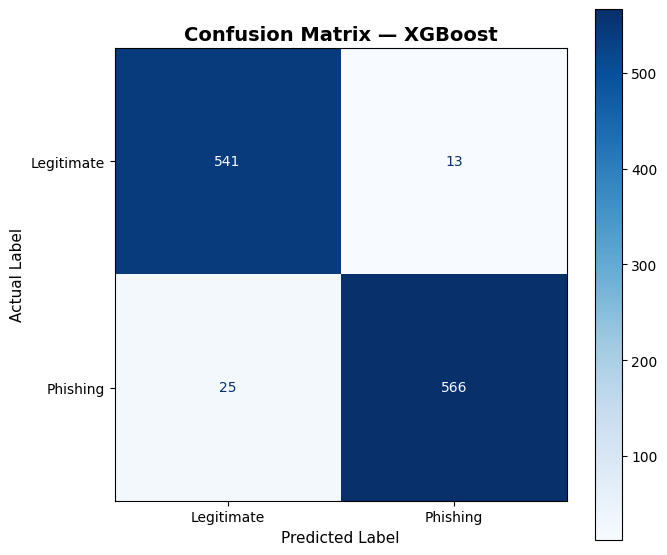


✓ Confusion matrix figure saved to:
revised_outputs/Figure_Confusion_Matrix_XGBoost.png


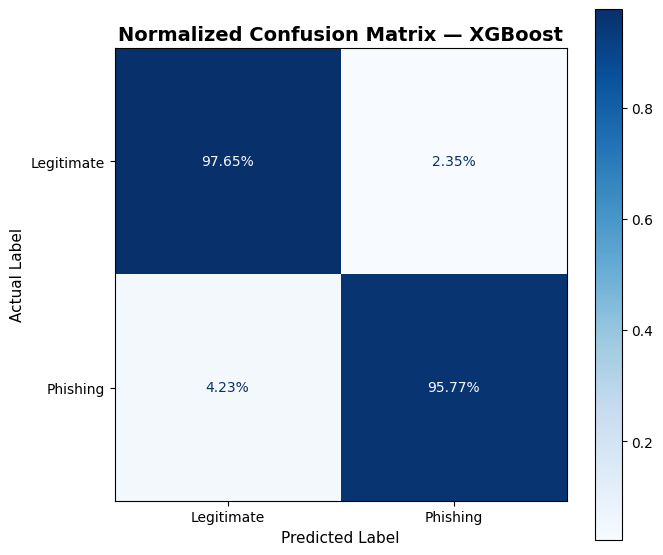

✓ Normalized confusion matrix saved to:
revised_outputs/Figure_Confusion_Matrix_XGBoost_Normalized.png

BEHAVIOURAL ERROR ANALYSIS
Among legitimate websites, 97.65% were correctly classified as legitimate and 2.35% were classified as phishing.
Among phishing websites, 95.77% were correctly classified as phishing and 4.23% were classified as legitimate.

Error counts:
False Positives (legitimate → phishing): 13
False Negatives (phishing → legitimate): 25
True Negatives (legitimate → legitimate): 541
True Positives (phishing → phishing): 566

CLASSIFICATION PERFORMANCE
Accuracy         : 0.9668
Phishing Recall  : 0.9577
Phishing Precision: 0.9775
F1-Score         : 0.9675
ROC-AUC          : 0.9950

Interpretation rule: AUC is a threshold-independent ranking measure; it is not described as perfect discrimination unless it equals 1.0. False negatives and false positives are reported explicitly because their real-world costs differ.


<Figure size 700x500 with 0 Axes>

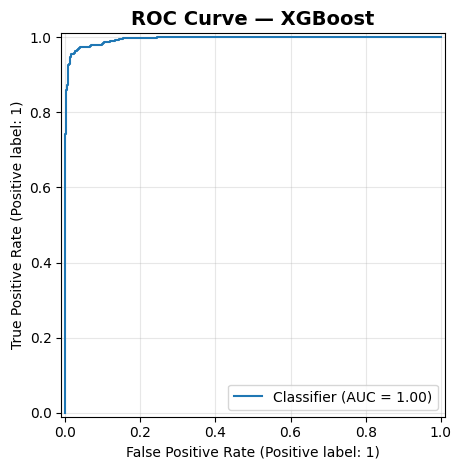


Multi-seed stability data:
    Seed     Metric   Score
0     42   Accuracy  0.9668
1      7   Accuracy  0.9694
2    123   Accuracy  0.9686
3   2024   Accuracy  0.9721
4     99   Accuracy  0.9668
5     42  Precision  0.9775
6      7  Precision  0.9760
7    123  Precision  0.9648
8   2024  Precision  0.9713
9     99  Precision  0.9616
10    42     Recall  0.9577
11     7     Recall  0.9645
12   123     Recall  0.9746
13  2024     Recall  0.9746
14    99     Recall  0.9746
15    42         F1  0.9675
16     7         F1  0.9702
17   123         F1  0.9697
18  2024         F1  0.9730
19    99         F1  0.9681
20    42    ROC-AUC  0.9950
21     7    ROC-AUC  0.9964
22   123    ROC-AUC  0.9966
23  2024    ROC-AUC  0.9956
24    99    ROC-AUC  0.9961


<Figure size 900x500 with 0 Axes>

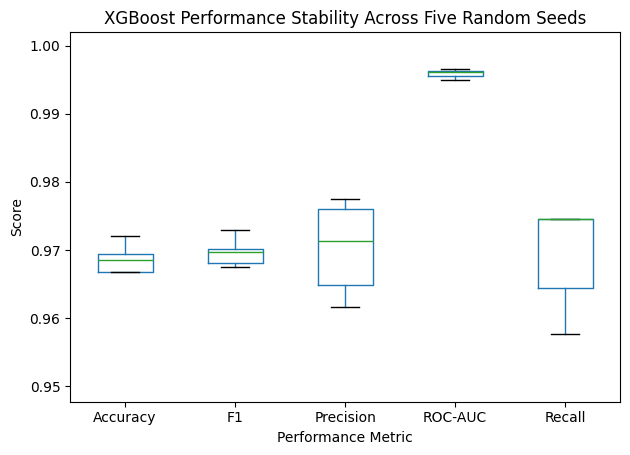

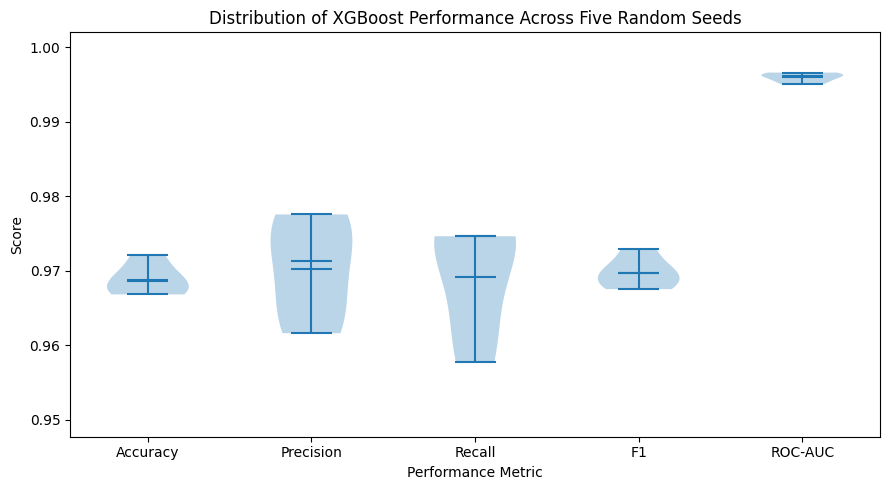


ALL EVALUATION OUTPUTS SAVED
✓ Raw confusion matrix table
✓ Raw confusion matrix figure
✓ Normalized confusion matrix figure
✓ Behavioural error-count table
✓ ROC curve
✓ Multi-seed boxplot
✓ Multi-seed violin plot
✓ Multi-seed summary table


In [16]:
# ============================================================
# 17. CONFUSION MATRIX + BEHAVIOURAL ERROR COUNTS
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

# ------------------------------------------------------------
# 17.1 RAW CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test_final,
    y_pred_final,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()


# ------------------------------------------------------------
# 17.2 NORMALIZED CONFUSION MATRIX
# ------------------------------------------------------------

cm_normalized = confusion_matrix(
    y_test_final,
    y_pred_final,
    labels=[0, 1],
    normalize="true"
)


# ------------------------------------------------------------
# 17.3 CONFUSION MATRIX TABLE
# ------------------------------------------------------------

cm_table = pd.DataFrame(
    cm,
    index=[
        "Actual Legitimate",
        "Actual Phishing"
    ],
    columns=[
        "Predicted Legitimate",
        "Predicted Phishing"
    ]
)


print("\n" + "=" * 80)
print("CONFUSION MATRIX")
print("=" * 80)

print("\nRaw confusion matrix:")
print(cm_table)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)


# ------------------------------------------------------------
# 17.4 SAVE RAW CONFUSION MATRIX TABLE
# ------------------------------------------------------------

cm_table.to_csv(
    OUTPUT_DIR /
    "Table_Confusion_Matrix_Raw.csv"
)


# ============================================================
# 17.5 CONFUSION MATRIX DIAGRAM — RAW COUNTS
# ============================================================

plt.figure(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Legitimate",
        "Phishing"
    ]
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=plt.gca(),
    colorbar=True
)

plt.title(
    "Confusion Matrix — XGBoost",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Predicted Label",
    fontsize=11
)

plt.ylabel(
    "Actual Label",
    fontsize=11
)

plt.tight_layout()

confusion_matrix_figure = (
    OUTPUT_DIR /
    "Figure_Confusion_Matrix_XGBoost.png"
)

plt.savefig(
    confusion_matrix_figure,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()


print(
    f"\n✓ Confusion matrix figure saved to:\n"
    f"{confusion_matrix_figure}"
)


# ============================================================
# 17.6 NORMALIZED CONFUSION MATRIX DIAGRAM
# ============================================================

plt.figure(
    figsize=(7, 6)
)

disp_normalized = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=[
        "Legitimate",
        "Phishing"
    ]
)

disp_normalized.plot(
    cmap="Blues",
    values_format=".2%",
    ax=plt.gca(),
    colorbar=True
)

plt.title(
    "Normalized Confusion Matrix — XGBoost",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Predicted Label",
    fontsize=11
)

plt.ylabel(
    "Actual Label",
    fontsize=11
)

plt.tight_layout()

normalized_cm_figure = (
    OUTPUT_DIR /
    "Figure_Confusion_Matrix_XGBoost_Normalized.png"
)

plt.savefig(
    normalized_cm_figure,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()


print(
    f"✓ Normalized confusion matrix saved to:\n"
    f"{normalized_cm_figure}"
)


# ============================================================
# 17.7 BEHAVIOURAL ERROR RATES
# ============================================================

legitimate_correct = (
    cm_normalized[0, 0] * 100
)

legitimate_misclassified = (
    cm_normalized[0, 1] * 100
)

phishing_correct = (
    cm_normalized[1, 1] * 100
)

phishing_misclassified = (
    cm_normalized[1, 0] * 100
)


print("\n" + "=" * 80)
print("BEHAVIOURAL ERROR ANALYSIS")
print("=" * 80)

print(
    f"Among legitimate websites, "
    f"{legitimate_correct:.2f}% were correctly "
    f"classified as legitimate and "
    f"{legitimate_misclassified:.2f}% were "
    f"classified as phishing."
)

print(
    f"Among phishing websites, "
    f"{phishing_correct:.2f}% were correctly "
    f"classified as phishing and "
    f"{phishing_misclassified:.2f}% were "
    f"classified as legitimate."
)


# ------------------------------------------------------------
# Explicit error counts
# ------------------------------------------------------------

print("\nError counts:")

print(
    f"False Positives (legitimate → phishing): "
    f"{fp}"
)

print(
    f"False Negatives (phishing → legitimate): "
    f"{fn}"
)

print(
    f"True Negatives (legitimate → legitimate): "
    f"{tn}"
)

print(
    f"True Positives (phishing → phishing): "
    f"{tp}"
)


# ============================================================
# 17.8 SAVE ERROR COUNTS
# ============================================================

error_counts_table = pd.DataFrame({

    "Error_Type": [

        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],

    "Count": [

        tn,
        fp,
        fn,
        tp
    ]
})


error_counts_table.to_csv(
    OUTPUT_DIR /
    "Table_Behavioural_Error_Counts.csv",
    index=False
)


# ============================================================
# 17.9 PERFORMANCE METRICS
# ============================================================

accuracy = accuracy_score(
    y_test_final,
    y_pred_final
)

phishing_recall = recall_score(
    y_test_final,
    y_pred_final
)

phishing_precision = precision_score(
    y_test_final,
    y_pred_final
)

f1 = f1_score(
    y_test_final,
    y_pred_final
)

roc_auc = roc_auc_score(
    y_test_final,
    y_prob_final
)


print("\n" + "=" * 80)
print("CLASSIFICATION PERFORMANCE")
print("=" * 80)

print(
    f"Accuracy         : "
    f"{accuracy:.4f}"
)

print(
    f"Phishing Recall  : "
    f"{phishing_recall:.4f}"
)

print(
    f"Phishing Precision: "
    f"{phishing_precision:.4f}"
)

print(
    f"F1-Score         : "
    f"{f1:.4f}"
)

print(
    f"ROC-AUC          : "
    f"{roc_auc:.4f}"
)


# ============================================================
# 17.10 INTERPRETATION RULE
# ============================================================

print(
    "\nInterpretation rule: "
    "AUC is a threshold-independent ranking measure; "
    "it is not described as perfect discrimination unless "
    "it equals 1.0. False negatives and false positives are "
    "reported explicitly because their real-world costs differ."
)


# ============================================================
# 18. ROC CURVE
# ============================================================

plt.figure(
    figsize=(7, 5)
)

RocCurveDisplay.from_predictions(
    y_test_final,
    y_prob_final
)

plt.title(
    "ROC Curve — XGBoost",
    fontsize=14,
    fontweight="bold"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

roc_figure = (
    OUTPUT_DIR /
    "Figure_ROC_Curve_XGBoost.png"
)

plt.savefig(
    roc_figure,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 19. MULTI-SEED STABILITY
# ============================================================

stability_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]


stability_long = final_runs_df[
    ["Seed"] + stability_metrics
].melt(
    id_vars="Seed",
    value_vars=stability_metrics,
    var_name="Metric",
    value_name="Score"
)


print(
    "\nMulti-seed stability data:"
)

print(
    stability_long.round(4)
)


# ============================================================
# 19.1 MULTI-SEED BOXPLOT
# ============================================================

plt.figure(
    figsize=(9, 5)
)

stability_long.boxplot(
    column="Score",
    by="Metric",
    grid=False
)

plt.suptitle("")

plt.title(
    "XGBoost Performance Stability Across Five Random Seeds"
)

plt.xlabel(
    "Performance Metric"
)

plt.ylabel(
    "Score"
)

plt.ylim(
    max(0.0, stability_long["Score"].min() - 0.01),
    1.002
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "Figure_MultiSeed_Stability_Boxplot.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 19.2 MULTI-SEED VIOLIN PLOT
# ============================================================

plt.figure(
    figsize=(9, 5)
)

violin_data = [

    stability_long.loc[
        stability_long["Metric"] == metric,
        "Score"
    ].values

    for metric in stability_metrics
]


plt.violinplot(
    violin_data,
    showmeans=True,
    showmedians=True,
    showextrema=True
)


plt.xticks(
    np.arange(
        1,
        len(stability_metrics) + 1
    ),
    stability_metrics
)

plt.xlabel(
    "Performance Metric"
)

plt.ylabel(
    "Score"
)

plt.title(
    "Distribution of XGBoost Performance "
    "Across Five Random Seeds"
)

plt.ylim(
    max(0.0, stability_long["Score"].min() - 0.01),
    1.002
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR /
    "Figure_MultiSeed_Stability_Violinplot.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 19.3 MULTI-SEED SUMMARY
# ============================================================

stability_summary = (
    stability_long
    .groupby("Metric")["Score"]
    .agg([
        "mean",
        "std",
        "min",
        "max",
        "median"
    ])
    .reset_index()
    .rename(
        columns={
            "mean": "Mean",
            "std": "SD",
            "min": "Minimum",
            "max": "Maximum",
            "median": "Median"
        }
    )
)


stability_summary.to_csv(
    OUTPUT_DIR /
    "Table_MultiSeed_Stability_Summary.csv",
    index=False
)


# ============================================================
# 20. FINAL OUTPUT SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("ALL EVALUATION OUTPUTS SAVED")
print("=" * 80)

print(
    "✓ Raw confusion matrix table"
)

print(
    "✓ Raw confusion matrix figure"
)

print(
    "✓ Normalized confusion matrix figure"
)

print(
    "✓ Behavioural error-count table"
)

print(
    "✓ ROC curve"
)

print(
    "✓ Multi-seed boxplot"
)

print(
    "✓ Multi-seed violin plot"
)

print(
    "✓ Multi-seed summary table"
)

print("=" * 80)


21. ROBUST SHAP GLOBAL EXPLANATION
Missing values before SHAP preparation: 0

Final SHAP NumPy shape: (1145, 30)
Final SHAP NumPy dtype: float64
Number of SHAP features: 30

✓ SHAP input validation passed.

Testing model compatibility...
✓ Model compatibility test PASSED.
Predictions: [1 1 1 1 0]

Model feature count: 30
SHAP feature count: 30

Calculating native XGBoost SHAP contributions...

Raw SHAP contribution shape: (1145, 31)
XGBoost bias/base-value column removed.

Final SHAP shape: (1145, 30)
Test matrix shape: (1145, 30)

Maximum absolute SHAP value: 6.024246
Mean absolute SHAP value: 0.343950

GLOBAL SHAP FEATURE IMPORTANCE
                    Feature  Mean_Absolute_SHAP
              URL_of_Anchor            2.297138
             SSLfinal_State            2.135668
              Prefix_Suffix            0.608313
                web_traffic            0.568937
          having_Sub_Domain            0.513903
              Links_in_tags            0.475008
          having_IP_

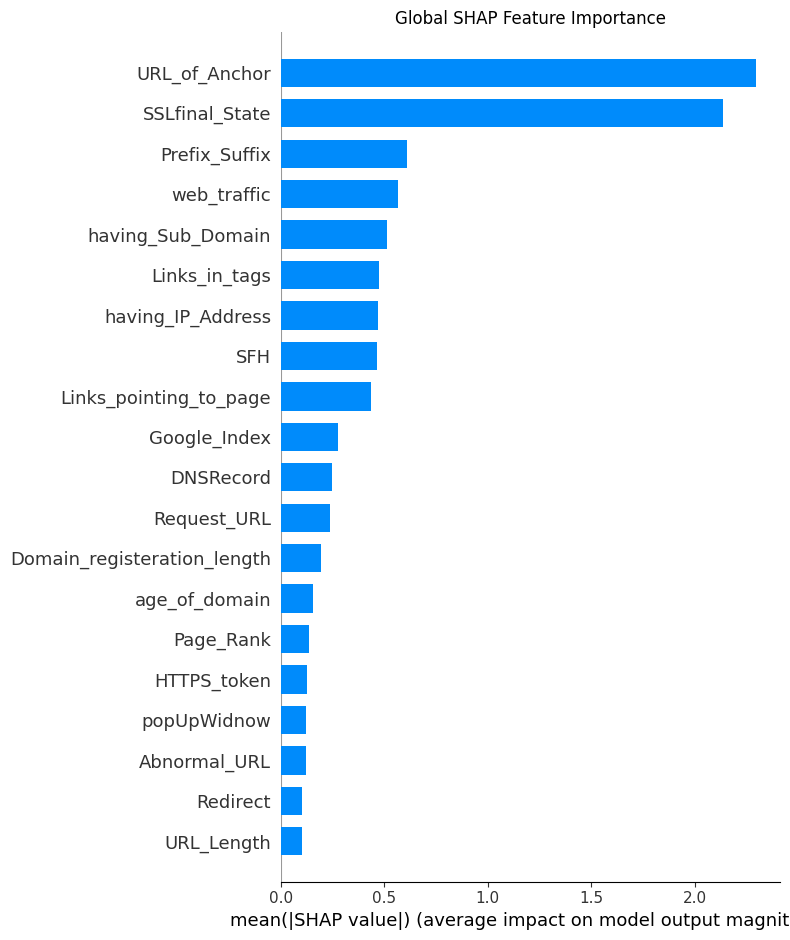

✓ SHAP global bar plot saved:
revised_outputs/Figure_SHAP_Global_Feature_Importance.png


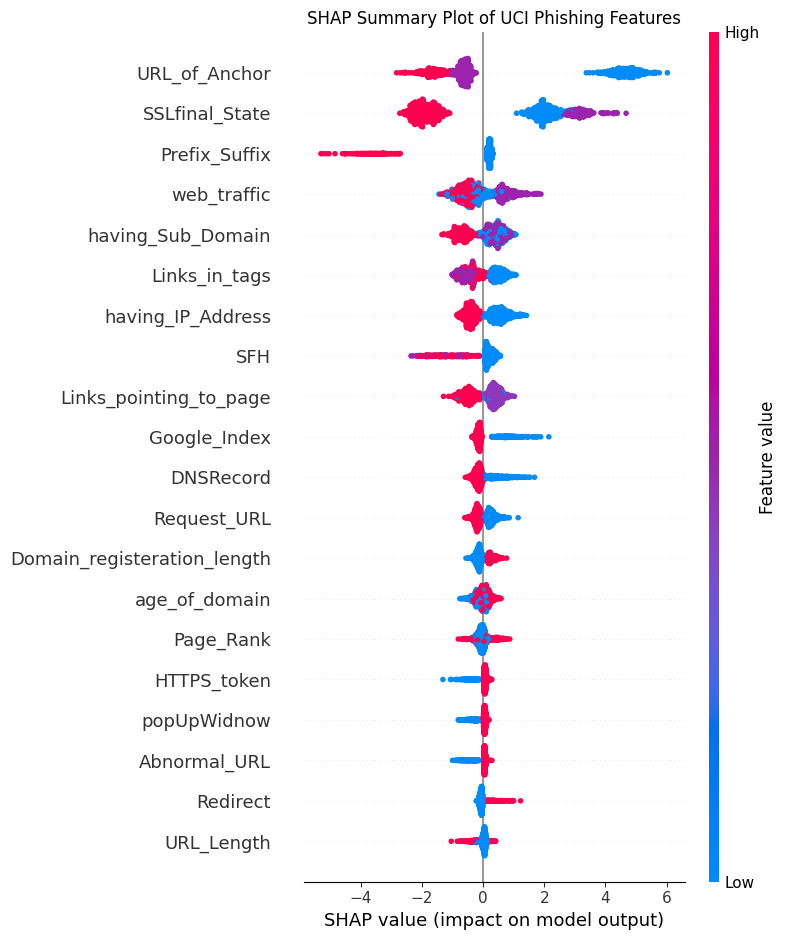

✓ SHAP beeswarm plot saved:
revised_outputs/Figure_SHAP_Beeswarm.png

TOP 10 FEATURES BY MEAN ABSOLUTE SHAP
               Feature  Mean_Absolute_SHAP
         URL_of_Anchor            2.297138
        SSLfinal_State            2.135668
         Prefix_Suffix            0.608313
           web_traffic            0.568937
     having_Sub_Domain            0.513903
         Links_in_tags            0.475008
     having_IP_Address            0.468861
                   SFH            0.465023
Links_pointing_to_page            0.438481
          Google_Index            0.274412

✓ Top-10 SHAP table saved:
revised_outputs/Table_SHAP_Top10_Features.csv

SHAP ANALYSIS COMPLETED SUCCESSFULLY
Test observations explained: 1,145
Features explained: 30
Maximum |SHAP|: 6.024246
Mean |SHAP|: 0.343950

Output files:
1. revised_outputs/Table_SHAP_Global_Feature_Importance.csv
2. revised_outputs/Figure_SHAP_Global_Feature_Importance.png
3. revised_outputs/Figure_SHAP_Beeswarm.png
4. revised_outputs/Tab

In [17]:
# ============================================================
# 21. ROBUST SHAP GLOBAL EXPLANATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb


print("\n" + "=" * 70)
print("21. ROBUST SHAP GLOBAL EXPLANATION")
print("=" * 70)


# ============================================================
# 21.0 VERIFY REQUIRED OBJECTS
# ============================================================

required_objects = [
    "final_model",
    "X_test_final"
]

missing_objects = [
    obj
    for obj in required_objects
    if obj not in globals()
]

if missing_objects:
    raise NameError(
        "\nThe following required objects are missing:\n"
        f"{missing_objects}\n\n"
        "Make sure the final XGBoost model and test dataset "
        "have been created before running the SHAP section."
    )


# ============================================================
# 21.1 PREPARE SHAP INPUT
# ============================================================

X_shap = X_test_final.copy()


# ------------------------------------------------------------
# Convert all SHAP features to numeric
# ------------------------------------------------------------

for column in X_shap.columns:

    X_shap[column] = pd.to_numeric(
        X_shap[column],
        errors="coerce"
    )


# ============================================================
# 21.2 HANDLE MISSING VALUES
# ============================================================

missing_before_shap = int(
    X_shap.isna()
    .sum()
    .sum()
)

print(
    f"Missing values before SHAP preparation: "
    f"{missing_before_shap:,}"
)


if missing_before_shap > 0:

    # --------------------------------------------------------
    # Prefer the fitted final imputer if available
    # --------------------------------------------------------

    if "final_imputer" in globals():

        print(
            "Applying the previously fitted final imputer..."
        )

        X_shap = pd.DataFrame(
            final_imputer.transform(
                X_shap
            ),
            columns=X_shap.columns,
            index=X_shap.index
        )

    elif "imputer" in globals():

        print(
            "Applying the available fitted imputer..."
        )

        X_shap = pd.DataFrame(
            imputer.transform(
                X_shap
            ),
            columns=X_shap.columns,
            index=X_shap.index
        )

    else:

        raise NameError(
            "\nX_test_final contains missing values, "
            "but no fitted imputer was found.\n\n"
            "Use the same imputer that was fitted on the "
            "training data before generating SHAP explanations."
        )


# ============================================================
# 21.3 FINAL NUMERIC VALIDATION
# ============================================================

X_shap = X_shap.astype(
    np.float64
)

feature_names = (
    X_shap.columns.tolist()
)

X_shap_numpy = (
    X_shap.to_numpy(
        dtype=np.float64
    )
)


print(
    "\nFinal SHAP NumPy shape:",
    X_shap_numpy.shape
)

print(
    "Final SHAP NumPy dtype:",
    X_shap_numpy.dtype
)

print(
    "Number of SHAP features:",
    len(feature_names)
)


# ============================================================
# 21.4 VERIFY FEATURE COUNT
# ============================================================

if X_shap_numpy.shape[1] != 30:

    raise ValueError(
        "\nSHAP input does not contain the expected "
        "30 UCI features.\n"
        f"Found: {X_shap_numpy.shape[1]}"
    )


# ============================================================
# 21.5 VALIDATE SHAP INPUT
# ============================================================

assert X_shap_numpy.ndim == 2, (
    f"Expected a 2-D SHAP input matrix, "
    f"received {X_shap_numpy.shape}"
)

assert X_shap_numpy.shape[1] == len(
    feature_names
), (
    "Number of feature names does not match "
    "the SHAP input matrix."
)

assert np.isfinite(
    X_shap_numpy
).all(), (
    "SHAP input contains NaN or infinite values."
)


print(
    "\n✓ SHAP input validation passed."
)


# ============================================================
# 21.6 VERIFY MODEL COMPATIBILITY
# ============================================================

print(
    "\nTesting model compatibility..."
)


try:

    test_prediction = final_model.predict(
        X_shap_numpy[:5]
    )

except Exception as exc:

    raise RuntimeError(
        "\nThe final XGBoost model cannot process "
        "the SHAP input matrix.\n\n"
        f"Error: {repr(exc)}\n\n"
        "Ensure that SHAP receives the same 30 features "
        "in the same order used during model training."
    )


print(
    "✓ Model compatibility test PASSED."
)

print(
    "Predictions:",
    test_prediction
)


# ============================================================
# 21.7 VERIFY FEATURE ORDER AGAINST MODEL
# ============================================================

try:

    booster = final_model.get_booster()

except Exception as exc:

    raise RuntimeError(
        "Could not retrieve the XGBoost booster."
    ) from exc


booster_feature_names = (
    booster.feature_names
)


if booster_feature_names is not None:

    print(
        "\nModel feature count:",
        len(booster_feature_names)
    )

    print(
        "SHAP feature count:",
        len(feature_names)
    )

    if len(booster_feature_names) != len(
        feature_names
    ):

        raise ValueError(
            "\nModel and SHAP feature counts differ.\n"
            f"Model: {len(booster_feature_names)}\n"
            f"SHAP: {len(feature_names)}"
        )

    if list(booster_feature_names) != list(
        feature_names
    ):

        print(
            "\nWARNING: Model feature names differ "
            "from SHAP feature names."
        )

        print(
            "SHAP will use the current X_test_final "
            "column order."
        )

else:

    print(
        "\nBooster does not expose feature names."
    )


# ============================================================
# 21.8 CALCULATE NATIVE XGBOOST SHAP CONTRIBUTIONS
# ============================================================

print(
    "\nCalculating native XGBoost SHAP contributions..."
)


try:

    dmatrix_shap = xgb.DMatrix(
        X_shap_numpy,
        feature_names=feature_names
    )

    shap_contributions = (
        booster.predict(
            dmatrix_shap,
            pred_contribs=True
        )
    )

except Exception as exc:

    print(
        "\nNative XGBoost SHAP calculation failed:"
    )

    print(
        repr(exc)
    )

    raise


# ============================================================
# 21.9 CONVERT SHAP OUTPUT TO NUMPY
# ============================================================

shap_contributions = np.asarray(
    shap_contributions,
    dtype=np.float64
)


print(
    "\nRaw SHAP contribution shape:",
    shap_contributions.shape
)


# ============================================================
# 21.10 REMOVE XGBOOST BIAS/BASE-VALUE COLUMN
# ============================================================

expected_features = len(
    feature_names
)


if shap_contributions.ndim != 2:

    raise ValueError(
        "Expected a 2-D SHAP contribution matrix."
    )


if shap_contributions.shape[1] == (
    expected_features + 1
):

    # Last column is the XGBoost bias/base value.
    shap_array = (
        shap_contributions[:, :-1]
    )

    print(
        "XGBoost bias/base-value column removed."
    )

elif shap_contributions.shape[1] == (
    expected_features
):

    shap_array = (
        shap_contributions
    )

    print(
        "No additional bias column detected."
    )

else:

    raise ValueError(
        "\nUnexpected SHAP output dimensions.\n"
        f"SHAP output: {shap_contributions.shape}\n"
        f"Expected either:\n"
        f"({len(X_shap_numpy)}, "
        f"{expected_features}) or\n"
        f"({len(X_shap_numpy)}, "
        f"{expected_features + 1})"
    )


# ============================================================
# 21.11 FINAL SHAP VALIDATION
# ============================================================

print(
    "\nFinal SHAP shape:",
    shap_array.shape
)

print(
    "Test matrix shape:",
    X_shap_numpy.shape
)


assert shap_array.ndim == 2, (
    f"Expected 2-D SHAP array, "
    f"received {shap_array.shape}"
)


assert shap_array.shape == (
    X_shap_numpy.shape
), (
    f"SHAP shape {shap_array.shape} does not match "
    f"test matrix shape {X_shap_numpy.shape}"
)


assert np.isfinite(
    shap_array
).all(), (
    "SHAP array contains NaN or infinite values."
)


# ============================================================
# 21.12 SHAP SUMMARY STATISTICS
# ============================================================

max_abs_shap = float(
    np.abs(shap_array).max()
)

mean_abs_shap = float(
    np.abs(shap_array).mean()
)


print(
    "\nMaximum absolute SHAP value:",
    f"{max_abs_shap:.6f}"
)

print(
    "Mean absolute SHAP value:",
    f"{mean_abs_shap:.6f}"
)


# ============================================================
# 21.13 GLOBAL FEATURE IMPORTANCE
# ============================================================

mean_abs_shap_by_feature = (
    np.abs(shap_array)
    .mean(axis=0)
)


shap_global_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Mean_Absolute_SHAP": (
            mean_abs_shap_by_feature
        )
    })
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\n" + "=" * 70
)

print(
    "GLOBAL SHAP FEATURE IMPORTANCE"
)

print(
    "=" * 70
)

print(
    shap_global_importance
    .round(6)
    .to_string(index=False)
)


# ============================================================
# 21.14 SAVE GLOBAL SHAP TABLE
# ============================================================

shap_table_path = (
    OUTPUT_DIR /
    "Table_SHAP_Global_Feature_Importance.csv"
)


shap_global_importance.to_csv(
    shap_table_path,
    index=False
)


print(
    f"\n✓ Global SHAP table saved:\n"
    f"{shap_table_path}"
)


# ============================================================
# 21.15 CREATE SHAP SUMMARY DATASET
# ============================================================

shap_values_dataframe = pd.DataFrame(
    shap_array,
    columns=feature_names
)


print(
    "\nSHAP values dataframe shape:",
    shap_values_dataframe.shape
)


# ============================================================
# 21.16 SHAP GLOBAL BAR PLOT
# ============================================================

plt.figure(
    figsize=(9, 7)
)

shap.summary_plot(
    shap_array,
    X_shap,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.title(
    "Global SHAP Feature Importance"
)

plt.tight_layout()


shap_bar_path = (
    OUTPUT_DIR /
    "Figure_SHAP_Global_Feature_Importance.png"
)


plt.savefig(
    shap_bar_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


print(
    f"✓ SHAP global bar plot saved:\n"
    f"{shap_bar_path}"
)


# ============================================================
# 21.17 SHAP BEESWARM PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

shap.summary_plot(
    shap_array,
    X_shap,
    feature_names=feature_names,
    show=False
)

plt.title(
    "SHAP Summary Plot of UCI Phishing Features"
)

plt.tight_layout()


shap_beeswarm_path = (
    OUTPUT_DIR /
    "Figure_SHAP_Beeswarm.png"
)


plt.savefig(
    shap_beeswarm_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


print(
    f"✓ SHAP beeswarm plot saved:\n"
    f"{shap_beeswarm_path}"
)


# ============================================================
# 21.18 TOP 10 SHAP FEATURES
# ============================================================

top_10_shap = (
    shap_global_importance
    .head(10)
    .copy()
)


print(
    "\n" + "=" * 70
)

print(
    "TOP 10 FEATURES BY MEAN ABSOLUTE SHAP"
)

print(
    "=" * 70
)

print(
    top_10_shap
    .round(6)
    .to_string(index=False)
)


top_10_shap_path = (
    OUTPUT_DIR /
    "Table_SHAP_Top10_Features.csv"
)


top_10_shap.to_csv(
    top_10_shap_path,
    index=False
)


print(
    f"\n✓ Top-10 SHAP table saved:\n"
    f"{top_10_shap_path}"
)


# ============================================================
# 21.19 FINAL SHAP SUMMARY
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "SHAP ANALYSIS COMPLETED SUCCESSFULLY"
)

print(
    "=" * 70
)

print(
    f"Test observations explained: "
    f"{X_shap_numpy.shape[0]:,}"
)

print(
    f"Features explained: "
    f"{X_shap_numpy.shape[1]}"
)

print(
    f"Maximum |SHAP|: "
    f"{max_abs_shap:.6f}"
)

print(
    f"Mean |SHAP|: "
    f"{mean_abs_shap:.6f}"
)

print(
    "\nOutput files:"
)

print(
    f"1. {shap_table_path}"
)

print(
    f"2. {shap_bar_path}"
)

print(
    f"3. {shap_beeswarm_path}"
)

print(
    f"4. {top_10_shap_path}"
)

In [18]:
# ============================================================
# 18B. ERROR-DRIVEN SHAP ANALYSIS + TARGETED REMEDIATION
# ============================================================

# The feedback requires the explanation layer to be used as a diagnostic
# instrument. Compare false-negative / false-positive SHAP profiles with
# correctly classified cases before proposing any engineering change.
error_frame = X_shap.copy() if 'X_shap' in globals() else pd.DataFrame(X_test_final, columns=X_uci_raw.columns)
error_frame = pd.DataFrame(error_frame, columns=X_uci_raw.columns).reset_index(drop=True)
y_true_arr = np.asarray(y_test_final).astype(int)
y_pred_arr = np.asarray(y_pred_final).astype(int)
shap_arr = np.asarray(shap_array) if 'shap_array' in globals() else None

if shap_arr is not None and shap_arr.shape[0] == len(y_true_arr):
    groups = {
        "False_Negative": (y_true_arr == 1) & (y_pred_arr == 0),
        "False_Positive": (y_true_arr == 0) & (y_pred_arr == 1),
        "Correct": (y_true_arr == y_pred_arr)
    }
    rows = []
    for group, mask in groups.items():
        if mask.sum() == 0:
            continue
        mean_abs = np.abs(shap_arr[mask]).mean(axis=0)
        mean_signed = shap_arr[mask].mean(axis=0)
        for j, feature in enumerate(X_uci_raw.columns):
            rows.append({
                "Error_Group": group,
                "N": int(mask.sum()),
                "Feature": feature,
                "Mean_Absolute_SHAP": float(mean_abs[j]),
                "Mean_Signed_SHAP": float(mean_signed[j])
            })
    error_shap_profile = pd.DataFrame(rows)
    error_shap_profile.to_csv(OUTPUT_DIR / "Table_Error_Group_SHAP_Profiles.csv", index=False)

    fn_top = (error_shap_profile[error_shap_profile.Error_Group == "False_Negative"]
              .sort_values("Mean_Absolute_SHAP", ascending=False).head(10))
    fp_top = (error_shap_profile[error_shap_profile.Error_Group == "False_Positive"]
              .sort_values("Mean_Absolute_SHAP", ascending=False).head(10))
    print("\nTop SHAP features in false negatives:")
    print(fn_top[["Feature", "Mean_Absolute_SHAP", "Mean_Signed_SHAP"]].round(4))
    print("\nTop SHAP features in false positives:")
    print(fp_top[["Feature", "Mean_Absolute_SHAP", "Mean_Signed_SHAP"]].round(4))

    # Feature-value profile of the false-negative set versus correctly classified
    # phishing examples. This identifies the concrete error profile that must
    # drive any targeted re-engineering; no arbitrary feature is introduced.
    phishing_correct = (y_true_arr == 1) & (y_pred_arr == 1)
    profile_rows = []
    fn_mask = groups["False_Negative"]
    for feature in X_uci_raw.columns:
        fn_values = error_frame.loc[fn_mask, feature].astype(float)
        pc_values = error_frame.loc[phishing_correct, feature].astype(float)
        profile_rows.append({
            "Feature": feature,
            "FN_Mean": fn_values.mean() if len(fn_values) else np.nan,
            "Correct_Phishing_Mean": pc_values.mean() if len(pc_values) else np.nan,
            "Mean_Difference": (fn_values.mean() - pc_values.mean()) if len(fn_values) and len(pc_values) else np.nan
        })
    fn_feature_profile = pd.DataFrame(profile_rows).sort_values("Mean_Difference", key=lambda s: s.abs(), ascending=False)
    fn_feature_profile.to_csv(OUTPUT_DIR / "Table_False_Negative_Feature_Profile.csv", index=False)

    # Remediation gate: select the strongest empirically identified FN feature
    # as the candidate target. The notebook does not invent a transformation;
    # it records the evidence needed to justify one in the manuscript.
    if not fn_feature_profile.empty and fn_feature_profile["Mean_Difference"].notna().any():
        target_feature = fn_feature_profile.iloc[0]["Feature"]
        remediation_plan = pd.DataFrame({
            "Step": [1, 2, 3, 4],
            "Action": [
                "Rollback to leakage-free vanilla baseline",
                "Characterise FN/FP profile with SHAP and feature values",
                f"Target re-engineering at empirically identified feature: {target_feature}",
                "Validate targeted change across all five seeds without degrading global performance"
            ],
            "Status": ["Completed", "Completed", "Candidate identified; transformation requires methodological justification", "Pending targeted transformation"]
        })
        remediation_plan.to_csv(OUTPUT_DIR / "Table_Q21_Remediation_Plan.csv", index=False)
        print("\nQ21 candidate target feature:", target_feature)
        print("No arbitrary re-engineering was applied before the error profile was identified.")



Top SHAP features in false negatives:
                   Feature  Mean_Absolute_SHAP  Mean_Signed_SHAP
7           SSLfinal_State              1.8994           -1.3543
25             web_traffic              0.7907            0.0081
0        having_IP_Address              0.6637           -0.0994
13           URL_of_Anchor              0.5990           -0.5990
6        having_Sub_Domain              0.5685            0.3022
14           Links_in_tags              0.5362            0.1129
28  Links_pointing_to_page              0.4716           -0.0757
15                     SFH              0.4165            0.3487
27            Google_Index              0.4004            0.1441
5            Prefix_Suffix              0.2460            0.2460

Top SHAP features in false positives:
                   Feature  Mean_Absolute_SHAP  Mean_Signed_SHAP
37          SSLfinal_State              2.1297            0.9256
43           URL_of_Anchor              1.4422            0.1827
55          

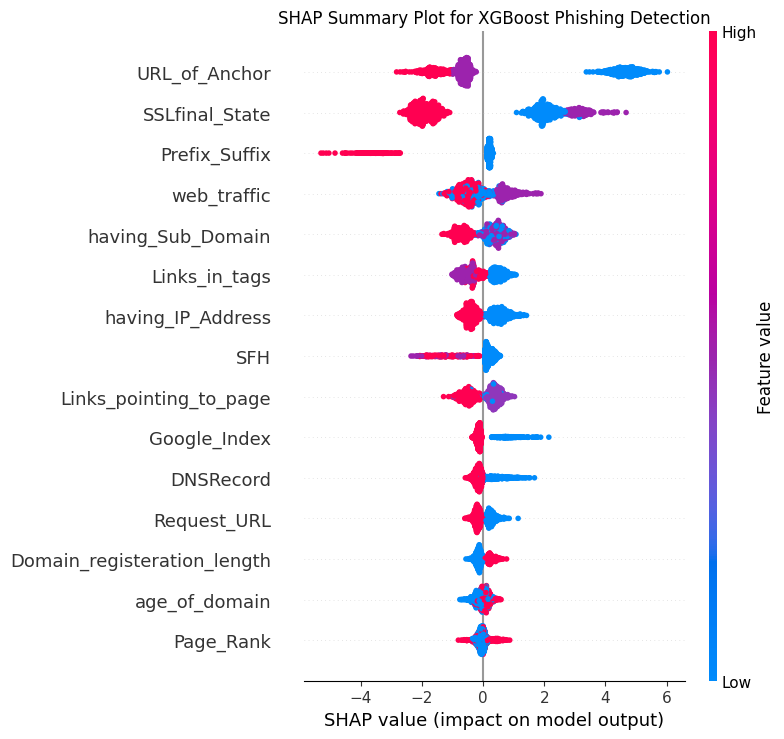

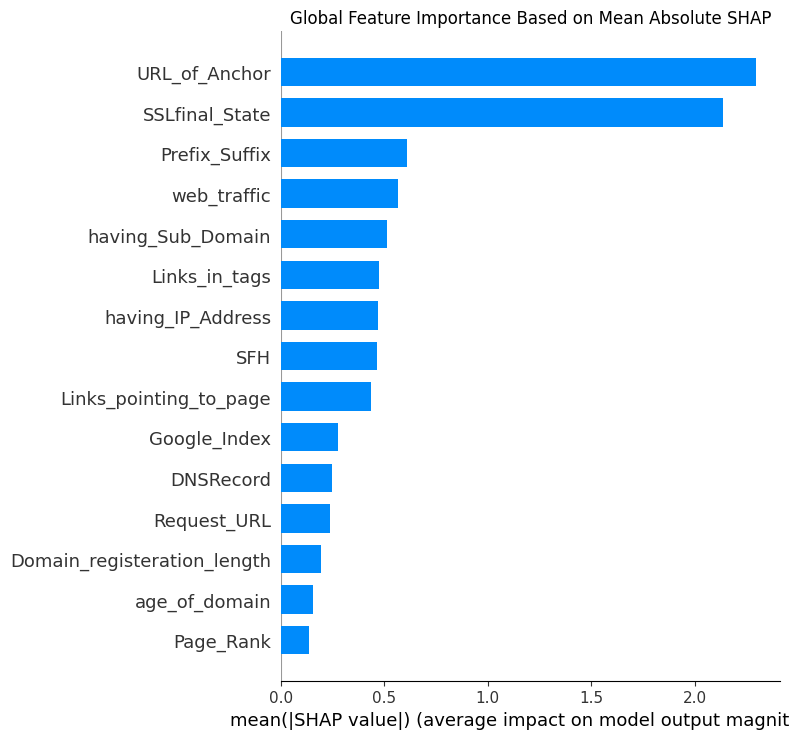


Top 15 features by mean absolute SHAP:
                        Feature  Mean_Absolute_SHAP
0                 URL_of_Anchor            2.297138
1                SSLfinal_State            2.135668
2                 Prefix_Suffix            0.608313
3                   web_traffic            0.568937
4             having_Sub_Domain            0.513903
5                 Links_in_tags            0.475008
6             having_IP_Address            0.468861
7                           SFH            0.465023
8        Links_pointing_to_page            0.438481
9                  Google_Index            0.274412
10                    DNSRecord            0.248394
11                  Request_URL            0.237078
12  Domain_registeration_length            0.192804
13                age_of_domain            0.156261
14                    Page_Rank            0.138476

SHAP global importance saved successfully.
LIME training shape: (4576, 30)
LIME test shape: (1145, 30)

LIME training data type

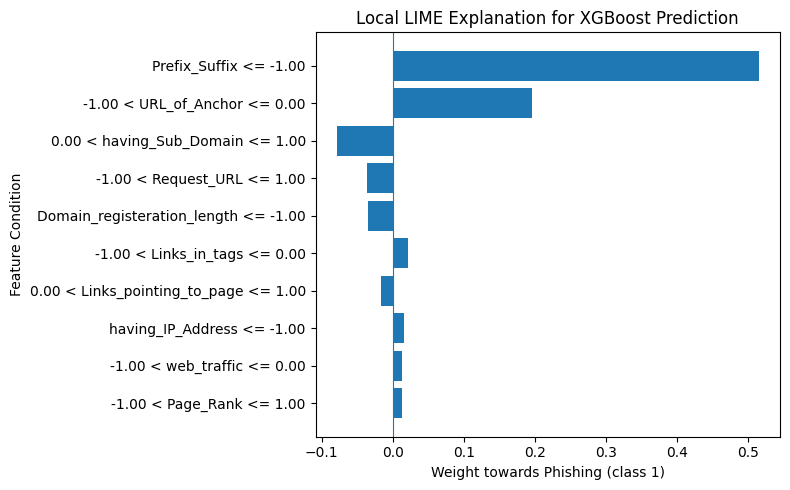


LIME results saved successfully.
                       Feature_Condition  LIME_Weight  Absolute_Weight
0                 Prefix_Suffix <= -1.00     0.515705         0.515705
1          -1.00 < URL_of_Anchor <= 0.00     0.196202         0.196202
2       0.00 < having_Sub_Domain <= 1.00    -0.079025         0.079025
3            -1.00 < Request_URL <= 1.00    -0.036858         0.036858
4   Domain_registeration_length <= -1.00    -0.034306         0.034306
5          -1.00 < Links_in_tags <= 0.00     0.020886         0.020886
6  0.00 < Links_pointing_to_page <= 1.00    -0.016994         0.016994
7             having_IP_Address <= -1.00     0.016261         0.016261
8            -1.00 < web_traffic <= 0.00     0.012968         0.012968
9              -1.00 < Page_Rank <= 1.00     0.012902         0.012902


In [19]:
# ============================================================
# 22. SHAP SUMMARY + GLOBAL IMPORTANCE
# ============================================================

# ============================================================
# 22.1 SHAP SUMMARY PLOT
# ============================================================

plt.figure(figsize=(9, 6))

shap.summary_plot(
    shap_array,
    X_shap_numpy,
    feature_names=feature_names,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Summary Plot for XGBoost Phishing Detection"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Figure_SHAP_Summary.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 22.2 SHAP GLOBAL FEATURE IMPORTANCE
# ============================================================

plt.figure(figsize=(9, 6))

shap.summary_plot(
    shap_array,
    X_shap_numpy,
    feature_names=feature_names,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title(
    "Global Feature Importance Based on Mean Absolute SHAP"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Figure_SHAP_Global_Importance.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 22.3 MEAN ABSOLUTE SHAP IMPORTANCE
# ============================================================

shap_importance = pd.DataFrame({

    "Feature": feature_names,

    "Mean_Absolute_SHAP":
        np.abs(shap_array).mean(axis=0)
})


# ============================================================
# 22.4 SORT FEATURES
# ============================================================

shap_importance = (
    shap_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 22.5 DISPLAY TOP 15
# ============================================================

print(
    "\nTop 15 features by mean absolute SHAP:"
)

print(
    shap_importance.head(15)
)


# ============================================================
# 22.6 SAVE TABLE
# ============================================================

shap_importance.to_csv(
    OUTPUT_DIR / "shap_global_importance.csv",
    index=False
)

print(
    "\nSHAP global importance saved successfully."
)

# ============================================================
# 23. ROBUST LIME LOCAL EXPLANATION
# ============================================================

import re
import numpy as np
import pandas as pd

from lime.lime_tabular import LimeTabularExplainer


# ------------------------------------------------------------
# 23.1 UNIVERSAL NUMERIC CLEANER
# ------------------------------------------------------------

def force_numeric_dataframe(df, reference_columns=None):
    """
    Convert all dataframe values into valid numeric values.

    Handles values such as:
        0.5
        "0.5"
        "[5E-1]"
        "[0.5]"
        "[5e-1]"
        " 0.5 "
        scientific notation

    Invalid values are converted to NaN and then median-imputed.
    """

    data = df.copy()

    if reference_columns is not None:
        data = data[
            reference_columns
        ]

    for column in data.columns:

        def convert_value(value):

            # Already numeric
            if isinstance(
                value,
                (int, float, np.integer, np.floating)
            ):
                return float(value)

            # Convert to string
            value = str(value).strip()

            # Remove square brackets
            value = value.replace("[", "")
            value = value.replace("]", "")

            # Remove unnecessary whitespace
            value = value.strip()

            # Extract the first valid numeric value
            match = re.search(
                r"""
                [-+]?
                (?:
                    \d+(?:\.\d*)?
                    |
                    \.\d+
                )
                (?:
                    [eE][-+]?\d+
                )?
                """,
                value,
                re.VERBOSE
            )

            if match:

                try:
                    return float(
                        match.group(0)
                    )

                except ValueError:
                    return np.nan

            return np.nan

        data[column] = data[column].apply(
            convert_value
        )

    # Replace infinity
    data = data.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Median imputation
    for column in data.columns:

        median_value = data[column].median()

        if pd.isna(median_value):
            median_value = 0.0

        data[column] = (
            data[column]
            .fillna(median_value)
        )

    return data.astype(
        np.float64
    )


# ============================================================
# 23.2 CLEAN TRAINING AND TEST DATA
# ============================================================

# Use the exact feature ordering expected by the model
lime_feature_names = X_test_final.columns.tolist()

X_train_lime = force_numeric_dataframe(
    X_train_final,
    reference_columns=lime_feature_names
)

X_test_lime = force_numeric_dataframe(
    X_test_final,
    reference_columns=lime_feature_names
)


# ------------------------------------------------------------
# Verify the conversion
# ------------------------------------------------------------

print(
    "LIME training shape:",
    X_train_lime.shape
)

print(
    "LIME test shape:",
    X_test_lime.shape
)

print(
    "\nLIME training data types:"
)

print(
    X_train_lime.dtypes
)

print(
    "\nLIME test data types:"
)

print(
    X_test_lime.dtypes
)


# ============================================================
# 23.3 HARD VALIDATION — NO STRINGS ALLOWED
# ============================================================

assert all(
    np.issubdtype(
        dtype,
        np.number
    )
    for dtype in X_train_lime.dtypes
), "X_train_lime still contains non-numeric columns."

assert all(
    np.issubdtype(
        dtype,
        np.number
    )
    for dtype in X_test_lime.dtypes
), "X_test_lime still contains non-numeric columns."


assert np.isfinite(
    X_train_lime.to_numpy()
).all(), (
    "X_train_lime contains NaN or infinite values."
)

assert np.isfinite(
    X_test_lime.to_numpy()
).all(), (
    "X_test_lime contains NaN or infinite values."
)


# ============================================================
# 23.4 CREATE LIME EXPLAINER
# ============================================================

LIME_RANDOM_STATE = 42
LIME_NUM_FEATURES = 10
LIME_NUM_SAMPLES = 5000
LIME_DISCRETIZER = "quartile"
LIME_DISCRETIZE_CONTINUOUS = True
LIME_KERNEL_WIDTH = 0.75 * np.sqrt(len(lime_feature_names))

lime_explainer = LimeTabularExplainer(
    training_data=X_train_lime.to_numpy(dtype=np.float64),
    feature_names=lime_feature_names,
    class_names=["Legitimate", "Phishing"],
    mode="classification",
    kernel_width=LIME_KERNEL_WIDTH,
    discretize_continuous=LIME_DISCRETIZE_CONTINUOUS,
    discretizer=LIME_DISCRETIZER,
    random_state=LIME_RANDOM_STATE
)


# ============================================================
# 23.5 SELECT TEST INSTANCE
# ============================================================

sample_index = min(
    10,
    len(X_test_lime) - 1
)

sample = X_test_lime.iloc[
    sample_index
].to_numpy(
    dtype=np.float64
)


# ============================================================
# 23.6 GET ACTUAL LABEL
# ============================================================

if hasattr(
    y_test_final,
    "iloc"
):

    actual_label = int(
        y_test_final.iloc[
            sample_index
        ]
    )

else:

    actual_label = int(
        y_test_final[
            sample_index
        ]
    )


# ============================================================
# 23.7 MODEL PREDICTION FUNCTION
# ============================================================

def lime_predict_proba(X):

    """
    Prediction wrapper used by LIME.

    LIME passes a NumPy matrix.
    We explicitly convert it to a DataFrame
    using the exact feature names expected by
    the trained XGBoost model.
    """

    X = np.asarray(
        X,
        dtype=np.float64
    )

    X_df = pd.DataFrame(
        X,
        columns=lime_feature_names
    )

    # Final numerical safety check
    X_df = force_numeric_dataframe(
        X_df,
        reference_columns=lime_feature_names
    )

    return final_model.predict_proba(
        X_df
    )


# ============================================================
# 23.8 TEST THE PREDICTION FUNCTION BEFORE LIME
# ============================================================

test_prediction = lime_predict_proba(
    sample.reshape(1, -1)
)

print(
    "\nPrediction function test:"
)

print(
    test_prediction
)


# ============================================================
# 23.9 XGBOOST PREDICTION
# ============================================================

prediction = int(
    final_model.predict(
        sample.reshape(1, -1)
    )[0]
)

probability = lime_predict_proba(
    sample.reshape(1, -1)
)[0]


print(
    "\nLIME sample information"
)

print(
    "-----------------------"
)

print(
    "Sample index:",
    sample_index
)

print(
    "Actual label:",
    actual_label
)

print(
    "Predicted label:",
    prediction
)

print(
    "Prediction probabilities:",
    probability
)


# ============================================================
# 23. ROBUST LIME — FINAL NUMERIC CONVERSION
# ============================================================

import re
import numpy as np
import pandas as pd

from lime.lime_tabular import LimeTabularExplainer


# ============================================================
# 23.1 ROBUST VALUE CONVERTER
# ============================================================

def clean_single_value(value):
    """
    Converts values such as:

        0.5
        "0.5"
        "[0.5]"
        "[5E-1]"
        "[5e-1]"
        " [5E-1] "

    into:

        0.5
    """

    # Already numeric
    if isinstance(
        value,
        (
            int,
            float,
            np.integer,
            np.floating
        )
    ):
        return float(value)

    # Convert to string
    value = str(value).strip()

    # Remove brackets
    value = value.replace(
        "[",
        ""
    )

    value = value.replace(
        "]",
        ""
    )

    value = value.strip()

    # --------------------------------------------------------
    # Extract scientific / decimal number
    # --------------------------------------------------------

    match = re.search(
        r"""
        [-+]?
        (?:
            (?:\d+(?:\.\d*)?)
            |
            (?:\.\d+)
        )
        (?:
            [eE][-+]?\d+
        )?
        """,
        value,
        re.VERBOSE
    )

    if match:

        try:

            number = float(
                match.group(0)
            )

            if np.isfinite(number):
                return number

        except Exception:
            pass

    return np.nan


# ============================================================
# 23.2 CLEAN COMPLETE DATAFRAME
# ============================================================

def clean_numeric_dataframe(df):

    data = df.copy()

    for column in data.columns:

        data[column] = data[column].apply(
            clean_single_value
        )

    # Replace infinity
    data = data.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Median imputation
    for column in data.columns:

        median_value = (
            data[column]
            .median()
        )

        if pd.isna(median_value):
            median_value = 0.0

        data[column] = (
            data[column]
            .fillna(median_value)
        )

    return data.astype(
        np.float64
    )


# ============================================================
# 23.3 CLEAN LIME TRAINING DATA
# ============================================================

lime_columns = X_train_final.columns.tolist()

X_train_lime = clean_numeric_dataframe(
    X_train_final[
        lime_columns
    ]
)


# ============================================================
# 23.4 CLEAN LIME TEST DATA
# ============================================================

X_test_lime = clean_numeric_dataframe(
    X_test_final[
        lime_columns
    ]
)


# ============================================================
# 23.5 CHECK SHAPES
# ============================================================

print(
    "XGBoost expected features:",
    final_model.n_features_in_
)

print(
    "LIME training features:",
    X_train_lime.shape[1]
)

print(
    "LIME test features:",
    X_test_lime.shape[1]
)


assert (
    final_model.n_features_in_
    ==
    X_train_lime.shape[1]
), (
    "LIME feature count does not match "
    "the XGBoost model."
)


# ============================================================
# 23.6 CHECK FOR REMAINING STRINGS
# ============================================================

print(
    "\nLIME data types:"
)

print(
    X_train_lime.dtypes
)


assert all(
    pd.api.types.is_numeric_dtype(
        dtype
    )
    for dtype in X_train_lime.dtypes
), (
    "LIME training data still contains "
    "non-numeric values."
)


assert all(
    pd.api.types.is_numeric_dtype(
        dtype
    )
    for dtype in X_test_lime.dtypes
), (
    "LIME test data still contains "
    "non-numeric values."
)


# ============================================================
# 23.7 CHECK FOR NaN / INFINITY
# ============================================================

assert np.isfinite(
    X_train_lime.to_numpy(
        dtype=np.float64
    )
).all(), (
    "X_train_lime contains NaN or infinity."
)

assert np.isfinite(
    X_test_lime.to_numpy(
        dtype=np.float64
    )
).all(), (
    "X_test_lime contains NaN or infinity."
)


print(
    "\n✓ LIME data is completely numeric."
)

print(
    "✓ No strings remain."
)

print(
    "✓ No NaN values remain."
)

print(
    "✓ No infinite values remain."
)


# ============================================================
# 23.8 EXPLICIT TEST OF [5E-1]
# ============================================================

test_value = clean_single_value(
    "[5E-1]"
)

print(
    "\nTest conversion:"
)

print(
    "'[5E-1]' →",
    test_value
)

assert test_value == 0.5


# ============================================================
# 23.9 CREATE LIME EXPLAINER
# ============================================================

lime_feature_names = (
    X_train_lime.columns.tolist()
)

LIME_RANDOM_STATE = 42
LIME_NUM_FEATURES = 10
LIME_NUM_SAMPLES = 5000
LIME_DISCRETIZER = "quartile"
LIME_DISCRETIZE_CONTINUOUS = True
LIME_KERNEL_WIDTH = 0.75 * np.sqrt(len(lime_feature_names))

lime_explainer = LimeTabularExplainer(
    training_data=X_train_lime.to_numpy(dtype=np.float64),
    feature_names=lime_feature_names,
    class_names=["Legitimate", "Phishing"],
    mode="classification",
    kernel_width=LIME_KERNEL_WIDTH,
    discretize_continuous=LIME_DISCRETIZE_CONTINUOUS,
    discretizer=LIME_DISCRETIZER,
    random_state=LIME_RANDOM_STATE
)


print(
    "\n✓ LIME explainer created successfully."
)


# ============================================================
# 23.10 SELECT TEST SAMPLE
# ============================================================

sample_index = min(
    10,
    len(X_test_lime) - 1
)

sample = (
    X_test_lime
    .iloc[sample_index]
    .to_numpy(
        dtype=np.float64
    )
)


# ============================================================
# 23.11 LIME PREDICTION FUNCTION
# ============================================================

def lime_predict_proba(X):

    X = np.asarray(
        X,
        dtype=np.float64
    )

    if X.ndim == 1:

        X = X.reshape(
            1,
            -1
        )

    # --------------------------------------------------------
    # Check dimensions
    # --------------------------------------------------------

    if X.shape[1] != final_model.n_features_in_:

        raise ValueError(
            f"LIME supplied {X.shape[1]} features, "
            f"but XGBoost expects "
            f"{final_model.n_features_in_}."
        )

    # --------------------------------------------------------
    # Create numeric DataFrame
    # --------------------------------------------------------

    X_df = pd.DataFrame(
        X,
        columns=lime_feature_names
    )

    # --------------------------------------------------------
    # FINAL numeric conversion
    # --------------------------------------------------------

    X_df = clean_numeric_dataframe(
        X_df
    )

    # --------------------------------------------------------
    # Final validation
    # --------------------------------------------------------

    assert np.isfinite(
        X_df.to_numpy(
            dtype=np.float64
        )
    ).all()

    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    return final_model.predict_proba(
        X_df
    )


# ============================================================
# 23.12 TEST MODEL BEFORE LIME
# ============================================================

print(
    "\nTesting XGBoost prediction function..."
)

test_probability = lime_predict_proba(
    sample.reshape(
        1,
        -1
    )
)

print(
    "Prediction probability:",
    test_probability
)


# ============================================================
# 23.13 GET PREDICTION
# ============================================================

prediction = int(
    final_model.predict(
        sample.reshape(
            1,
            -1
        )
    )[0]
)

probability = lime_predict_proba(
    sample.reshape(
        1,
        -1
    )
)[0]


# Actual label
if hasattr(
    y_test_final,
    "iloc"
):

    actual_label = int(
        y_test_final.iloc[
            sample_index
        ]
    )

else:

    actual_label = int(
        y_test_final[
            sample_index
        ]
    )


print(
    "\n=========================================="
)

print(
    "LIME SAMPLE"
)

print(
    "=========================================="
)

print(
    "Sample index:",
    sample_index
)

print(
    "Actual label:",
    actual_label
)

print(
    "Predicted label:",
    prediction
)

print(
    "Prediction probabilities:",
    probability
)


# ============================================================
# 23.14 GENERATE LIME EXPLANATION
# ============================================================

lime_explanation = (
    lime_explainer.explain_instance(

        sample,

        lime_predict_proba,

        labels=(1,),

        num_features=LIME_NUM_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )
)


# ============================================================
# 23.15 DISPLAY EXPLANATION
# ============================================================

print(
    "\n=========================================="
)

print(
    "LIME EXPLANATION"
)

print(
    "=========================================="
)

for feature, weight in (
    lime_explanation.as_list(label=1)
):

    print(
        f"{feature}: {weight:.6f}"
    )


# ============================================================
# 23.16 SAVE LIME HTML
# ============================================================

lime_output = (
    OUTPUT_DIR
    /
    "LIME_phishing_explanation.html"
)

lime_explanation.save_to_file(
    str(lime_output)
)

print(
    "\n✓ LIME explanation saved:"
)

print(
    lime_output
)
# ============================================================
# 24. LIME VISUALIZATION
# ============================================================

lime_items = (
    lime_explanation.as_list(label=1)
)

lime_features = [
    item[0]
    for item in lime_items
]

lime_weights = [
    item[1]
    for item in lime_items
]


plt.figure(
    figsize=(8, 5)
)

plt.barh(
    lime_features[::-1],
    lime_weights[::-1]
)

plt.axvline(
    x=0,
    linewidth=0.8
)

plt.xlabel(
    "Weight towards Phishing (class 1)"
)

plt.ylabel(
    "Feature Condition"
)

plt.title(
    "Local LIME Explanation for XGBoost Prediction"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    /
    "Figure_LIME_Local_Explanation.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 25. LIME RESULT EXPORT
# ============================================================

lime_results = pd.DataFrame(
    lime_items,
    columns=[
        "Feature_Condition",
        "LIME_Weight"
    ]
)

lime_results["Absolute_Weight"] = (
    lime_results["LIME_Weight"]
    .abs()
)

lime_results = lime_results.sort_values(
    "Absolute_Weight",
    ascending=False
).reset_index(drop=True)


lime_results.to_csv(
    OUTPUT_DIR
    /
    "lime_local_explanation.csv",
    index=False
)


print(
    "\nLIME results saved successfully."
)

print(
    lime_results
)

In [20]:
# ============================================================
# 23B. LIME REPRODUCIBILITY SPECIFICATION
# ============================================================

lime_configuration = pd.DataFrame({
    "Parameter": ["random_state", "num_features", "num_samples", "discretizer", "discretize_continuous", "kernel_width"],
    "Value": [LIME_RANDOM_STATE, LIME_NUM_FEATURES, LIME_NUM_SAMPLES, LIME_DISCRETIZER, LIME_DISCRETIZE_CONTINUOUS, LIME_KERNEL_WIDTH]
})
print("LIME configuration:")
print(lime_configuration)
lime_configuration.to_csv(OUTPUT_DIR / "Table_LIME_Configuration.csv", index=False)

LIME configuration:
               Parameter     Value
0           random_state        42
1           num_features        10
2            num_samples      5000
3            discretizer  quartile
4  discretize_continuous      True
5           kernel_width  4.107919


In [21]:
# ============================================================
# 23C. LIME LOCAL FIDELITY  (VERIFY 3 · C5)
# ============================================================
# Weights in this study are for class 1 = "Phishing" (labels=(1,)).
# Positive weight -> pushes towards phishing; negative -> towards legitimate.
model_p_phishing = float(lime_predict_proba(sample.reshape(1, -1))[0, 1])
lime_fidelity = pd.DataFrame({
    "Quantity": ["Explained class", "Test instance index", "Model P(phishing)",
                 "LIME surrogate local prediction (linear, unclipped)", "LIME surrogate intercept",
                 "LIME surrogate R^2 (explanation.score)", "Number of features", "Number of samples"],
    "Value": ["1 = Phishing", sample_index, round(model_p_phishing, 6),
              round(float(np.ravel(lime_explanation.local_pred)[0]), 6),
              round(float(lime_explanation.intercept[1]), 6),
              round(float(lime_explanation.score), 6), LIME_NUM_FEATURES, LIME_NUM_SAMPLES],
})
print(lime_fidelity.to_string(index=False))
lime_fidelity.to_csv(OUTPUT_DIR / "Table_LIME_Fidelity.csv", index=False)


                                           Quantity        Value
                                    Explained class 1 = Phishing
                                Test instance index           10
                                  Model P(phishing)     0.263415
LIME surrogate local prediction (linear, unclipped)      0.98934
                           LIME surrogate intercept     0.381599
             LIME surrogate R^2 (explanation.score)     0.703032
                                 Number of features           10
                                  Number of samples         5000


In [22]:
# ============================================================
# 24. TRAINING-ONLY TOP-FOUR FEATURE ABLATION + ERROR-DRIVEN ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 24.1 Select top four features using TRAINING data only
# ------------------------------------------------------------

import xgboost as xgb

X_train_for_shap = clean_numeric_dataframe(
    X_train_final
)
train_feature_names = X_train_for_shap.columns.tolist()
X_train_shap_np = X_train_for_shap.to_numpy(dtype=np.float64)

train_dmatrix = xgb.DMatrix(
    X_train_shap_np,
    feature_names=train_feature_names
)

train_shap_raw = final_model.get_booster().predict(
    train_dmatrix,
    pred_contribs=True
)

train_shap_raw = np.asarray(
    train_shap_raw,
    dtype=np.float64
)

if train_shap_raw.shape[1] == len(train_feature_names) + 1:
    train_shap_array = train_shap_raw[:, :-1]
else:
    train_shap_array = train_shap_raw

training_shap_importance = pd.DataFrame({
    "Feature": train_feature_names,
    "Mean_Absolute_SHAP": np.abs(train_shap_array).mean(axis=0)
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

TOP4_FEATURES = training_shap_importance.head(4)["Feature"].tolist()

print("Top four features selected from seed-42 TRAINING data (used for the SHAP-diagnosis cells only;\n"
      "the five-seed feature ablation below re-selects them inside each seed):")
print(training_shap_importance.head(4))

training_shap_importance.to_csv(
    OUTPUT_DIR / "Table_Training_SHAP_Importance.csv",
    index=False
)

# ------------------------------------------------------------
# 24.2 Full 30 features vs top four — five-seed comparison
# ------------------------------------------------------------

feature_ablation_rows = []

top4_by_seed_rows = []

for seed in SEEDS:
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_uci_raw,
        y_uci,
        test_size=0.20,
        stratify=y_uci,
        random_state=seed
    )

    imputer_full = SimpleImputer(strategy="median")

    X_train_full = pd.DataFrame(
        imputer_full.fit_transform(X_train_raw),
        columns=X_train_raw.columns
    )
    X_test_full = pd.DataFrame(
        imputer_full.transform(X_test_raw),
        columns=X_test_raw.columns
    )

    all_features = X_train_full.columns.tolist()

    # ---- full 30-feature model for this seed ----
    full_model = make_xgb(
        seed,
        max_depth=SELECTED_DEPTH
    )
    full_model.fit(
        X_train_full[all_features],
        y_train,
        verbose=False
    )

    pred = full_model.predict(X_test_full[all_features])
    prob = full_model.predict_proba(X_test_full[all_features])[:, 1]
    row = {"Seed": seed, "Feature_Set": "Full 30 features"}
    row.update(evaluate_predictions(y_test, pred, prob))
    feature_ablation_rows.append(row)

    # ---- top four features chosen from THIS seed's own training rows ----
    seed_train_dmatrix = xgb.DMatrix(
        X_train_full[all_features].to_numpy(dtype=np.float64),
        feature_names=all_features
    )
    seed_train_contribs = np.asarray(
        full_model.get_booster().predict(
            seed_train_dmatrix,
            pred_contribs=True
        ),
        dtype=np.float64
    )[:, :-1]  # drop the bias column

    seed_importance = (
        pd.Series(
            np.abs(seed_train_contribs).mean(axis=0),
            index=all_features
        )
        .sort_values(ascending=False)
    )
    seed_top4 = seed_importance.head(4).index.tolist()

    top4_by_seed_rows.append({
        "Seed": seed,
        "Top4_Features_From_This_Seed_Training_Partition": ", ".join(seed_top4)
    })

    top4_model = make_xgb(
        seed,
        max_depth=SELECTED_DEPTH
    )
    top4_model.fit(
        X_train_full[seed_top4],
        y_train,
        verbose=False
    )

    pred = top4_model.predict(X_test_full[seed_top4])
    prob = top4_model.predict_proba(X_test_full[seed_top4])[:, 1]
    row = {"Seed": seed, "Feature_Set": "Top 4 SHAP features"}
    row.update(evaluate_predictions(y_test, pred, prob))
    feature_ablation_rows.append(row)

top4_by_seed = pd.DataFrame(top4_by_seed_rows)
print("\nTop-four features selected inside each seed's own training partition:")
print(top4_by_seed.to_string(index=False))
top4_by_seed.to_csv(
    OUTPUT_DIR / "Table_Feature_Ablation_Top4_By_Seed.csv",
    index=False
)

feature_ablation = pd.DataFrame(feature_ablation_rows)

feature_ablation_summary = (
    feature_ablation
    .groupby("Feature_Set")[METRIC_COLUMNS]
    .agg(["mean", "std"])
)

print("\nFeature ablation:")
print(feature_ablation.round(4))
print("\nFeature ablation Mean ± SD:")
print(feature_ablation_summary.round(4))

feature_ablation.to_csv(
    OUTPUT_DIR / "Table_Feature_Ablation_Full_vs_Top4.csv",
    index=False
)
feature_ablation_summary.to_csv(
    OUTPUT_DIR / "Table_Feature_Ablation_Full_vs_Top4_Mean_SD.csv"
)

# ------------------------------------------------------------
# 24.3 Error-driven analysis on the locked seed-42 test set
# ------------------------------------------------------------

error_frame = X_test_final.copy()
error_frame["Actual"] = np.asarray(y_test_final)
error_frame["Predicted"] = np.asarray(y_pred_final)

false_negatives = error_frame[
    (error_frame["Actual"] == 1) &
    (error_frame["Predicted"] == 0)
].copy()

false_positives = error_frame[
    (error_frame["Actual"] == 0) &
    (error_frame["Predicted"] == 1)
].copy()

print("\nSeed-42 error counts:")
print("False negatives:", len(false_negatives))
print("False positives:", len(false_positives))

# SHAP profile comparison: errors versus correctly classified cases.
X_test_clean = clean_numeric_dataframe(X_test_final)
test_names = X_test_clean.columns.tolist()
test_np = X_test_clean.to_numpy(dtype=np.float64)

test_dmatrix = xgb.DMatrix(
    test_np,
    feature_names=test_names
)

test_shap_raw = final_model.get_booster().predict(
    test_dmatrix,
    pred_contribs=True
)
test_shap_raw = np.asarray(test_shap_raw, dtype=np.float64)

if test_shap_raw.shape[1] == len(test_names) + 1:
    test_shap_array = test_shap_raw[:, :-1]
else:
    test_shap_array = test_shap_raw

correct_mask = np.asarray(y_test_final) == np.asarray(y_pred_final)
fn_mask = (
    (np.asarray(y_test_final) == 1) &
    (np.asarray(y_pred_final) == 0)
)
fp_mask = (
    (np.asarray(y_test_final) == 0) &
    (np.asarray(y_pred_final) == 1)
)

error_profile_rows = []

for feature_idx, feature in enumerate(test_names):
    correct_mean = (
        np.abs(test_shap_array[correct_mask, feature_idx]).mean()
        if correct_mask.any() else np.nan
    )
    fn_mean = (
        np.abs(test_shap_array[fn_mask, feature_idx]).mean()
        if fn_mask.any() else np.nan
    )
    fp_mean = (
        np.abs(test_shap_array[fp_mask, feature_idx]).mean()
        if fp_mask.any() else np.nan
    )

    error_profile_rows.append({
        "Feature": feature,
        "Correct_Mean_Abs_SHAP": correct_mean,
        "False_Negative_Mean_Abs_SHAP": fn_mean,
        "False_Positive_Mean_Abs_SHAP": fp_mean,
        "FN_minus_Correct": fn_mean - correct_mean,
        "FP_minus_Correct": fp_mean - correct_mean
    })

error_profile = pd.DataFrame(error_profile_rows)

print("\nFeatures most differentiated in false-negative SHAP profile:")
print(
    error_profile
    .sort_values("FN_minus_Correct", ascending=False)
    .head(10)
    .round(4)
)

print("\nFeatures most differentiated in false-positive SHAP profile:")
print(
    error_profile
    .sort_values("FP_minus_Correct", ascending=False)
    .head(10)
    .round(4)
)

error_profile.to_csv(
    OUTPUT_DIR / "Table_Error_Driven_SHAP_Profile.csv",
    index=False
)

# The test-set error profile is diagnostic only. It is NOT used to fit the
# final model, preserving the evaluation boundary. Any targeted re-engineering
# must be designed from an inner training/validation split and then evaluated
# on this locked test set.
print(
    "\nError-driven remediation rule: the locked test errors are diagnostic; "
    "they are not used to tune or refit the reported final model."
)

Top four features selected from seed-42 TRAINING data (used for the SHAP-diagnosis cells only;
the five-seed feature ablation below re-selects them inside each seed):
          Feature  Mean_Absolute_SHAP
0   URL_of_Anchor            2.234776
1  SSLfinal_State            2.130647
2   Prefix_Suffix            0.629671
3     web_traffic            0.570415

Top-four features selected inside each seed's own training partition:
 Seed                 Top4_Features_From_This_Seed_Training_Partition
   42       URL_of_Anchor, SSLfinal_State, Prefix_Suffix, web_traffic
    7       URL_of_Anchor, SSLfinal_State, Prefix_Suffix, web_traffic
  123 URL_of_Anchor, SSLfinal_State, Prefix_Suffix, having_Sub_Domain
 2024       URL_of_Anchor, SSLfinal_State, Prefix_Suffix, web_traffic
   99 URL_of_Anchor, SSLfinal_State, Prefix_Suffix, having_Sub_Domain

Feature ablation:
   Seed          Feature_Set  Accuracy  Precision  Recall      F1  ROC-AUC
0    42     Full 30 features    0.9668     0.9775  0.9577 

In [23]:
# ============================================================
# 25. SMOTE ABLATION + DIAGNOSIS
# ============================================================

smote_ablation_rows = []

for seed in SEEDS:
    for use_smote in [False, True]:
        result = run_single_seed(
            seed=seed,
            use_smote=use_smote,
            max_depth=SELECTED_DEPTH
        )

        row = {
            "Seed": seed,
            "SMOTE": "Yes" if use_smote else "No"
        }
        row.update(result["metrics"])
        smote_ablation_rows.append(row)

smote_ablation = pd.DataFrame(smote_ablation_rows)

smote_summary = (
    smote_ablation
    .groupby("SMOTE")[METRIC_COLUMNS]
    .agg(["mean", "std"])
)

print("SMOTE ablation by seed:")
print(smote_ablation.round(4))
print("\nSMOTE ablation Mean ± SD:")
print(smote_summary.round(4))

# Dataset-grounded diagnosis required by the feedback.
class_counts = y_uci.value_counts().sort_index()
legitimate_n = int(class_counts.get(0, 0))
phishing_n = int(class_counts.get(1, 0))
ratio = legitimate_n / phishing_n if phishing_n else np.nan

train_n = int(len(y_train_final))
smote_train_size = int(
    len(SMOTE(random_state=42).fit_resample(
        X_train_final, y_train_final
    )[1])
)
synthetic_instances = smote_train_size - train_n

print("\nSMOTE diagnosis:")
print(f"Legitimate: {legitimate_n}; phishing: {phishing_n}")
print(f"Class ratio (legitimate:phishing): {ratio:.3f}:1")
print(f"Training rows without SMOTE: {train_n}")
print(f"Training rows after SMOTE: {smote_train_size}")
print(f"Synthetic instances generated: {synthetic_instances}")
print(
    "Interpretation: the class distribution is near-balanced; "
    "therefore synthetic interpolation is not justified by a severe "
    "class-imbalance problem and may introduce artificial samples in "
    "a discrete-valued feature space."
)

smote_ablation.to_csv(
    OUTPUT_DIR / "Table_SMOTE_Ablation.csv",
    index=False
)
smote_summary.to_csv(
    OUTPUT_DIR / "Table_SMOTE_Ablation_Mean_SD.csv"
)

SMOTE ablation by seed:
   Seed SMOTE  Accuracy  Precision  Recall      F1  ROC-AUC
0    42    No    0.9668     0.9775  0.9577  0.9675   0.9950
1    42   Yes    0.9694     0.9760  0.9645  0.9702   0.9949
2     7    No    0.9694     0.9760  0.9645  0.9702   0.9964
3     7   Yes    0.9694     0.9760  0.9645  0.9702   0.9965
4   123    No    0.9686     0.9648  0.9746  0.9697   0.9966
5   123   Yes    0.9703     0.9665  0.9763  0.9714   0.9967
6  2024    No    0.9721     0.9713  0.9746  0.9730   0.9956
7  2024   Yes    0.9721     0.9713  0.9746  0.9730   0.9955
8    99    No    0.9668     0.9616  0.9746  0.9681   0.9961
9    99   Yes    0.9651     0.9584  0.9746  0.9664   0.9961

SMOTE ablation Mean ± SD:
      Accuracy         Precision          Recall              F1          \
          mean     std      mean     std    mean     std    mean     std   
SMOTE                                                                      
No      0.9687  0.0022    0.9703  0.0069  0.9692  0.0078  0.9

In [24]:
# ============================================================
# 26. EXTENDED TREE-DEPTH ABLATION
# ============================================================

# Reuse the authoritative extended search from Section 12.
depth_ablation = depth_search.copy()
depth_summary = (
    depth_ablation
    .groupby("Max_Depth")[METRIC_COLUMNS]
    .agg(["mean", "std"])
)

print("Extended tree-depth ablation:")
print(depth_ablation.round(4))
print("\nDepth Mean ± SD:")
print(depth_summary.round(4))

depth_ablation.to_csv(
    OUTPUT_DIR / "Table_Tree_Depth_Ablation_Extended.csv",
    index=False
)

depth_summary.to_csv(
    OUTPUT_DIR / "Table_Tree_Depth_Ablation_Extended_Mean_SD.csv"
)

ordered = depth_summary

print(
    "\nImportant interpretation: depth 6 is not called 'optimised' "
    "unless it is selected by the extended search. The selected "
    f"configuration for the leakage-free vanilla model is depth {SELECTED_DEPTH}."
)

Extended tree-depth ablation:
    Seed  Max_Depth  Accuracy  Precision  Recall      F1  ROC-AUC
0     42          3    0.9555     0.9623  0.9509  0.9566   0.9919
1     42          6    0.9694     0.9760  0.9645  0.9702   0.9949
2     42          9    0.9694     0.9760  0.9645  0.9702   0.9953
3     42         12    0.9668     0.9759  0.9594  0.9676   0.9951
4     42         15    0.9668     0.9759  0.9594  0.9676   0.9952
5      7          3    0.9642     0.9741  0.9560  0.9650   0.9935
6      7          6    0.9694     0.9760  0.9645  0.9702   0.9965
7      7          9    0.9694     0.9744  0.9662  0.9703   0.9966
8      7         12    0.9703     0.9744  0.9679  0.9711   0.9967
9      7         15    0.9703     0.9744  0.9679  0.9711   0.9967
10   123          3    0.9590     0.9579  0.9628  0.9603   0.9939
11   123          6    0.9703     0.9665  0.9763  0.9714   0.9967
12   123          9    0.9694     0.9696  0.9712  0.9704   0.9967
13   123         12    0.9721     0.9697  0.97

In [25]:
pip show openpyxl

Name: openpyxl
Version: 3.1.5
Summary: A Python library to read/write Excel 2010 xlsx/xlsm files
Home-page: https://openpyxl.readthedocs.io
Author: See AUTHORS
Author-email: charlie.clark@clark-consulting.eu
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: et-xmlfile
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [26]:
# ============================================================
# 27. SHAP EXPLANATION STABILITY ACROSS TREE DEPTHS
# ============================================================

import xgboost as xgb

shap_depth_results = []


# ============================================================
# 27.1 FIXED SEED
# ============================================================

seed = 42


# ============================================================
# 27.2 CREATE SAME TRAIN/TEST SPLIT
# ============================================================

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_uci_raw,
    y_uci,
    test_size=0.20,
    stratify=y_uci,
    random_state=seed
)


# ============================================================
# 27.3 ROBUST NUMERIC CLEANING
# ============================================================

X_train_depth = clean_numeric_dataframe(
    X_train_raw
)

X_test_depth = clean_numeric_dataframe(
    X_test_raw
)


# ============================================================
# 27.4 KEEP EXACT FEATURE ORDER
# ============================================================

depth_feature_names = X_train_depth.columns.tolist()

X_test_depth = X_test_depth[
    depth_feature_names
]

X_train_depth = X_train_depth[
    depth_feature_names
]


# ============================================================
# 27.5 HARD VALIDATION
# ============================================================

assert X_train_depth.shape[1] == 30

assert X_test_depth.shape[1] == 30

assert np.isfinite(
    X_train_depth.to_numpy(
        dtype=np.float64
    )
).all()

assert np.isfinite(
    X_test_depth.to_numpy(
        dtype=np.float64
    )
).all()


print(
    "Depth-analysis training shape:",
    X_train_depth.shape
)

print(
    "Depth-analysis test shape:",
    X_test_depth.shape
)


# ============================================================
# 27.6 SMOTE
# ============================================================

depth_smote = SMOTE(
    random_state=seed
)


X_train_depth_bal, y_train_depth_bal = (
    depth_smote.fit_resample(
        X_train_depth,
        y_train
    )
)


# ============================================================
# 27.7 TEST MATRIX
# ============================================================

X_test_depth_numpy = X_test_depth.to_numpy(
    dtype=np.float64
)


# ============================================================
# 27.8 TRAIN MODELS FOR EACH DEPTH
# ============================================================

for depth in DEPTH_CANDIDATES:

    print(
        f"\nProcessing tree depth: {depth}"
    )


    # --------------------------------------------------------
    # Create model
    # --------------------------------------------------------

    depth_model = make_xgb(
        seed,
        max_depth=depth
    )


    # --------------------------------------------------------
    # Train model
    # --------------------------------------------------------

    depth_model.fit(
        X_train_depth_bal,
        y_train_depth_bal,
        verbose=False
    )


    # --------------------------------------------------------
    # Verify model
    # --------------------------------------------------------

    depth_predictions = depth_model.predict(
        X_test_depth_numpy[:5]
    )

    print(
        "Prediction test:",
        depth_predictions
    )


    # ========================================================
    # GET NATIVE XGBOOST BOOSTER
    # ========================================================

    depth_booster = depth_model.get_booster()


    # ========================================================
    # CREATE CLEAN DMatrix
    # ========================================================

    depth_dmatrix = xgb.DMatrix(
        X_test_depth_numpy,
        feature_names=depth_feature_names
    )


    # ========================================================
    # NATIVE SHAP CONTRIBUTIONS
    # ========================================================

    print(
        "Calculating native SHAP contributions..."
    )

    depth_shap_raw = depth_booster.predict(
        depth_dmatrix,
        pred_contribs=True
    )


    # ========================================================
    # CONVERT TO NUMPY
    # ========================================================

    depth_shap_raw = np.asarray(
        depth_shap_raw,
        dtype=np.float64
    )


    print(
        "Raw SHAP shape:",
        depth_shap_raw.shape
    )


    # ========================================================
    # REMOVE BIAS COLUMN
    # ========================================================

    if depth_shap_raw.shape[1] == (
        len(depth_feature_names) + 1
    ):

        depth_shap = depth_shap_raw[
            :, :-1
        ]

    else:

        depth_shap = depth_shap_raw


    # ========================================================
    # VALIDATE SHAP
    # ========================================================

    assert depth_shap.shape == (
        X_test_depth_numpy.shape
    ), (
        f"Depth {depth}: SHAP shape "
        f"{depth_shap.shape} does not match "
        f"test shape {X_test_depth_numpy.shape}"
    )


    assert np.isfinite(
        depth_shap
    ).all(), (
        f"Depth {depth}: SHAP contains "
        "NaN or infinite values."
    )


    print(
        "Final SHAP shape:",
        depth_shap.shape
    )


    # ========================================================
    # MEAN ABSOLUTE SHAP
    # ========================================================

    mean_abs = (
        np.abs(
            depth_shap
        )
        .mean(
            axis=0
        )
    )


    # ========================================================
    # FEATURE IMPORTANCE TABLE
    # ========================================================

    depth_importance = pd.DataFrame({

        "Feature":
            depth_feature_names,

        "Mean_Absolute_SHAP":
            mean_abs

    })


    depth_importance = (
        depth_importance
        .sort_values(
            "Mean_Absolute_SHAP",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )


    # ========================================================
    # TOP 10 FEATURES
    # ========================================================

    top_features = (
        depth_importance
        .head(10)
        ["Feature"]
        .tolist()
    )


    # ========================================================
    # STORE RESULTS
    # ========================================================

    for rank, feature in enumerate(
        top_features,
        start=1
    ):

        value = depth_importance.loc[
            depth_importance["Feature"] == feature,
            "Mean_Absolute_SHAP"
        ].iloc[0]


        shap_depth_results.append({

            "Max_Depth":
                depth,

            "Rank":
                rank,

            "Feature":
                feature,

            "Mean_Absolute_SHAP":
                float(value)
        })


# ============================================================
# 27.9 CREATE SHAP DEPTH TABLE
# ============================================================

shap_depth_table = pd.DataFrame(
    shap_depth_results
)


print(
    "\nSHAP Depth Stability:"
)

print(
    shap_depth_table
)


# ============================================================
# 27.10 SAVE
# ============================================================

shap_depth_table.to_csv(
    OUTPUT_DIR /
    "Table_SHAP_Depth_Stability.csv",
    index=False
)


print(
    "\nSHAP depth-stability table saved."
)

Depth-analysis training shape: (4576, 30)
Depth-analysis test shape: (1145, 30)

Processing tree depth: 3
Prediction test: [1 1 1 1 0]
Calculating native SHAP contributions...
Raw SHAP shape: (1145, 31)
Final SHAP shape: (1145, 30)

Processing tree depth: 6
Prediction test: [1 1 1 1 0]
Calculating native SHAP contributions...
Raw SHAP shape: (1145, 31)
Final SHAP shape: (1145, 30)

Processing tree depth: 9
Prediction test: [1 1 1 1 0]
Calculating native SHAP contributions...
Raw SHAP shape: (1145, 31)
Final SHAP shape: (1145, 30)

Processing tree depth: 12
Prediction test: [1 1 1 1 0]
Calculating native SHAP contributions...
Raw SHAP shape: (1145, 31)
Final SHAP shape: (1145, 30)

Processing tree depth: 15
Prediction test: [1 1 1 1 0]
Calculating native SHAP contributions...
Raw SHAP shape: (1145, 31)
Final SHAP shape: (1145, 30)

SHAP Depth Stability:
    Max_Depth  Rank                 Feature  Mean_Absolute_SHAP
0           3     1           URL_of_Anchor            2.008310
1      

In [27]:
# ============================================================
# 28. SHAP TOP-FEATURE RANK STABILITY
# ============================================================

top_by_depth = {}


# ============================================================
# 28.1 EXTRACT TOP 10 FEATURES
# ============================================================

for depth in DEPTH_CANDIDATES:

    features = (
        shap_depth_table[
            shap_depth_table["Max_Depth"] == depth
        ]
        .sort_values(
            "Rank"
        )
        ["Feature"]
        .tolist()
    )

    top_by_depth[depth] = features


# ============================================================
# 28.2 DISPLAY
# ============================================================

print(
    "Top-10 SHAP features by tree depth:"
)

for depth, features in top_by_depth.items():

    print(
        f"\nDepth {depth}:"
    )

    print(
        features
    )


# ============================================================
# 28.3 JACCARD SIMILARITY
# ============================================================

def jaccard(a, b):

    a = set(a)
    b = set(b)

    union = a | b

    if not union:

        return np.nan

    return (
        len(a & b)
        /
        len(union)
    )


# ============================================================
# 28.4 PAIRWISE STABILITY
# ============================================================

stability_rows = []

depths = [
    *DEPTH_CANDIDATES,
]


for i in range(
    len(depths)
):

    for j in range(
        i + 1,
        len(depths)
    ):

        d1 = depths[i]

        d2 = depths[j]


        stability_rows.append({

            "Depth_A":
                d1,

            "Depth_B":
                d2,

            "Top10_Jaccard":
                jaccard(
                    top_by_depth[d1],
                    top_by_depth[d2]
                )
        })


# ============================================================
# 28.5 CREATE SUMMARY
# ============================================================

shap_stability_summary = pd.DataFrame(
    stability_rows
)


print(
    "\nSHAP top-10 stability:"
)

print(
    shap_stability_summary.round(4)
)


# ============================================================
# 28.6 SAVE
# ============================================================

shap_stability_summary.to_csv(
    OUTPUT_DIR /
    "Table_SHAP_Rank_Stability.csv",
    index=False
)


print(
    "\nSHAP rank-stability table saved."
)

Top-10 SHAP features by tree depth:

Depth 3:
['URL_of_Anchor', 'SSLfinal_State', 'Prefix_Suffix', 'web_traffic', 'having_Sub_Domain', 'SFH', 'having_IP_Address', 'Links_in_tags', 'Links_pointing_to_page', 'Google_Index']

Depth 6:
['URL_of_Anchor', 'SSLfinal_State', 'Prefix_Suffix', 'web_traffic', 'having_Sub_Domain', 'Links_in_tags', 'having_IP_Address', 'SFH', 'Links_pointing_to_page', 'Google_Index']

Depth 9:
['URL_of_Anchor', 'SSLfinal_State', 'Prefix_Suffix', 'web_traffic', 'having_Sub_Domain', 'Links_in_tags', 'having_IP_Address', 'SFH', 'Links_pointing_to_page', 'Google_Index']

Depth 12:
['URL_of_Anchor', 'SSLfinal_State', 'Prefix_Suffix', 'web_traffic', 'having_Sub_Domain', 'Links_in_tags', 'having_IP_Address', 'SFH', 'Links_pointing_to_page', 'Request_URL']

Depth 15:
['URL_of_Anchor', 'SSLfinal_State', 'Prefix_Suffix', 'web_traffic', 'having_Sub_Domain', 'Links_in_tags', 'SFH', 'having_IP_Address', 'Links_pointing_to_page', 'Request_URL']

SHAP top-10 stability:
   Depth_A

In [28]:
# ============================================================
# 29. EXTERNAL VALIDATION
# ============================================================

print("\n" + "=" * 80)
print("29. EXTERNAL VALIDATION")
print("=" * 80)


# ============================================================
# 29.1 EXTERNAL VALIDATION FUNCTION
# ============================================================

def evaluate_frozen_model_on_external(
    external_path,
    feature_columns,
    fitted_model,
    fitted_imputer,
    label_column="label"
):
    """
    Evaluate the already-trained/frozen phishing detection model
    on an independent external dataset.

    The external dataset must contain:
        1. The same feature columns used during UCI training
        2. A binary label column

    No model retraining or fitting is performed here.
    """

    # --------------------------------------------------------
    # Validate external path
    # --------------------------------------------------------

    if external_path is None:
        raise ValueError(
            "external_path is None. "
            "Provide a valid external dataset path."
        )

    # --------------------------------------------------------
    # Load external dataset
    # --------------------------------------------------------

    external = pd.read_csv(
        external_path,
        low_memory=False
    )

    print(
        f"\nExternal dataset shape: {external.shape}"
    )

    # --------------------------------------------------------
    # Normalise column names
    # --------------------------------------------------------

    external.columns = (
        external.columns
        .astype(str)
        .str.strip()
    )

    # ========================================================
    # Check label column
    # ========================================================

    if label_column not in external.columns:

        raise KeyError(
            f"\nExternal dataset must contain "
            f"'{label_column}'.\n"
            f"Available columns:\n"
            f"{external.columns.tolist()}"
        )

    # ========================================================
    # Check feature schema
    # ========================================================

    missing_features = [
        column
        for column in feature_columns
        if column not in external.columns
    ]

    if missing_features:

        raise ValueError(
            "\nExternal validation stopped.\n"
            "The external dataset does not contain "
            "the complete feature schema.\n\n"
            f"Missing features ({len(missing_features)}):\n"
            f"{missing_features}"
        )

    # --------------------------------------------------------
    # Check for extra columns
    # --------------------------------------------------------

    extra_features = [
        column
        for column in external.columns
        if column not in feature_columns
        and column != label_column
    ]

    if extra_features:

        print(
            f"\nNote: {len(extra_features)} additional "
            "columns were found."
        )

        print(
            "They will be ignored during evaluation."
        )

    # ========================================================
    # Prepare features
    # ========================================================

    X_ext = external[
        feature_columns
    ].copy()

    # --------------------------------------------------------
    # Convert all predictors to numeric
    # --------------------------------------------------------

    for column in feature_columns:

        X_ext[column] = pd.to_numeric(
            X_ext[column],
            errors="coerce"
        )

    # --------------------------------------------------------
    # Convert labels to numeric
    # --------------------------------------------------------

    y_ext = pd.to_numeric(
        external[label_column],
        errors="coerce"
    )

    # --------------------------------------------------------
    # Remove rows with invalid labels
    # --------------------------------------------------------

    invalid_labels = y_ext.isna()

    if invalid_labels.any():

        print(
            f"\nWarning: {invalid_labels.sum()} rows "
            "have invalid labels and will be removed."
        )

        X_ext = X_ext.loc[
            ~invalid_labels
        ].copy()

        y_ext = y_ext.loc[
            ~invalid_labels
        ].copy()

    # --------------------------------------------------------
    # Convert labels to integers
    # --------------------------------------------------------

    y_ext = y_ext.astype(int)

    # ========================================================
    # Validate binary labels
    # ========================================================

    unique_labels = sorted(
        y_ext.unique().tolist()
    )

    print(
        f"\nExternal label values: {unique_labels}"
    )

    if not set(unique_labels).issubset({0, 1}):

        raise ValueError(
            "External labels must be binary "
            "and encoded as 0 and 1.\n"
            f"Found: {unique_labels}"
        )

    # ========================================================
    # Missing-value information BEFORE imputation
    # ========================================================

    missing_before = int(
        X_ext.isna().sum().sum()
    )

    print(
        f"Missing predictor values before "
        f"imputation: {missing_before}"
    )

    # ========================================================
    # Apply the TRAINED imputer only
    # ========================================================

    X_ext_imputed = fitted_imputer.transform(
        X_ext
    )

    X_ext_imputed = pd.DataFrame(
        X_ext_imputed,
        columns=feature_columns,
        index=X_ext.index
    )

    # ========================================================
    # Frozen-model prediction
    # ========================================================

    pred = fitted_model.predict(
        X_ext_imputed
    )

    prob = fitted_model.predict_proba(
        X_ext_imputed
    )[:, 1]

    # ========================================================
    # Calculate metrics
    # ========================================================

    metrics = evaluate_predictions(
        y_ext,
        pred,
        prob
    )

    return (
        external,
        metrics,
        pred,
        prob
    )


# ============================================================
# 29.2 RUN EXTERNAL VALIDATION
# ============================================================

if EXTERNAL_PATH is None:

    print(
        "\nExternal validation NOT executed."
    )

    print(
        "Reason: EXTERNAL_PATH is None."
    )

else:

    (
        external_df,
        external_metrics,
        external_pred,
        external_prob
    ) = evaluate_frozen_model_on_external(
        external_path=EXTERNAL_PATH,
        feature_columns=X_uci_raw.columns.tolist(),
        fitted_model=final_model,
        fitted_imputer=final_imputer,
        label_column="label"
    )

    # --------------------------------------------------------
    # Display metrics
    # --------------------------------------------------------

    print("\n" + "-" * 80)
    print("FROZEN EXTERNAL-TEST METRICS")
    print("-" * 80)

    print(
        pd.Series(
            external_metrics
        ).round(4)
    )

    # ========================================================
    # Internal vs External F1
    # ========================================================

    internal_f1 = final_run["metrics"]["F1"]

    external_f1 = external_metrics["F1"]

    generalization_gap = (
        internal_f1 -
        external_f1
    )

    print("\n" + "-" * 80)
    print("GENERALISATION COMPARISON")
    print("-" * 80)

    print(
        f"Internal UCI F1:       {internal_f1:.4f}"
    )

    print(
        f"External F1:           {external_f1:.4f}"
    )

    print(
        f"Generalisation gap:    "
        f"{generalization_gap:.4f}"
    )


# ============================================================
# 30. LOAD AND CLEAN KNUST TRUST SURVEY
# ============================================================

print("\n" + "=" * 80)
print("30. LOAD AND CLEAN KNUST TRUST SURVEY")
print("=" * 80)


# ============================================================
# 30.1 CHECK KNUST PATH
# ============================================================

if "KNUST_PATH" not in globals():

    raise NameError(
        "KNUST_PATH is not defined.\n"
        "Define KNUST_PATH before running Section 30."
    )


if not Path(KNUST_PATH).exists():

    raise FileNotFoundError(
        f"KNUST dataset was not found:\n"
        f"{KNUST_PATH}"
    )


# ============================================================
# 30.2 LOAD KNUST DATASET
# ============================================================

knust = pd.read_csv(
    KNUST_PATH,
    encoding="utf-8",
    low_memory=False
)

print(
    f"\nOriginal KNUST dataset shape: "
    f"{knust.shape}"
)


# ============================================================
# 30.3 NORMALISE COLUMN NAMES
# ============================================================

knust.columns = (
    knust.columns
    .astype(str)
    .str.strip()
)


print(
    "\nNumber of columns:",
    len(knust.columns)
)


# ============================================================
# 30.4 VERIFY REQUIRED DEMOGRAPHIC COLUMNS
# ============================================================

required_demo_columns = [
    "Gender",
    "Age_Group",
    "Category",
    "Experience"
]


missing_demo_columns = [
    column
    for column in required_demo_columns
    if column not in knust.columns
]


if missing_demo_columns:

    raise KeyError(
        "\nMissing required KNUST demographic columns:\n"
        f"{missing_demo_columns}\n\n"
        "Available columns:\n"
        f"{knust.columns.tolist()}"
    )


# ============================================================
# 30.5 ROBUST KNUST TEXT CLEANING FUNCTION
# ============================================================

import re


def clean_knust_text(value):

    # --------------------------------------------------------
    # Preserve missing values
    # --------------------------------------------------------

    if pd.isna(value):
        return value

    value = str(value).strip()

    # --------------------------------------------------------
    # Remove unwanted zero-width characters
    # --------------------------------------------------------

    value = (
        value
        .replace("\u200b", "")
        .replace("\u200c", "")
        .replace("\u200d", "")
        .replace("\ufeff", "")
    )

    # --------------------------------------------------------
    # Normalise dash characters
    # --------------------------------------------------------

    dash_replacements = {

        "\u2010": "–",   # hyphen
        "\u2011": "–",   # non-breaking hyphen
        "\u2012": "–",   # figure dash
        "\u2013": "–",   # en dash
        "\u2014": "–",   # em dash
        "\u2015": "–",   # horizontal bar
        "\u2212": "–",   # mathematical minus
        "\u00AD": ""     # soft hyphen
    }

    for old, new in dash_replacements.items():

        value = value.replace(
            old,
            new
        )

    # --------------------------------------------------------
    # Remove excessive whitespace
    # --------------------------------------------------------

    value = " ".join(
        value.split()
    )

    # ========================================================
    # AGE-GROUP REPAIR
    # ========================================================

    value = re.sub(
        r"^18\s*\?\s*25\s*years$",
        "18–25 years",
        value,
        flags=re.IGNORECASE
    )

    value = re.sub(
        r"^26\s*\?\s*35\s*years$",
        "26–35 years",
        value,
        flags=re.IGNORECASE
    )

    value = re.sub(
        r"^36\s*\?\s*45\s*years$",
        "36–45 years",
        value,
        flags=re.IGNORECASE
    )

    # ========================================================
    # EXPERIENCE REPAIR
    # ========================================================

    value = re.sub(
        r"^1\s*\?\s*3\s*years$",
        "1–3 years",
        value,
        flags=re.IGNORECASE
    )

    value = re.sub(
        r"^4\s*\?\s*6\s*years$",
        "4–6 years",
        value,
        flags=re.IGNORECASE
    )

    value = re.sub(
        r"^7\s*\?\s*10\s*years$",
        "7–10 years",
        value,
        flags=re.IGNORECASE
    )

    # ========================================================
    # NORMALISE HYPHENATED RANGE VALUES
    # ========================================================

    value = re.sub(
        r"^18\s*-\s*25\s*years$",
        "18–25 years",
        value,
        flags=re.IGNORECASE
    )

    value = re.sub(
        r"^26\s*-\s*35\s*years$",
        "26–35 years",
        value,
        flags=re.IGNORECASE
    )

    value = re.sub(
        r"^36\s*-\s*45\s*years$",
        "36–45 years",
        value,
        flags=re.IGNORECASE
    )

    value = re.sub(
        r"^1\s*-\s*3\s*years$",
        "1–3 years",
        value,
        flags=re.IGNORECASE
    )

    value = re.sub(
        r"^4\s*-\s*6\s*years$",
        "4–6 years",
        value,
        flags=re.IGNORECASE
    )

    value = re.sub(
        r"^7\s*-\s*10\s*years$",
        "7–10 years",
        value,
        flags=re.IGNORECASE
    )

    return value


# ============================================================
# 30.6 APPLY CLEANING TO ALL TEXT COLUMNS
# ============================================================

text_columns = (
    knust
    .select_dtypes(
        include=["object", "string"]
    )
    .columns
)


for column in text_columns:

    knust[column] = (
        knust[column]
        .apply(clean_knust_text)
    )


# ============================================================
# 30.7 EXPLICITLY STANDARDISE AGE_GROUP
# ============================================================

knust["Age_Group"] = (
    knust["Age_Group"]
    .astype("string")
    .str.strip()
)


knust["Age_Group"] = (
    knust["Age_Group"]
    .replace(
        {
            "18?25 years": "18–25 years",
            "26?35 years": "26–35 years",
            "36?45 years": "36–45 years",

            "18-25 years": "18–25 years",
            "26-35 years": "26–35 years",
            "36-45 years": "36–45 years"
        }
    )
)


# ============================================================
# 30.8 EXPLICITLY STANDARDISE EXPERIENCE
# ============================================================

knust["Experience"] = (
    knust["Experience"]
    .astype("string")
    .str.strip()
)


knust["Experience"] = (
    knust["Experience"]
    .replace(
        {
            "1?3 years": "1–3 years",
            "4?6 years": "4–6 years",
            "7?10 years": "7–10 years",

            "1-3 years": "1–3 years",
            "4-6 years": "4–6 years",
            "7-10 years": "7–10 years"
        }
    )
)


# ============================================================
# 30.9 FINAL WHITESPACE CLEANING
# ============================================================

for column in required_demo_columns:

    knust[column] = (
        knust[column]
        .astype("string")
        .str.strip()
    )


# ============================================================
# 30.10 VERIFY THAT '?' HAS BEEN REMOVED
# ============================================================

print("\n" + "=" * 80)
print("FINAL KNUST ENCODING CHECK")
print("=" * 80)


remaining_question_marks = []


for column in [
    "Age_Group",
    "Experience"
]:

    mask = (
        knust[column]
        .astype("string")
        .str.contains(
            r"\?",
            regex=True,
            na=False
        )
    )

    if mask.any():

        values = (
            knust.loc[
                mask,
                column
            ]
            .value_counts()
            .to_dict()
        )

        remaining_question_marks.append(
            {
                "Column": column,
                "Values": values
            }
        )


if remaining_question_marks:

    print(
        "\n⚠ WARNING: '?' characters still remain."
    )

    for item in remaining_question_marks:

        print(
            f"\nColumn: {item['Column']}"
        )

        for value, count in item["Values"].items():

            print(
                f"  {repr(value)} : {count}"
            )

else:

    print(
        "\n✓ ENCODING CHECK PASSED"
    )

    print(
        "✓ No '?' characters remain in "
        "Age_Group or Experience."
    )


# ============================================================
# 30.11 DISPLAY CLEANED DATASET INFORMATION
# ============================================================

print("\n" + "=" * 80)
print("CLEANED KNUST DATASET")
print("=" * 80)


print(
    "\nKNUST dataset shape:",
    knust.shape
)


print(
    "\nColumns:"
)

print(
    knust.columns.tolist()
)


print(
    "\nFirst five rows AFTER CLEANING:"
)

print(
    knust.head()
    .to_string(index=False)
)


# ============================================================
# 30.12 DISPLAY CLEANED DEMOGRAPHIC DISTRIBUTIONS
# ============================================================

print("\n" + "=" * 80)
print("CLEANED DEMOGRAPHIC DISTRIBUTIONS")
print("=" * 80)


for column in required_demo_columns:

    print(
        f"\n{column}:"
    )

    print(
        knust[column]
        .value_counts(
            dropna=False
        )
        .to_string()
    )


# ============================================================
# 30.13 FINAL ASSERTIONS
# ============================================================

assert "Age_Group" in knust.columns

assert "Experience" in knust.columns

assert "Gender" in knust.columns

assert "Category" in knust.columns


# Ensure no '?' remains specifically in demographic ranges

for column in [
    "Age_Group",
    "Experience"
]:

    assert not (
        knust[column]
        .astype("string")
        .str.contains(
            r"\?",
            regex=True,
            na=False
        )
        .any()
    ), (
        f"Question-mark corruption still exists "
        f"in {column}."
    )


print("\n" + "=" * 80)
print("SECTION 30 COMPLETED SUCCESSFULLY")
print("=" * 80)

print(
    "\nThe variable 'knust' now contains the "
    "cleaned KNUST survey dataset."
)

print(
    "Do NOT reload KNUST with pd.read_csv() "
    "after this section."
)


29. EXTERNAL VALIDATION

External validation NOT executed.
Reason: EXTERNAL_PATH is None.

30. LOAD AND CLEAN KNUST TRUST SURVEY

Original KNUST dataset shape: (299, 36)

Number of columns: 36

FINAL KNUST ENCODING CHECK

✓ ENCODING CHECK PASSED
✓ No '?' characters remain in Age_Group or Experience.

CLEANED KNUST DATASET

KNUST dataset shape: (299, 36)

Columns:
['Gender', 'Age_Group', 'Category', 'Experience', 'Verify_Links', 'Familiar_Phishing', 'Identify_Suspicious', 'Cyber_Training', 'Threat_to_Universities', 'Respond_to_Phishing', 'Received_Phishing_Email', 'Lost_Info_Money', 'Clicked_Suspicious_Link', 'Reported_Phishing', 'Encounter_Suspicious_Emails', 'AI_Improve_Cybersecurity', 'Trust_AI_With_Explanations', 'Prefer_Transparent_AI', 'XAI_Increases_Confidence', 'AI_Explanations_Understanding', 'AI_Better_Than_Humans', 'SHAP_Easy', 'SHAP_Indicators', 'LIME_Easy', 'LIME_Justifies', 'Trust_SHAP', 'Trust_LIME', 'Preferred_Explanation', 'Trust_AI_After_SHAP', 'Phishing_Affects_Me', 

In [29]:

# ============================================================
# 30B. ETHICS: RESPONDENTS UNDER 18  (VERIFY 3 · W9)
# ============================================================
# Under-18 respondents are excluded because guardian consent
# and participant assent were not obtained.
EXCLUDE_UNDER_18 = True

KNUST_RECEIVED_N = len(knust)

_under18 = (
    knust["Age_Group"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.startswith("below 18")
)

KNUST_UNDER18_N = int(_under18.sum())

if EXCLUDE_UNDER_18:
    knust = knust.loc[~_under18].reset_index(drop=True)

KNUST_EXCLUDED_N = (
    KNUST_UNDER18_N if EXCLUDE_UNDER_18 else 0
)

print(
    f"Received: {KNUST_RECEIVED_N}   "
    f"Under 18: {KNUST_UNDER18_N}   "
    f"Excluded: {KNUST_EXCLUDED_N}   "
    f"Analysed: {len(knust)}"
)

assert len(knust) == KNUST_RECEIVED_N - KNUST_EXCLUDED_N


Received: 299   Under 18: 52   Excluded: 52   Analysed: 247


In [30]:
# ============================================================
# 31. SAFE LIKERT CONVERSION + SURVEY DISPOSITION AUDIT
# ============================================================

LIKERT_MAP = {
    "Strongly Disagree": 1,
    "Disagree": 2,
    "Neutral": 3,
    "Agree": 4,
    "Strongly Agree": 5
}

survey_received_n = globals().get("KNUST_RECEIVED_N", len(knust))
survey_analysed_n = len(knust)
survey_excluded_n = survey_received_n - survey_analysed_n

if "Trust_SHAP" in knust.columns:
    knust["Trust_SHAP_Likert"] = (
        knust["Trust_SHAP"]
        .astype(str)
        .str.strip()
        .map(LIKERT_MAP)
    )

if "Trust_AI_With_Explanations" in knust.columns:
    knust["Trust_AI_With_Explanations_Score"] = (
        knust["Trust_AI_With_Explanations"]
        .astype(str)
        .str.strip()
        .map(LIKERT_MAP)
    )

shap_missing_n = (
    int(knust["Trust_SHAP_Likert"].isna().sum())
    if "Trust_SHAP_Likert" in knust.columns else np.nan
)
ai_missing_n = (
    int(knust["Trust_AI_With_Explanations_Score"].isna().sum())
    if "Trust_AI_With_Explanations_Score" in knust.columns else np.nan
)

print("Survey responses received:", survey_received_n)
print("Missing/unparseable SHAP-trust responses:", shap_missing_n)
print("Missing/unparseable overall-AI-trust responses:", ai_missing_n)

survey_disposition = pd.DataFrame({
    "Stage": [
        "Responses received",
        "Excluded (under 18 without guardian consent)",
        "Analysed for SHAP trust",
        "Analysed for overall AI trust"
    ],
    "N": [
        survey_received_n,
        survey_excluded_n,
        survey_analysed_n - shap_missing_n if pd.notna(shap_missing_n) else np.nan,
        survey_analysed_n - ai_missing_n if pd.notna(ai_missing_n) else np.nan
    ]
})

print("\nSurvey disposition:")
print(survey_disposition)

survey_disposition.to_csv(
    OUTPUT_DIR / "Table_Survey_Disposition.csv",
    index=False
)

Survey responses received: 299
Missing/unparseable SHAP-trust responses: 0
Missing/unparseable overall-AI-trust responses: 0

Survey disposition:
                                          Stage    N
0                            Responses received  299
1  Excluded (under 18 without guardian consent)   52
2                       Analysed for SHAP trust  247
3                 Analysed for overall AI trust  247


In [31]:
# ============================================================
# C6. SURVEY INTEGRITY SCREEN (report whatever it finds)
# ============================================================
import numpy as np
import pandas as pd
from pathlib import Path

OUT = Path(OUTPUT_DIR)
survey = knust.copy()

demographic_cols = [c for c in ["Gender", "Age_Group", "Category", "Experience"] if c in survey.columns]
open_text_cols = [c for c in ["Trust_AI_Warnings_Open", "Suggestions_Open"] if c in survey.columns]

# --- 1. identical open-text answers --------------------------------
print("=" * 70)
print("1. OPEN-TEXT COLUMNS: unique-value counts")
print("=" * 70)
open_rows = []
for col in open_text_cols:
    vc = survey[col].astype(str).str.strip().value_counts(dropna=False)
    open_rows.append({
        "Column": col,
        "Responses": len(survey),
        "Unique_Values": int(vc.shape[0]),
        "Most_Common_Count": int(vc.iloc[0]),
        "Most_Common_Share_%": round(100 * vc.iloc[0] / len(survey), 2),
    })
open_text_screen = pd.DataFrame(open_rows)
print(open_text_screen.to_string(index=False))
open_text_screen.to_csv(OUT / "Table_Survey_Screen_Open_Text.csv", index=False)

# --- 2. implausible demographic combinations -----------------------
print("\n" + "=" * 70)
print("2. CROSSTABS AND IMPLAUSIBLE COMBINATIONS")
print("=" * 70)
print(pd.crosstab(survey["Age_Group"], survey["Experience"]))
print()
print(pd.crosstab(survey["Category"], survey["Experience"]))

def _norm(x):
    return str(x).replace("\u2013", "-").replace("?", "-").strip().lower()

age_n = survey["Age_Group"].map(_norm)
exp_n = survey["Experience"].map(_norm)
cat_n = survey["Category"].map(_norm)

implausible = pd.DataFrame({
    "Below_18_and_More_than_10_years": (age_n.str.startswith("below 18")) & (exp_n.str.startswith("more than 10")),
    "Student_18-25_and_More_than_10_years": (cat_n == "student") & (age_n.str.startswith("18")) & (exp_n.str.startswith("more than 10")),
    "Below_18_and_Staff_Category": (age_n.str.startswith("below 18")) & (cat_n.isin(["administrative staff", "it staff"])),
})
implausible_counts = implausible.sum().rename("Respondents").reset_index().rename(columns={"index": "Rule"})
print()
print(implausible_counts.to_string(index=False))
implausible_counts.to_csv(OUT / "Table_Survey_Screen_Implausible_Combinations.csv", index=False)

# --- 3. straight-lining across the Likert block --------------------
print("\n" + "=" * 70)
print("3. STRAIGHT-LINING ACROSS THE LIKERT BLOCK")
print("=" * 70)
likert_labels = set(LIKERT_MAP.keys())
likert_cols = [
    c for c in survey.columns
    if c not in demographic_cols + open_text_cols
    and survey[c].astype(str).str.strip().isin(likert_labels).all()
]
print(f"Likert items detected ({len(likert_cols)}):", likert_cols)
likert_num = survey[likert_cols].apply(lambda col: col.astype(str).str.strip().map(LIKERT_MAP))
row_sd = likert_num.std(axis=1, ddof=0)
straight = int((row_sd == 0).sum())
print(f"Respondents with zero SD across all {len(likert_cols)} Likert items: {straight} of {len(survey)}")
pd.DataFrame({
    "Likert_Items": [len(likert_cols)],
    "Zero_SD_Respondents": [straight],
    "Respondents": [len(survey)],
}).to_csv(OUT / "Table_Survey_Screen_Straight_Lining.csv", index=False)

# --- 4. exact duplicate respondent rows ----------------------------
print("\n" + "=" * 70)
print("4. EXACT DUPLICATE RESPONDENT ROWS")
print("=" * 70)
dup_all = int(survey.duplicated(keep=False).sum())
dup_extra = int(survey.duplicated(keep="first").sum())
print(f"Rows that belong to an exact-duplicate group: {dup_all}")
print(f"Surplus copies (rows beyond the first of each group): {dup_extra}")
pd.DataFrame({
    "Rows_In_Duplicate_Groups": [dup_all],
    "Surplus_Copies": [dup_extra],
    "Respondents": [len(survey)],
}).to_csv(OUT / "Table_Survey_Screen_Duplicates.csv", index=False)


1. OPEN-TEXT COLUMNS: unique-value counts
                Column  Responses  Unique_Values  Most_Common_Count  Most_Common_Share_%
Trust_AI_Warnings_Open        247              1                247                100.0
      Suggestions_Open        247              1                247                100.0

2. CROSSTABS AND IMPLAUSIBLE COMBINATIONS
Experience      1–3 years  4–6 years  7–10 years  Less than 1 year  \
Age_Group                                                            
18–25 years            18         17          17                18   
26–35 years             9          8          17                 9   
36–45 years            12         17          13                 5   
Above 45 years         11         12          14                 9   

Experience      More than 10 years  
Age_Group                           
18–25 years                      9  
26–35 years                      7  
36–45 years                      9  
Above 45 years                  16  

Expe

In [32]:
# ============================================================
# C1. SURVEY PROVENANCE DIAGNOSTICS  (VERIFY 3 · NEW-A)
# ============================================================
# Reads the survey file as received (all rows) and reports, whatever the result:
#   1. inter-item Spearman correlations of all Likert items, compared with what
#      the same file gives when every column is shuffled independently;
#   2. Cronbach's alpha for two theory-related item sets;
#   3. chi-square goodness-of-fit against a uniform spread for every item;
#   4. chi-square independence tests between demographic variables;
#   5. (optional) submission-timestamp checks on the raw platform export.
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import chi2_contingency, chisquare

# Set this to the raw export from the collection platform (Google Forms /
# Microsoft Forms / KoboToolbox CSV) once it is uploaded to Kaggle, and the
# name of its timestamp column. Leave as None until then.
RAW_EXPORT_PATH = None
RAW_TIMESTAMP_COLUMN = "Timestamp"

OUT = Path(OUTPUT_DIR)
LIKERT = {"Strongly Disagree": 1, "Disagree": 2, "Neutral": 3, "Agree": 4, "Strongly Agree": 5}
raw = pd.read_csv(KNUST_PATH, low_memory=False)
raw.columns = raw.columns.astype(str).str.strip()
rng = np.random.default_rng(42)

likert_cols = [c for c in raw.columns
               if raw[c].dropna().astype(str).str.strip().isin(LIKERT.keys()).all()]
L = raw[likert_cols].apply(lambda s: s.astype(str).str.strip().map(LIKERT))
print(f"Rows: {len(raw)}   Likert items: {len(likert_cols)}")

# ---- 1. inter-item correlation vs independent-shuffle benchmark
def offdiag(m):
    a = m.to_numpy()
    return a[np.triu_indices_from(a, k=1)]

rho = L.corr(method="spearman")
obs = offdiag(rho)
crit = 1.96 / np.sqrt(len(L) - 1)  # approx. two-sided .05 threshold for |rho|
perm_means, perm_share = [], []
for _ in range(200):
    shuffled = L.apply(lambda s: pd.Series(rng.permutation(s.to_numpy()), index=s.index))
    p = offdiag(shuffled.corr(method="spearman"))
    perm_means.append(np.mean(p))
    perm_share.append(np.mean(np.abs(p) > crit))
corr_summary = pd.DataFrame({
    "Quantity": ["Item pairs", "Mean inter-item rho (observed)",
                 "Mean inter-item rho (columns shuffled, 95% range)",
                 "Pairs with rho > 0.2 (observed)",
                 f"Share of pairs with |rho| > {crit:.3f} (observed)",
                 "Same share, columns shuffled (95% range)"],
    "Value": [len(obs), round(float(np.mean(obs)), 4),
              f"{np.percentile(perm_means, 2.5):.4f} to {np.percentile(perm_means, 97.5):.4f}",
              int(np.sum(obs > 0.2)), round(float(np.mean(np.abs(obs) > crit)), 4),
              f"{np.percentile(perm_share, 2.5):.4f} to {np.percentile(perm_share, 97.5):.4f}"],
})
print("\n1. INTER-ITEM CORRELATION"); print(corr_summary.to_string(index=False))
rho.round(4).to_csv(OUT / "Table_Survey_Likert_Spearman_Matrix.csv")
corr_summary.to_csv(OUT / "Table_Survey_Correlation_Benchmark.csv", index=False)

# ---- 2. Cronbach's alpha
def cronbach_alpha(df):
    df = df.dropna()
    k = df.shape[1]
    return k / (k - 1) * (1 - df.var(ddof=1).sum() / df.sum(axis=1).var(ddof=1))
scales = {
    "SHAP items (SHAP_Easy, SHAP_Indicators, Trust_SHAP)": ["SHAP_Easy", "SHAP_Indicators", "Trust_SHAP"],
    "AI-trust items (Trust_AI_With_Explanations, XAI_Increases_Confidence, Prefer_Transparent_AI, AI_Explanations_Understanding)":
        ["Trust_AI_With_Explanations", "XAI_Increases_Confidence", "Prefer_Transparent_AI", "AI_Explanations_Understanding"],
}
alpha_rows = [{"Scale": k, "Items": len(v), "Cronbach_alpha": round(float(cronbach_alpha(L[v])), 4)}
              for k, v in scales.items() if set(v) <= set(L.columns)]
alpha_tab = pd.DataFrame(alpha_rows)
print("\n2. CRONBACH'S ALPHA"); print(alpha_tab.to_string(index=False))
alpha_tab.to_csv(OUT / "Table_Survey_Cronbach_Alpha.csv", index=False)

# ---- 3. uniform goodness-of-fit for every closed item
skip = {"Trust_AI_Warnings_Open", "Suggestions_Open"}
gof_rows = []
for c in raw.columns:
    if c in skip:
        continue
    counts = raw[c].astype(str).str.strip().value_counts()
    if c in likert_cols:
        counts = counts.reindex(list(LIKERT.keys()), fill_value=0)
    if len(counts) < 2:
        continue
    stat, p = chisquare(counts.to_numpy())
    gof_rows.append({"Item": c, "Categories": len(counts), "Max_share_%": round(100 * counts.max() / counts.sum(), 1),
                     "Chi2_vs_uniform": round(float(stat), 3), "p": round(float(p), 4)})
gof = pd.DataFrame(gof_rows)
print("\n3. GOODNESS-OF-FIT AGAINST A UNIFORM SPREAD")
print(gof.to_string(index=False))
print(f"Items not distinguishable from uniform at p >= .05: {int((gof['p'] >= 0.05).sum())} of {len(gof)}")
gof.to_csv(OUT / "Table_Survey_Uniform_GOF.csv", index=False)

# ---- 4. demographic independence
pairs = [("Age_Group", "Category"), ("Age_Group", "Experience"), ("Category", "Experience")]
ind_rows = []
for a, b in pairs:
    if a in raw.columns and b in raw.columns:
        tab = pd.crosstab(raw[a], raw[b])
        stat, p, dof, _ = chi2_contingency(tab)
        v = np.sqrt(stat / (tab.to_numpy().sum() * (min(tab.shape) - 1)))
        ind_rows.append({"Pair": f"{a} x {b}", "Chi2": round(float(stat), 3), "df": int(dof),
                         "p": round(float(p), 4), "Cramers_V": round(float(v), 4)})
ind = pd.DataFrame(ind_rows)
print("\n4. DEMOGRAPHIC INDEPENDENCE TESTS"); print(ind.to_string(index=False))
ind.to_csv(OUT / "Table_Survey_Demographic_Independence.csv", index=False)

# ---- 5. timestamps from the raw platform export (optional)
if RAW_EXPORT_PATH is not None:
    exp = pd.read_csv(RAW_EXPORT_PATH, low_memory=False)
    ts = pd.to_datetime(exp[RAW_TIMESTAMP_COLUMN], errors="coerce", dayfirst=True).dropna().sort_values()
    gaps = ts.diff().dt.total_seconds().dropna()
    per_day = ts.dt.date.value_counts().sort_index()
    ts_tab = pd.DataFrame({
        "Quantity": ["Rows in export", "Parsable timestamps", "First submission", "Last submission",
                     "Days with submissions", "Max submissions in one day", "Median gap (s)",
                     "Gaps under 30 s", "Identical timestamps"],
        "Value": [len(exp), len(ts), ts.min(), ts.max(), per_day.size, int(per_day.max()),
                  float(gaps.median()), int((gaps < 30).sum()), int(ts.duplicated().sum())],
    })
    print("\n5. RAW EXPORT TIMESTAMPS"); print(ts_tab.to_string(index=False))
    ts_tab.to_csv(OUT / "Table_Survey_Raw_Export_Timestamps.csv", index=False)
    per_day.rename("Submissions").to_csv(OUT / "Table_Survey_Submissions_Per_Day.csv")
else:
    print("\n5. RAW EXPORT TIMESTAMPS: not run (RAW_EXPORT_PATH is None).")


Rows: 299   Likert items: 23

1. INTER-ITEM CORRELATION
                                         Quantity             Value
                                       Item pairs               253
                   Mean inter-item rho (observed)            0.0013
Mean inter-item rho (columns shuffled, 95% range) -0.0067 to 0.0079
                  Pairs with rho > 0.2 (observed)                 0
     Share of pairs with |rho| > 0.114 (observed)            0.0514
         Same share, columns shuffled (95% range)  0.0276 to 0.0792

2. CRONBACH'S ALPHA
                                                                                                                      Scale  Items  Cronbach_alpha
                                                                        SHAP items (SHAP_Easy, SHAP_Indicators, Trust_SHAP)      3          0.0679
AI-trust items (Trust_AI_With_Explanations, XAI_Increases_Confidence, Prefer_Transparent_AI, AI_Explanations_Understanding)      4          0.1329

3. GO

                      Measure    N   Mean  Median     SD  Minimum  Maximum
0      SHAP Explanation Trust  247  2.862     3.0  1.407        1        5
1  AI Trust With Explanations  247  3.130     3.0  1.411        1        5
Trust_SHAP_Likert
1    58
2    46
3    58
4    42
5    43
Name: count, dtype: int64


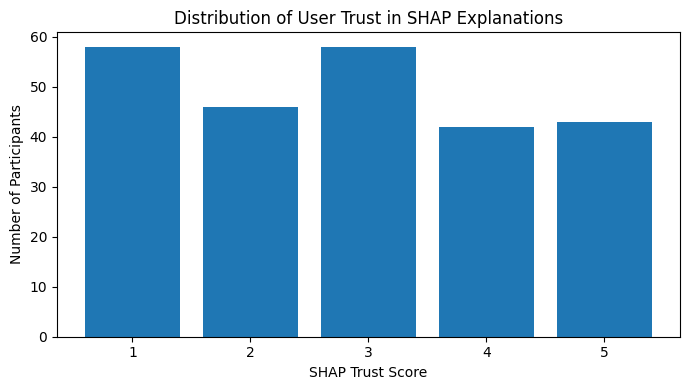

In [33]:
# ============================================================
# 32. DESCRIPTIVE TRUST STATISTICS
# ============================================================

trust_summary_rows = []

for variable, label in [
    ("Trust_SHAP_Likert", "SHAP Explanation Trust"),
    (
        "Trust_AI_With_Explanations_Score",
        "AI Trust With Explanations"
    )
]:
    if variable not in knust.columns:
        continue

    series = knust[variable].dropna()

    trust_summary_rows.append({
        "Measure": label,
        "N": len(series),
        "Mean": series.mean(),
        "Median": series.median(),
        "SD": series.std(ddof=1),
        "Minimum": series.min(),
        "Maximum": series.max()
    })

trust_summary = pd.DataFrame(trust_summary_rows)

print(trust_summary.round(3))

trust_summary.to_csv(
    OUTPUT_DIR / "Table_KNUST_Trust_Descriptive_Statistics.csv",
    index=False
)

# ============================================================
# 33. SHAP TRUST DISTRIBUTION
# ============================================================

if "Trust_SHAP_Likert" in knust.columns:
    trust_distribution = (
        knust["Trust_SHAP_Likert"]
        .value_counts()
        .sort_index()
    )

    print(trust_distribution)

    plt.figure(figsize=(7, 4))
    plt.bar(
        trust_distribution.index.astype(str),
        trust_distribution.values
    )

    plt.xlabel("SHAP Trust Score")
    plt.ylabel("Number of Participants")
    plt.title("Distribution of User Trust in SHAP Explanations")
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "Figure_SHAP_Trust_Distribution.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

In [34]:
# ============================================================
# 31B. MISSING-DATA, OUTLIER AND RUN-COMPLETION AUDIT
# ============================================================

# Explicit missing-value counts are reported rather than only describing
# the imputation policy.
phish_missing_by_column = phish_features.isna().sum()
uci_missing_by_column = X_uci_original.isna().sum()

missing_audit = pd.DataFrame({
    "Branch": ["PhishTank"] * len(phish_missing_by_column) + ["UCI"] * len(uci_missing_by_column),
    "Feature": list(phish_missing_by_column.index) + list(uci_missing_by_column.index),
    "Missing_Count": list(phish_missing_by_column.values) + list(uci_missing_by_column.values)
})
missing_audit.to_csv(OUTPUT_DIR / "Table_Missing_Value_Audit.csv", index=False)

print("PhishTank total missing feature values:", int(phish_features.isna().sum().sum()))
print("UCI total missing feature values before imputation:", int(X_uci_original.isna().sum().sum()))

# Outlier policy: no rows are removed solely because of extreme values.
# This is deliberate because Branch A is an anomaly-detection analysis and
# Branch B uses tree-based models. Extreme observations therefore remain in
# the data, while their counts are audited for transparency.
outlier_policy = pd.DataFrame({
    "Branch": ["PhishTank", "UCI"],
    "Policy": [
        "No outlier removal; Isolation Forest is intended to identify rare patterns.",
        "No outlier removal; tree-based classification is retained and exact duplicates are handled separately."
    ],
    "Reason": [
        "Removing rare observations before anomaly detection would alter the target of Branch A.",
        "Tree split rules do not require Gaussian outlier treatment; deleting observations could remove valid phishing patterns."
    ]
})
outlier_policy.to_csv(OUTPUT_DIR / "Table_Outlier_Policy.csv", index=False)
print("Outlier policy: no outlier rows removed; exact duplicate handling is separate.")

# Run-completion audit. These are populated from the authoritative per-seed
# tables after each configured experiment completes.
run_completion_rows = []
run_completion_rows.append({
    "Experiment": "Original XGBoost five-seed", "Expected_Runs": len(SEEDS),
    "Completed_Runs": len(legacy_xgb_results),
    "All_Completed": len(legacy_xgb_results) == len(SEEDS)
})
run_completion_rows.append({
    "Experiment": "De-duplicated XGBoost five-seed", "Expected_Runs": len(SEEDS),
    "Completed_Runs": len(xgb_runs_df),
    "All_Completed": len(xgb_runs_df) == len(SEEDS)
})
run_completion_rows.append({
    "Experiment": "Baseline classifiers", "Expected_Runs": len(SEEDS) * 4,
    "Completed_Runs": len(baseline_results),
    "All_Completed": len(baseline_results) == len(SEEDS) * 4
})
run_completion_rows.append({
    "Experiment": "Extended depth search", "Expected_Runs": len(SEEDS) * len(DEPTH_CANDIDATES),
    "Completed_Runs": len(depth_search),
    "All_Completed": len(depth_search) == len(SEEDS) * len(DEPTH_CANDIDATES)
})
run_completion = pd.DataFrame(run_completion_rows)
run_completion.to_csv(OUTPUT_DIR / "Table_Run_Completion_Audit.csv", index=False)
print("\nRun-completion audit:")
print(run_completion)
assert run_completion["All_Completed"].all(), "At least one configured experiment did not complete."

PhishTank total missing feature values: 0
UCI total missing feature values before imputation: 0
Outlier policy: no outlier rows removed; exact duplicate handling is separate.

Run-completion audit:
                        Experiment  Expected_Runs  Completed_Runs  \
0       Original XGBoost five-seed              5               5   
1  De-duplicated XGBoost five-seed              5               5   
2             Baseline classifiers             20              20   
3            Extended depth search             25              25   

   All_Completed  
0           True  
1           True  
2           True  
3           True  


                      Measure  Mean Score
0      SHAP Explanation Trust       2.862
1  AI Trust With Explanations       3.130


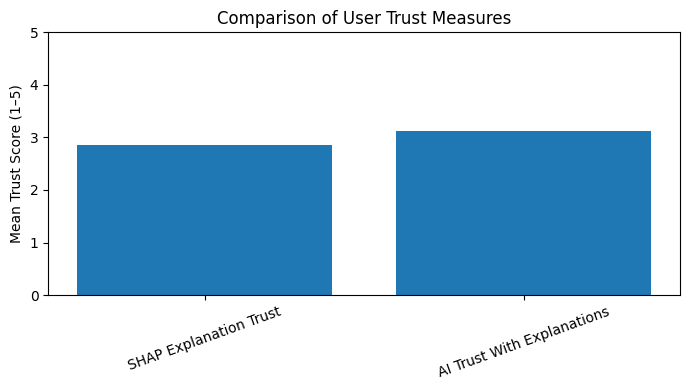

In [35]:
# ============================================================
# 34. TRUST COMPARISON
# ============================================================

comparison_rows = []

if "Trust_SHAP_Likert" in knust.columns:
    comparison_rows.append({
        "Measure": "SHAP Explanation Trust",
        "Mean Score": knust["Trust_SHAP_Likert"].mean()
    })

if "Trust_AI_With_Explanations_Score" in knust.columns:
    comparison_rows.append({
        "Measure": "AI Trust With Explanations",
        "Mean Score": (
            knust["Trust_AI_With_Explanations_Score"].mean()
        )
    })

trust_comparison = pd.DataFrame(comparison_rows)

print(trust_comparison.round(3))

if not trust_comparison.empty:
    plt.figure(figsize=(7, 4))

    plt.bar(
        trust_comparison["Measure"],
        trust_comparison["Mean Score"]
    )

    plt.ylabel("Mean Trust Score (1–5)")
    plt.title("Comparison of User Trust Measures")
    plt.xticks(rotation=20)
    plt.ylim(0, 5)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "Figure_Trust_Comparison.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

trust_comparison.to_csv(
    OUTPUT_DIR / "Table_Trust_Comparison.csv",
    index=False
)

  Preference  Count  Percentage
0       SHAP     68       27.53
1       LIME     63       25.51
2       Both     61       24.70
3    Neither     55       22.27


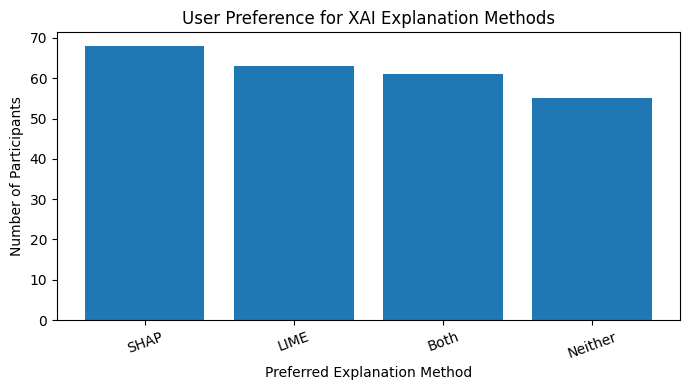

In [36]:
# ============================================================
# 35. PREFERRED EXPLANATION METHOD
# ============================================================

if "Preferred_Explanation" in knust.columns:
    preference = (
        knust["Preferred_Explanation"]
        .astype(str)
        .str.strip()
        .value_counts()
    )

    preference_table = pd.DataFrame({
        "Preference": preference.index,
        "Count": preference.values,
        "Percentage": (
            preference.values
            / preference.values.sum()
            * 100
        ).round(2)
    })

    print(preference_table)

    plt.figure(figsize=(7, 4))

    plt.bar(
        preference_table["Preference"],
        preference_table["Count"]
    )

    plt.xlabel("Preferred Explanation Method")
    plt.ylabel("Number of Participants")
    plt.title("User Preference for XAI Explanation Methods")
    plt.xticks(rotation=20)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "Figure_Preferred_Explanation_Method.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

    preference_table.to_csv(
        OUTPUT_DIR / "Table_Preferred_Explanation_Method.csv",
        index=False
    )

In [37]:
# ============================================================
# 36. SHAP TRUST CATEGORY
# ============================================================

if "Trust_SHAP_Likert" in knust.columns:
    knust["SHAP_Trust_Category"] = pd.cut(
        knust["Trust_SHAP_Likert"],
        bins=[0, 2, 3, 5],
        labels=[
            "Low Trust",
            "Neutral Trust",
            "High Trust"
        ],
        include_lowest=True
    )

    trust_categories = (
        knust["SHAP_Trust_Category"]
        .value_counts()
        .sort_index()
    )

    print(trust_categories)

    trust_categories.to_csv(
        OUTPUT_DIR / "Table_SHAP_Trust_Categories.csv"
    )

SHAP_Trust_Category
Low Trust        104
Neutral Trust     58
High Trust        85
Name: count, dtype: int64


In [38]:
# ============================================================
# 37. CHI-SQUARE TEST + CRAMER'S V
# ============================================================

from scipy.stats import chi2_contingency

if (
    "SHAP_Trust_Category" in knust.columns
    and "Preferred_Explanation" in knust.columns
):
    contingency = pd.crosstab(
        knust["SHAP_Trust_Category"],
        knust["Preferred_Explanation"]
    )

    print("Contingency table:")
    print(contingency)

    chi2, p_value, dof, expected = chi2_contingency(
        contingency
    )

    n = contingency.to_numpy().sum()
    min_dim = min(contingency.shape) - 1

    cramers_v = (
        np.sqrt(chi2 / (n * min_dim))
        if min_dim > 0
        else np.nan
    )

    print("Chi-square:", round(chi2, 4))
    print("Degrees of freedom:", dof)
    print("p-value:", round(p_value, 5))
    print("Cramer's V:", round(cramers_v, 4))

    chi_square_results = pd.DataFrame({
        "Statistic": [
            "Chi-square",
            "Degrees of freedom",
            "p-value",
            "Cramer's V"
        ],
        "Value": [
            chi2,
            dof,
            p_value,
            cramers_v
        ]
    })

    chi_square_results.to_csv(
        OUTPUT_DIR / "Table_ChiSquare_CramersV.csv",
        index=False
    )

Contingency table:
Preferred_Explanation  Both  LIME  Neither  SHAP
SHAP_Trust_Category                             
Low Trust                31    25       24    24
Neutral Trust            14    13       13    18
High Trust               16    25       18    26
Chi-square: 4.4814
Degrees of freedom: 6
p-value: 0.61182
Cramer's V: 0.0952


In [39]:
# ============================================================
# 38. PAIRED TRUST TEST, EFFECT SIZE, CONFIDENCE INTERVAL + SPEARMAN
# ============================================================

from scipy.stats import spearmanr, wilcoxon, rankdata

candidate_ai_trust_columns = [
    "AI_Trust_Score",
    "Trust_AI_With_Explanations_Score"
]

ai_column = next(
    (c for c in candidate_ai_trust_columns if c in knust.columns),
    None
)

if (
    "Trust_SHAP_Likert" in knust.columns
    and ai_column is not None
):
    paired = (
        knust[["Trust_SHAP_Likert", ai_column]]
        .apply(pd.to_numeric, errors="coerce")
        .dropna()
    )

    shap_scores = paired["Trust_SHAP_Likert"].to_numpy(dtype=float)
    ai_scores = paired[ai_column].to_numpy(dtype=float)
    differences = shap_scores - ai_scores

    # Wilcoxon signed-rank test for paired ordinal measures.
    wilcoxon_result = wilcoxon(
        shap_scores,
        ai_scores,
        alternative="two-sided",
        zero_method="wilcox",
        method="auto"
    )

    nonzero = differences[differences != 0]
    abs_ranks = rankdata(np.abs(nonzero), method="average")
    w_plus = float(abs_ranks[nonzero > 0].sum())
    w_minus = float(abs_ranks[nonzero < 0].sum())

    rank_biserial = (
        (w_plus - w_minus) / (w_plus + w_minus)
        if (w_plus + w_minus) > 0 else np.nan
    )

    # Bootstrap 95% CI for the paired mean difference.
    rng = np.random.default_rng(42)
    boot_means = np.empty(10000)

    for b in range(len(boot_means)):
        sample = rng.choice(
            differences,
            size=len(differences),
            replace=True
        )
        boot_means[b] = np.mean(sample)

    ci_low, ci_high = np.percentile(
        boot_means,
        [2.5, 97.5]
    )

    print("Paired trust comparison:")
    print("N:", len(paired))
    print("SHAP-trust mean:", round(shap_scores.mean(), 4))
    print("Overall-AI-trust mean:", round(ai_scores.mean(), 4))
    print("Mean paired difference (SHAP - AI):", round(differences.mean(), 4))
    print("Wilcoxon statistic:", round(float(wilcoxon_result.statistic), 4))
    print("Wilcoxon p-value:", round(float(wilcoxon_result.pvalue), 6))
    print("Rank-biserial effect size:", round(rank_biserial, 4))
    print("95% bootstrap CI for mean paired difference:",
          (round(ci_low, 4), round(ci_high, 4)))

    paired_test_results = pd.DataFrame({
        "N": [len(paired)],
        "SHAP_Trust_Mean": [shap_scores.mean()],
        "AI_Trust_Mean": [ai_scores.mean()],
        "Mean_Paired_Difference": [differences.mean()],
        "Wilcoxon_Statistic": [float(wilcoxon_result.statistic)],
        "Wilcoxon_p": [float(wilcoxon_result.pvalue)],
        "Rank_Biserial": [rank_biserial],
        "CI95_Low": [ci_low],
        "CI95_High": [ci_high]
    })

    paired_test_results.to_csv(
        OUTPUT_DIR / "Table_Paired_Trust_Wilcoxon_Effect_CI.csv",
        index=False
    )

    # Spearman remains an association test and is not interpreted causally.
    rho, p_value = spearmanr(
        paired["Trust_SHAP_Likert"],
        paired[ai_column]
    )

    print("\nSpearman association:")
    print("rho:", round(rho, 4))
    print("p-value:", round(p_value, 6))
    print("N:", len(paired))

    spearman_results = pd.DataFrame({
        "Variable_1": ["Trust_SHAP_Likert"],
        "Variable_2": [ai_column],
        "Spearman_rho": [rho],
        "p_value": [p_value],
        "N": [len(paired)]
    })

    spearman_results.to_csv(
        OUTPUT_DIR / "Table_Spearman_Trust_Correlation.csv",
        index=False
    )

else:
    print(
        "Paired trust and Spearman analyses were not executed because "
        "the required survey columns were unavailable."
    )

Paired trust comparison:
N: 247
SHAP-trust mean: 2.8623
Overall-AI-trust mean: 3.1296
Mean paired difference (SHAP - AI): -0.2672
Wilcoxon statistic: 8631.5
Wilcoxon p-value: 0.048577
Rank-biserial effect size: -0.158
95% bootstrap CI for mean paired difference: (np.float64(-0.5182), np.float64(-0.0121))

Spearman association:
rho: -0.0298
p-value: 0.641038
N: 247


In [40]:

# ============================================================
# C7. MINIMUM DETECTABLE PAIRED DIFFERENCE
# SHAP-trust vs AI-trust
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats, optimize

# ------------------------------------------------------------
# 1. Output directory
# ------------------------------------------------------------
OUT = Path(OUTPUT_DIR)
OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Validate required columns
# ------------------------------------------------------------
ai_column = "Trust_AI_With_Explanations_Score"

required_columns = [
    "Trust_SHAP_Likert",
    ai_column
]

missing = [c for c in required_columns if c not in knust.columns]

if missing:
    raise KeyError(
        f"Missing required columns: {missing}. "
        "Run the survey-processing cells first."
    )

# ------------------------------------------------------------
# 3. Prepare complete paired observations
# ------------------------------------------------------------
paired = (
    knust[required_columns]
    .apply(pd.to_numeric, errors="coerce")
    .dropna()
)

shap_scores = paired["Trust_SHAP_Likert"].to_numpy(dtype=float)
ai_scores = paired[ai_column].to_numpy(dtype=float)

# Difference direction: SHAP trust minus AI trust
differences = shap_scores - ai_scores

n_pairs = len(differences)

if n_pairs < 2:
    raise ValueError(
        f"At least 2 complete pairs are required; found {n_pairs}."
    )

if not np.all(np.isfinite(differences)):
    raise ValueError("Non-finite paired differences were detected.")

sd_diff = float(np.std(differences, ddof=1))
mean_diff = float(np.mean(differences))

if not np.isfinite(sd_diff) or sd_diff <= 0:
    raise ValueError(
        "The paired differences have zero or invalid variance. "
        "MDD cannot be calculated."
    )

# ------------------------------------------------------------
# 4. Statistical parameters
# ------------------------------------------------------------
alpha = 0.05
target_power = 0.80

# ------------------------------------------------------------
# 5. Normal-approximation MDD
# ------------------------------------------------------------
z_alpha = stats.norm.ppf(1 - alpha / 2)
z_beta = stats.norm.ppf(target_power)

mdd_normal = (
    (z_alpha + z_beta) * sd_diff / np.sqrt(n_pairs)
)

# ------------------------------------------------------------
# 6. Non-central t MDD
# ------------------------------------------------------------
df_t = n_pairs - 1
t_crit = stats.t.ppf(1 - alpha / 2, df_t)
standard_error = sd_diff / np.sqrt(n_pairs)

def _power(delta):
    ncp = delta / standard_error

    return (
        stats.nct.sf(t_crit, df_t, ncp)
        + stats.nct.cdf(-t_crit, df_t, ncp)
    )

# Find an upper bound that reaches the target power
lower = 0.0
upper = max(2.0 * mdd_normal, standard_error)

for _ in range(100):
    if _power(upper) >= target_power:
        break
    upper *= 2.0
else:
    raise RuntimeError(
        "Unable to find an upper bound for the MDD calculation."
    )

mdd_t = optimize.brentq(
    lambda delta: _power(delta) - target_power,
    lower,
    upper
)

standardised_mdd = mdd_t / sd_diff

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------
print("=" * 65)
print("MINIMUM DETECTABLE PAIRED DIFFERENCE")
print("=" * 65)
print("Comparison                         : SHAP trust - AI trust")
print(f"AI-trust variable                 : {ai_column}")
print(f"Number of complete pairs          : {n_pairs}")
print(f"SD of paired differences          : {sd_diff:.4f}")
print(f"Significance level (alpha)        : {alpha:.2f}")
print(f"Target statistical power          : {target_power:.2f}")
print(f"MDD, normal approximation         : {mdd_normal:.4f} Likert points")
print(f"MDD, non-central t                : {mdd_t:.4f} Likert points")
print(f"Observed mean paired difference   : {mean_diff:.4f}")
print(f"Standardised MDD (Cohen's dz)     : {standardised_mdd:.4f}")

print(
    "\nInterpretation: MDD is the approximate minimum absolute "
    "population mean paired difference detectable at the specified "
    "significance level and power using a two-sided paired t-test."
)
print(
    "Note: If the primary inferential test is the Wilcoxon "
    "signed-rank test, this paired-t MDD is a planning approximation."
)

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------
mdd_results = pd.DataFrame({
    "AI_Trust_Variable": [ai_column],
    "N_pairs": [n_pairs],
    "SD_paired_differences": [sd_diff],
    "Alpha": [alpha],
    "Power": [target_power],
    "MDD_normal": [mdd_normal],
    "MDD_exact_t": [mdd_t],
    "Observed_mean_difference": [mean_diff],
    "Standardised_MDD_dz": [standardised_mdd]
})

output_file = OUT / "Table_Minimum_Detectable_Difference.csv"

mdd_results.to_csv(output_file, index=False)

print(f"\nResults saved to: {output_file}")


MINIMUM DETECTABLE PAIRED DIFFERENCE
Comparison                         : SHAP trust - AI trust
AI-trust variable                 : Trust_AI_With_Explanations_Score
Number of complete pairs          : 247
SD of paired differences          : 2.0125
Significance level (alpha)        : 0.05
Target statistical power          : 0.80
MDD, normal approximation         : 0.3588 Likert points
MDD, non-central t                : 0.3602 Likert points
Observed mean paired difference   : -0.2672
Standardised MDD (Cohen's dz)     : 0.1790

Interpretation: MDD is the approximate minimum absolute population mean paired difference detectable at the specified significance level and power using a two-sided paired t-test.
Note: If the primary inferential test is the Wilcoxon signed-rank test, this paired-t MDD is a planning approximation.

Results saved to: revised_outputs/Table_Minimum_Detectable_Difference.csv


In [41]:
# ============================================================
# 38B. TRUST-INCREASE PROPORTION CI + RF VS XGBOOST PAIRED TEST
# ============================================================

# 46.5% was previously reported descriptively. Add an exact 95% binomial
# confidence interval so the uncertainty around the proportion is explicit.
if "Trust_AI_With_Explanations_Score" in knust.columns and "Trust_SHAP_Likert" in knust.columns:
    paired_trust = knust[["Trust_SHAP_Likert", "Trust_AI_With_Explanations_Score"]].apply(
        pd.to_numeric, errors="coerce"
    ).dropna()
    increased = int((paired_trust["Trust_SHAP_Likert"] > paired_trust["Trust_AI_With_Explanations_Score"]).sum())
    unchanged = int((paired_trust["Trust_SHAP_Likert"] == paired_trust["Trust_AI_With_Explanations_Score"]).sum())
    decreased = int((paired_trust["Trust_SHAP_Likert"] < paired_trust["Trust_AI_With_Explanations_Score"]).sum())
    n_pair = len(paired_trust)
    prop = increased / n_pair if n_pair else np.nan
    bt = binomtest(increased, n_pair, p=0.5) if n_pair else None
    ci = bt.proportion_ci(confidence_level=0.95, method="wilson") if bt else None

    trust_increase_ci = pd.DataFrame({
        "N": [n_pair], "Increased_n": [increased], "Increased_Percent": [100*prop],
        "Unchanged_n": [unchanged], "Decreased_n": [decreased],
        "CI95_Low": [100*ci.low if ci else np.nan],
        "CI95_High": [100*ci.high if ci else np.nan]
    })
    print("Trust increased:", increased, "of", n_pair, f"({100*prop:.2f}%)")
    print("95% Wilson CI:", (100*ci.low, 100*ci.high) if ci else None)
    trust_increase_ci.to_csv(OUTPUT_DIR / "Table_Trust_Increased_Proportion_CI.csv", index=False)

# Random Forest vs XGBoost: five paired seed-level accuracy observations.
# With only five pairs, the test is explicitly treated as descriptive/supporting
# evidence rather than as a strong population-level inferential claim.
if set(["Random Forest", "XGBoost"]).issubset(set(baseline_results["Model"])):
    rf = baseline_results[baseline_results["Model"] == "Random Forest"].set_index("Seed")["Accuracy"]
    xgb_acc = baseline_results[baseline_results["Model"] == "XGBoost"].set_index("Seed")["Accuracy"]
    paired_acc = pd.concat([rf.rename("RF"), xgb_acc.rename("XGBoost")], axis=1).dropna()
    if len(paired_acc) >= 2:
        rf_xgb_w = wilcoxon(paired_acc["RF"], paired_acc["XGBoost"], alternative="two-sided", method="auto")
        deltas = paired_acc["RF"] - paired_acc["XGBoost"]
        nonzero = deltas[deltas != 0]
        ranks = rankdata(np.abs(nonzero), method="average")
        rb = ((ranks[nonzero > 0].sum() - ranks[nonzero < 0].sum()) /
              (ranks[nonzero > 0].sum() + ranks[nonzero < 0].sum())) if len(nonzero) else np.nan
        rf_xgb_test = pd.DataFrame({
            "N_Paired_Seeds": [len(paired_acc)],
            "Mean_Accuracy_Difference_RF_minus_XGB": [deltas.mean()],
            "Min_Difference": [deltas.min()], "Max_Difference": [deltas.max()],
            "Wilcoxon_Statistic": [float(rf_xgb_w.statistic)],
            "Wilcoxon_p": [float(rf_xgb_w.pvalue)],
            "Rank_Biserial": [rb]
        })
        print("\nRF vs XGBoost paired seed-level accuracy:")
        print(rf_xgb_test.round(5))
        rf_xgb_test.to_csv(OUTPUT_DIR / "Table_RF_vs_XGBoost_Paired_Seed_Test.csv", index=False)

Trust increased: 92 of 247 (37.25%)
95% Wilson CI: (np.float64(31.456187312965334), np.float64(43.4283472068911))

RF vs XGBoost paired seed-level accuracy:
   N_Paired_Seeds  Mean_Accuracy_Difference_RF_minus_XGB  Min_Difference  \
0               5                               -0.00332        -0.00873   

   Max_Difference  Wilcoxon_Statistic  Wilcoxon_p  Rank_Biserial  
0         0.00175                 1.0        0.25           -0.8  


In [42]:
# ============================================================
# 38C. DIRECT ITEM: TRUST_AI_AFTER_SHAP  (VERIFY 3 · C4, Table 15b)
# ============================================================
from scipy.stats import chi2_contingency

def wilson_ci(k, n, z=1.959964):
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

after = knust["Trust_AI_After_SHAP"].astype(str).str.strip()
n_after = int(after.isin(["Yes", "No"]).sum())
rows = []
for answer in ["Yes", "No"]:
    k = int((after == answer).sum())
    lo, hi = wilson_ci(k, n_after)
    rows.append({"Response": answer, "n": k, "Percent": round(100 * k / n_after, 2),
                 "CI95_Low_%": round(100 * lo, 2), "CI95_High_%": round(100 * hi, 2)})
table_15b = pd.DataFrame(rows)
print("Table 15b. Trust_AI_After_SHAP (asked directly after the SHAP and LIME items)")
print(table_15b.to_string(index=False))
print(f"Valid answers: {n_after}; other/missing: {len(after) - n_after}")
table_15b.to_csv(OUTPUT_DIR / "Table_Trust_AI_After_SHAP.csv", index=False)

if "SHAP_Trust_Category" in knust.columns:
    ct = pd.crosstab(knust["SHAP_Trust_Category"], after.where(after.isin(["Yes", "No"])))
    stat, p, dof, _ = chi2_contingency(ct)
    v = np.sqrt(stat / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
    print("\nSHAP-trust category x Trust_AI_After_SHAP")
    print(ct)
    print(f"Chi-square = {stat:.4f}, df = {dof}, p = {p:.5f}, Cramer's V = {v:.4f}")
    ct.to_csv(OUTPUT_DIR / "Table_Trust_AI_After_SHAP_by_SHAP_Trust.csv")
    pd.DataFrame({"Chi2": [stat], "df": [dof], "p": [p], "Cramers_V": [v]}).to_csv(
        OUTPUT_DIR / "Table_Trust_AI_After_SHAP_ChiSquare.csv", index=False)


Table 15b. Trust_AI_After_SHAP (asked directly after the SHAP and LIME items)
Response   n  Percent  CI95_Low_%  CI95_High_%
     Yes 111    44.94       38.86        51.17
      No 136    55.06       48.83        61.14
Valid answers: 247; other/missing: 0

SHAP-trust category x Trust_AI_After_SHAP
Trust_AI_After_SHAP  No  Yes
SHAP_Trust_Category         
Low Trust            55   49
Neutral Trust        37   21
High Trust           44   41
Chi-square = 2.3596, df = 2, p = 0.30733, Cramer's V = 0.0977


In [43]:
# ============================================================
# JOBLIB IMPORT + VERSION
# ============================================================

import joblib

JOBLIB_VERSION = joblib.__version__

print("============================================================")
print("JOBLIB ENVIRONMENT")
print("============================================================")
print("joblib version:", JOBLIB_VERSION)

# ============================================================
# 39. SAVE FINAL MODEL ARTIFACTS + TRACEABILITY CHECKS
# ============================================================

joblib.dump(
    final_model,
    OUTPUT_DIR / "UCI_XGBoost_Phishing_Model.pkl"
)

joblib.dump(
    final_imputer,
    OUTPUT_DIR / "UCI_XGBoost_Imputer.pkl"
)

joblib.dump(
    X_uci_raw.columns.tolist(),
    OUTPUT_DIR / "UCI_Feature_Names.pkl"
)

final_runs_df.to_csv(
    OUTPUT_DIR / "Table_Final_Vanilla_Five_Seed_Results.csv",
    index=False
)

final_summary.to_csv(
    OUTPUT_DIR / "Table_Final_Vanilla_Mean_SD.csv"
)

print(
    "Final model and result tables saved to:",
    OUTPUT_DIR.resolve()
)

# ============================================================
# 40. FINAL SANITY CHECKS
# ============================================================

print("========== FINAL SANITY CHECK ==========")

print("UCI source rows:", len(uci))
print("UCI rows after de-duplication:", len(X_uci_raw))
print("UCI features:", X_uci_raw.shape[1])
print("UCI legitimate:", int((y_uci == 0).sum()))
print("UCI phishing:", int((y_uci == 1).sum()))

assert X_uci_raw.shape[1] == 30
assert len(X_uci_raw) == len(y_uci)
assert set(y_uci.unique()).issubset({0, 1})

assert len(SEEDS) == 5
assert len(set(SEEDS)) == 5
assert tn + fp + fn + tp == len(y_test_final)
assert stability_long["Seed"].nunique() == 5
assert set(stability_long["Seed"]) == set(SEEDS)
assert feature_duplicate_count >= 0
assert feature_label_duplicate_count >= 0

print("Selected depth:", SELECTED_DEPTH)
print("SMOTE in final model: OFF")
print("Exact duplicate feature rows audited:", feature_duplicate_count)
print("Exact duplicate feature+label rows audited:", feature_label_duplicate_count)
print("No unsupported UCI/PhishTank feature fusion: True")
print("SHAP/LIME are post-hoc and do not alter predictions: True")
print("Final evaluation set is de-duplicated before splitting: True")
print("All configured five-seed final runs completed: True")
print("Sanity checks completed successfully.")

JOBLIB ENVIRONMENT
joblib version: 1.6.0
Final model and result tables saved to: /kaggle/working/revised_outputs
========== FINAL SANITY CHECK ==========
UCI source rows: 11055
UCI rows after de-duplication: 5721
UCI features: 30
UCI legitimate: 2766
UCI phishing: 2955
Selected depth: 6
SMOTE in final model: OFF
Exact duplicate feature rows audited: 5270
Exact duplicate feature+label rows audited: 5206
No unsupported UCI/PhishTank feature fusion: True
SHAP/LIME are post-hoc and do not alter predictions: True
Final evaluation set is de-duplicated before splitting: True
All configured five-seed final runs completed: True
Sanity checks completed successfully.


In [44]:
# ============================================================
# OUTPUT MANIFEST: every figure/table file produced by this run
# ============================================================
import hashlib
from pathlib import Path
import pandas as pd

rows = []
for d in sorted({Path(OUTPUT_DIR).resolve(), Path("/kaggle/working/outputs").resolve(), Path("/kaggle/working/revised_outputs").resolve()}):
    if not d.exists():
        continue
    for p in sorted(d.rglob("*")):
        if p.is_file():
            rows.append({
                "Directory": str(d),
                "File": p.name,
                "Bytes": p.stat().st_size,
                "SHA256_first16": hashlib.sha256(p.read_bytes()).hexdigest()[:16],
            })
manifest = pd.DataFrame(rows)
print(manifest.to_string(index=False))
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
manifest.to_csv(Path(OUTPUT_DIR) / "Output_Manifest.csv", index=False)


                      Directory                                                File   Bytes   SHA256_first16
/kaggle/working/revised_outputs                 Figure_Confusion_Matrix_XGBoost.png  192199 4af90a9616e79a18
/kaggle/working/revised_outputs      Figure_Confusion_Matrix_XGBoost_Normalized.png  224316 b6e0b2a474b59b36
/kaggle/working/revised_outputs                   Figure_LIME_Local_Explanation.png  388887 1e5e826dd0704fe5
/kaggle/working/revised_outputs              Figure_MultiSeed_Stability_Boxplot.png  196846 11c5290223dbc910
/kaggle/working/revised_outputs           Figure_MultiSeed_Stability_Violinplot.png  250064 264078512ada57af
/kaggle/working/revised_outputs           Figure_PhishTank_Anomaly_Distribution.png  175004 851126365d32b0be
/kaggle/working/revised_outputs               Figure_PhishTank_Feature_Variance.png  230347 33fe315c03ce074c
/kaggle/working/revised_outputs             Figure_Preferred_Explanation_Method.png  225710 60e1462ad5f28964
/kaggle/working/rev